# Machine Learning-Based Detection and Early Identification of Soft-Failures in Optical Fiber Networks

**MSc Data Science dissertation (UEL-DS-7010) - experimental notebook.**

This notebook reproduces, end to end, every number, table and figure reported in the
Methodology and Results chapters. It uses the public *optical-failure-dataset*
(Silva, Pacini, Sgambelluri & Valcarenghi; ARNO testbed, Scuola Superiore Sant'Anna).

Structure
1. Setup, data acquisition and verification of the repository against its README and the paper
2. Alignment of transponder and amplifier records into polling cycles
3. Exploratory data analysis (EDA) and failure-event characterisation (soft vs hard)
4. Causal feature engineering (F1 raw, F2 rolling windows) and telemetry views
5. Targets: detection (now-cast) and early-warning horizons (H = 10/30/60/120 s)
6. Chronological split with embargo + blocked time-series CV
7. Baselines (majority class, conventional fixed thresholds) and ML models (LR, RF, SVM)
8. Class-imbalance strategies (none, class_weight, SMOTE, threshold tuning)
9. Early identification: event-level detection delay, lead time vs thresholds, horizon prediction
10. Temporal leakage: random stratified split vs chronological split
11. Robustness: rolling-origin (forward-chaining) evaluation and random-forest seeds
12. Interpretability (permutation importance, standardised LR coefficients) and inference cost
13. Hard-failure dataset: replication, soft-degradation regime, benchmark vs Silva et al. (2022)

All rolling features are causal (past-only), all scalers/resamplers are fitted on
training folds only, and the test block is used once per configuration.

## 1. Setup

In [1]:
import os
import sys
import json
import time
import subprocess
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

import sklearn
import imblearn
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, balanced_accuracy_score,
                             confusion_matrix, f1_score, fbeta_score, matthews_corrcoef,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold, TimeSeriesSplit,
                                     train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

warnings.filterwarnings('ignore', category=ConvergenceWarning)
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)

# ---------------------------------------------------------------- paths (change if needed)
DATA_DIR = Path('../../data/optical-failure-dataset')   # where the dataset repository lives
REPO_URL = 'https://github.com/Network-And-Services/optical-failure-dataset'
FIG_DIR = Path('../figures')
TAB_DIR = Path('../tables')
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------------- global experimental constants
SEED = 42                      # global seed (splits, SMOTE, RF during tuning)
RF_SEEDS = [0, 1, 2, 3, 4]     # seeds for RF mean +/- sd reporting
N_JOBS = 2                     # CPU cores available
WINDOWS = (15, 30, 60)         # causal rolling-window lengths in seconds
HORIZONS_SOFT = (10, 30, 60, 120)   # early-warning horizons H (s), soft dataset
HORIZONS_HARD = (10, 20)            # hard dataset (events every ~51 s, so H must be short)
EMBARGO_S = 60                 # records removed on each side of a split boundary (>= longest window)
CV_GAP_S = 120                 # gap between CV train and CV validation folds (>= window and horizon)
TAIL_S = 10                    # alarms up to 10 s after an event end are attributed to it (receiver lag)
FEC_HD = 3.8e-3                # pre-FEC BER limit of hard-decision FEC (7 % OH, ITU-T G.975.1 class)
FEC_SD = 2.0e-2                # pre-FEC BER limit typical of soft-decision FEC (~20 % OH)
OSNR_MARGIN_DB = 3.0           # conventional OSNR-margin alarm: 3 dB below the normal median
FAST = os.environ.get('SFD_FAST', '0') == '1'   # quick smoke-test mode (smaller grids)

np.random.seed(SEED)
T_START = time.perf_counter()

# ---------------------------------------------------------------- figure style (light, navy text, CVD-safe)
NAVY = '#1f2a44'
GREY = '#8a8f98'
LIGHTGREY = '#d5d9e0'
# Categorical palette (validated for colour-vision deficiency on a light surface, fixed order)
PAL = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
C_NORMAL, C_FAIL = PAL[0], PAL[1]
MODEL_COLORS = {'Dummy': GREY, 'Threshold': PAL[3], 'LR': PAL[0], 'RF': PAL[1], 'SVM': PAL[2]}
SPLIT_COLORS = {'train': PAL[0], 'val': PAL[2], 'test': PAL[1], 'embargo': LIGHTGREY}
plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white', 'savefig.facecolor': 'white',
    'text.color': NAVY, 'axes.labelcolor': NAVY, 'axes.titlecolor': NAVY,
    'xtick.color': NAVY, 'ytick.color': NAVY, 'axes.edgecolor': '#9aa3b2',
    'font.family': 'DejaVu Sans', 'font.size': 10, 'axes.titlesize': 11, 'axes.labelsize': 10,
    'legend.fontsize': 8.5, 'legend.frameon': False, 'axes.grid': True, 'grid.color': '#e6e9ee',
    'grid.linewidth': 0.6, 'axes.spines.top': False, 'axes.spines.right': False,
    'savefig.dpi': 250, 'figure.dpi': 110, 'lines.linewidth': 1.4,
})
DIVERGING = LinearSegmentedColormap.from_list('bwo', [PAL[0], '#f4f5f7', PAL[1]])


def savefig(fig, name):
    """Save a figure as PNG (250 dpi, white background) in FIG_DIR."""
    path = FIG_DIR / f'{name}.png'
    fig.savefig(path, dpi=250, bbox_inches='tight', facecolor='white')
    print('saved', path)


def save_table(df, name, index=False):
    path = TAB_DIR / f'{name}.csv'
    df.to_csv(path, index=index, float_format='%.6g')
    print('saved', path)


SUMMARY = {}     # key numbers collected along the way (written to tables/results_summary.json)

print('python', sys.version.split()[0], '| numpy', np.__version__, '| pandas', pd.__version__,
      '| scikit-learn', sklearn.__version__, '| imbalanced-learn', imblearn.__version__,
      '| matplotlib', matplotlib.__version__)

python 3.13.17 | numpy 2.5.3 | pandas 3.0.5 | scikit-learn 1.9.1 | imbalanced-learn 0.14.2 | matplotlib 3.11.2


### 1.1 Data acquisition
The dataset repository is cloned (read-only use) if it is not already present. The CSV files
are treated as untrusted data: they are only parsed with `pandas.read_csv`.

In [2]:
if not (DATA_DIR / 'SoftFailure_dataset.csv').exists():
    DATA_DIR.parent.mkdir(parents=True, exist_ok=True)
    subprocess.run(['git', 'clone', REPO_URL, str(DATA_DIR)], check=True)
try:
    COMMIT = subprocess.run(['git', '-C', str(DATA_DIR), 'log', '-1', '--format=%H %ad', '--date=iso'],
                            capture_output=True, text=True, check=True).stdout.strip()
except Exception as exc:  # repository downloaded as a zip, for example
    COMMIT = f'unknown ({exc})'
print('dataset commit:', COMMIT)
print(sorted(p.name for p in DATA_DIR.iterdir() if not p.name.startswith('.')))
SUMMARY['dataset_commit'] = COMMIT


def load_raw(name):
    """Load one dataset CSV. The Failure column is empty (NaN) for normal rows and 1 for failure rows."""
    df = pd.read_csv(DATA_DIR / f'{name}_dataset.csv')
    df['Failure'] = df['Failure'].fillna(0).astype(int)
    return df


RAW = {'soft': load_raw('SoftFailure'), 'hard': load_raw('HardFailure')}
RAW['soft'].head(8)

dataset commit: 7f0e9c0617fdde7f087de7214f38312ff7aaefd4 2022-02-16 10:13:30 +0100
['HardFailure_dataset.csv', 'README.md', 'SoftFailure_dataset.csv', 'testbed.jpg']


,Timestamp,Type,ID,BER,OSNR,InputPower,OutputPower,Failure
0,1624457562,Devices,SPO1/18/11,2.310000e-08,38.6,NaN,NaN,0
1,1624457562,Infrastructure,Ampli1,NaN,NaN,-19.2,0.7,0
2,1624457562,Devices,SPO2/18/11,1.720000e-07,25.8,NaN,NaN,0
3,1624457562,Infrastructure,Ampli3,NaN,NaN,-16.7,0.8,0
4,1624457562,Infrastructure,Ampli2,NaN,NaN,-15.5,0.4,0
5,1624457562,Infrastructure,Ampli4,NaN,NaN,-22.8,0.7,0
6,1624457565,Devices,SPO1/18/11,2.310000e-08,38.6,NaN,NaN,0
7,1624457565,Devices,SPO2/18/11,1.710000e-07,25.6,NaN,NaN,0


### 1.2 Verification of the repository content against the README and the paper
The README states: samples every 3.5 s; six monitored entities (SPO1/18/11, SPO2/18/11, Ampli1-4);
a `Failure` flag marking records "gathered while the input power of Ampli1 is too low due to the
WSS configuration". The hard-failure dataset (10 h) has 6 h of normal operation, 2 h of variable
attenuation (from timestamp 1623416338) and 2 h with periodic 25 dB hard failures (from 1623423687).
The soft-failure dataset (8 h) has 4 h of sinusoidal variable attenuation and 4 h with periodic
10 dB soft failures (from 1624471536). We check each claim against the files.

In [3]:
PERIODS = {
    # name: list of (label, start_timestamp) - period boundaries from the README
    'soft': [('P1 variable attenuation (normal)', None), ('P2 periodic soft failures', 1624471536)],
    'hard': [('P1 normal, constant', None), ('P2 variable attenuation (normal)', 1623416338),
             ('P3 periodic hard failures', 1623423687)],
}
FAIL_START = {'soft': 1624471536, 'hard': 1623423687}   # start of the period containing failures
CALIB_END = FAIL_START                                   # failure-free data used to calibrate thresholds


def verify(df, name):
    rows = []
    for dev, g in df.groupby('ID'):
        g = g.sort_values('Timestamp')
        dt = g['Timestamp'].diff().dropna()
        rows.append({
            'dataset': name, 'ID': dev, 'Type': g['Type'].iloc[0], 'records': len(g),
            'first_utc': pd.to_datetime(g['Timestamp'].min(), unit='s'),
            'last_utc': pd.to_datetime(g['Timestamp'].max(), unit='s'),
            'dt_median_s': dt.median(), 'dt_mean_s': round(dt.mean(), 3), 'dt_p99_s': dt.quantile(0.99),
            'dt_max_s': dt.max(), 'duplicate_timestamps': int(g['Timestamp'].duplicated().sum()),
            'failure_records': int(g['Failure'].sum()),
            'missing_BER': int(g['BER'].isna().sum()), 'missing_OSNR': int(g['OSNR'].isna().sum()),
            'missing_InputPower': int(g['InputPower'].isna().sum()),
            'missing_OutputPower': int(g['OutputPower'].isna().sum()),
        })
    return pd.DataFrame(rows)


ver = pd.concat([verify(RAW[k], k) for k in RAW], ignore_index=True)
save_table(ver, 'tab01_raw_file_verification')
for k, df in RAW.items():
    span_h = (df['Timestamp'].max() - df['Timestamp'].min()) / 3600
    print(f"{k}: {len(df)} rows x {df.shape[1]} cols, span {span_h:.3f} h, "
          f"rows out of timestamp order: {(df['Timestamp'].diff() < 0).sum()}, "
          f"failure rows: {df['Failure'].sum()}")
    SUMMARY[f'{k}_rows'] = int(len(df))
    SUMMARY[f'{k}_span_h'] = round(float(span_h), 3)
ver

saved ../tables/tab01_raw_file_verification.csv


soft: 53697 rows x 8 cols, span 8.025 h, rows out of timestamp order: 4155, failure rows: 5126
hard: 65733 rows x 8 cols, span 9.925 h, rows out of timestamp order: 5208, failure rows: 2485


,dataset,ID,Type,records,first_utc,last_utc,dt_median_s,dt_mean_s,dt_p99_s,dt_max_s,duplicate_timestamps,failure_records,missing_BER,missing_OSNR,missing_InputPower,missing_OutputPower
0,soft,Ampli1,Infrastructure,8946,2021-06-23 14:12:42,2021-06-23 22:14:11,3.0,3.230,4.0,14.0,0,856,8946,8946,0,0
1,soft,Ampli2,Infrastructure,8946,2021-06-23 14:12:42,2021-06-23 22:14:11,3.0,3.230,4.0,13.0,0,856,8946,8946,0,0
2,soft,Ampli3,Infrastructure,8953,2021-06-23 14:12:42,2021-06-23 22:14:11,3.0,3.227,4.0,14.0,0,852,8953,8953,0,0
3,soft,Ampli4,Infrastructure,8953,2021-06-23 14:12:42,2021-06-23 22:14:11,3.0,3.227,4.0,14.0,0,854,8953,8953,0,0
4,soft,SPO1/18/11,Devices,8946,2021-06-23 14:12:42,2021-06-23 22:14:11,3.0,3.230,4.0,14.0,0,858,0,0,8946,8946
5,soft,SPO2/18/11,Devices,8953,2021-06-23 14:12:42,2021-06-23 22:14:11,3.0,3.227,4.0,13.0,0,850,0,0,8953,8953
6,hard,Ampli1,Infrastructure,10962,2021-06-11 06:57:15,2021-06-11 16:52:45,3.0,3.260,4.0,361.0,0,413,10962,10962,0,0
7,hard,Ampli2,Infrastructure,10962,2021-06-11 06:57:15,2021-06-11 16:52:45,3.0,3.260,4.0,361.0,0,413,10962,10962,0,0
8,hard,Ampli3,Infrastructure,10949,2021-06-11 06:57:15,2021-06-11 16:52:45,3.0,3.264,4.0,361.0,0,415,10949,10949,0,0
9,hard,Ampli4,Infrastructure,10949,2021-06-11 06:57:15,2021-06-11 16:52:45,3.0,3.264,4.0,360.0,0,413,10949,10949,0,0


**Label semantics check.** The README says the flag marks low Ampli1 input power. We cross-tabulate
the Ampli1 input power against the flag on the Ampli1 rows.

In [4]:
for k, df in RAW.items():
    a1 = df[df['ID'] == 'Ampli1']
    ct = pd.crosstab(a1['InputPower'], a1['Failure'])
    fail_levels = sorted(a1.loc[a1['Failure'] == 1, 'InputPower'].unique())
    max_normal = a1.loc[a1['Failure'] == 0, 'InputPower'].min()
    print(f"{k}: Ampli1 input power on failure rows = {fail_levels} dBm; "
          f"lowest Ampli1 input power on normal rows = {max_normal} dBm")
    SUMMARY[f'{k}_label_pin_levels'] = [float(v) for v in fail_levels]
    SUMMARY[f'{k}_lowest_normal_pin'] = float(max_normal)
# constant columns per device (zero variance) - these carry no information
const = []
for k, df in RAW.items():
    for dev, g in df.groupby('ID'):
        for c in ['BER', 'OSNR', 'InputPower', 'OutputPower']:
            v = g[c].dropna()
            if len(v) and v.nunique() == 1:
                const.append({'dataset': k, 'ID': dev, 'column': c, 'constant_value': v.iloc[0]})
const = pd.DataFrame(const)
save_table(const, 'tab02_constant_columns')
const

soft: Ampli1 input power on failure rows = [np.float64(-29.1), np.float64(-29.0)] dBm; lowest Ampli1 input power on normal rows = -28.8 dBm
hard: Ampli1 input power on failure rows = [np.float64(-38.0)] dBm; lowest Ampli1 input power on normal rows = -35.9 dBm
saved ../tables/tab02_constant_columns.csv


,dataset,ID,column,constant_value
0,soft,Ampli1,OutputPower,0.7
1,soft,Ampli2,OutputPower,0.4
2,soft,Ampli4,OutputPower,0.7
3,hard,Ampli1,OutputPower,0.7
4,hard,Ampli2,OutputPower,0.4
5,hard,Ampli4,OutputPower,0.7


## 2. Alignment of transponder and amplifier records

Each entity is polled roughly every 3.2 s, with integer-second timestamps that differ by up to
2 s between entities in the same polling cycle (SPO1 controls Ampli1/2 and SPO2 controls Ampli3/4,
so the two groups are collected by separate polls). We anchor every record on the **SPO2/18/11
polling instant** (the coherent receiver at the end of the 240 km impaired link) and attach the
reading of each other entity whose timestamp is nearest within +/-2 s (same polling cycle).
Unmatched readings are carried forward from the previous cycle (last observation carried forward,
which is what an online collector would have). The operational decision time of a cycle is the
latest timestamp among the six readings (at most 2 s after the anchor); no reading from a later
cycle is ever used. The target `y` is the `Failure` flag of the Ampli1 reading in the same cycle,
because the README defines the flag from the Ampli1 input power.

In [5]:
DEV_SHORT = {'SPO1/18/11': 'SPO1', 'SPO2/18/11': 'SPO2', 'Ampli1': 'A1', 'Ampli2': 'A2',
             'Ampli3': 'A3', 'Ampli4': 'A4'}


def align(df, tol=2):
    anchor = df[df['ID'] == 'SPO2/18/11'].sort_values('Timestamp')
    A = anchor[['Timestamp', 'BER', 'OSNR', 'Failure']].rename(
        columns={'Timestamp': 't', 'BER': 'SPO2_BER', 'OSNR': 'SPO2_OSNR', 'Failure': 'flag_SPO2'})
    A = A.reset_index(drop=True)
    A['t_SPO2'] = A['t']
    info = []
    for dev, short in DEV_SHORT.items():
        if short == 'SPO2':
            continue
        g = df[df['ID'] == dev].sort_values('Timestamp')
        if short.startswith('SPO'):
            ren = {'BER': f'{short}_BER', 'OSNR': f'{short}_OSNR'}
        else:
            ren = {'InputPower': f'{short}_Pin', 'OutputPower': f'{short}_Pout'}
        g = g[['Timestamp', *ren.keys(), 'Failure']].rename(
            columns={**ren, 'Timestamp': f't_{short}', 'Failure': f'flag_{short}'})
        A = pd.merge_asof(A, g, left_on='t', right_on=f't_{short}', direction='nearest', tolerance=tol)
        matched = A[f't_{short}']
        info.append({'device': short, 'device_records': len(g), 'matched_cycles': int(matched.notna().sum()),
                     'unmatched_cycles_ffilled': int(matched.isna().sum()),
                     'readings_used_twice': int(matched.dropna().duplicated().sum()),
                     'readings_never_used': int(len(g) - matched.dropna().nunique()),
                     'offset_s_distribution': (matched - A['t']).value_counts().sort_index().to_dict()})
    A = A.ffill().bfill()   # LOCF for the few unmatched cycles (bfill only affects the very first cycle)
    A['y'] = A['flag_A1'].astype(int)
    tcols = [c for c in A.columns if c.startswith('t_')]
    A['t_decision'] = A[tcols].max(axis=1)
    A['decision_lag_s'] = A['t_decision'] - A['t']
    return A, pd.DataFrame(info)


ALIGNED, ALIGN_INFO = {}, {}
for k in RAW:
    ALIGNED[k], ALIGN_INFO[k] = align(RAW[k])
    agree = {d: float((ALIGNED[k][f'flag_{d}'] == ALIGNED[k]['y']).mean()) for d in DEV_SHORT.values()}
    print(f"{k}: aligned cycles = {len(ALIGNED[k])}, failure cycles = {ALIGNED[k]['y'].sum()}, "
          f"max decision lag = {ALIGNED[k]['decision_lag_s'].max():.0f} s")
    print('   agreement of each device flag with the Ampli1 flag:', {d: round(v, 4) for d, v in agree.items()})
    SUMMARY[f'{k}_aligned_cycles'] = int(len(ALIGNED[k]))
    SUMMARY[f'{k}_failure_cycles'] = int(ALIGNED[k]['y'].sum())
    SUMMARY[f'{k}_flag_agreement'] = {d: round(v, 4) for d, v in agree.items()}
ai = pd.concat([ALIGN_INFO[k].assign(dataset=k) for k in ALIGN_INFO], ignore_index=True)
ai['offset_s_distribution'] = ai['offset_s_distribution'].astype(str)
save_table(ai, 'tab03_alignment_summary')
ai

soft: aligned cycles = 8953, failure cycles = 854, max decision lag = 2 s
   agreement of each device flag with the Ampli1 flag: {'SPO1': 0.996, 'SPO2': 0.9955, 'A1': 1.0, 'A2': 0.9999, 'A3': 0.996, 'A4': 0.9996}


hard: aligned cycles = 10949, failure cycles = 410, max decision lag = 2 s
   agreement of each device flag with the Ampli1 flag: {'SPO1': 0.9869, 'SPO2': 0.9848, 'A1': 1.0, 'A2': 0.9996, 'A3': 0.9879, 'A4': 0.9932}
saved ../tables/tab03_alignment_summary.csv


,device,device_records,matched_cycles,unmatched_cycles_ffilled,readings_used_twice,readings_never_used,offset_s_distribution,dataset
0,SPO1,8946,8933,20,47,60,"{-2.0: 55, -1.0: 293, 0.0: 8276, 1.0: 308, 2.0...",soft
1,A1,8946,8934,19,52,64,"{-2.0: 61, -1.0: 236, 0.0: 7721, 1.0: 915, 2.0...",soft
2,A2,8946,8935,18,50,61,"{-2.0: 62, -1.0: 233, 0.0: 7179, 1.0: 1461}",soft
3,A3,8953,8953,0,0,0,"{0: 8224, 1: 729}",soft
4,A4,8953,8953,0,0,0,"{0: 7608, 1: 1345}",soft
5,SPO1,10962,10938,11,87,111,"{-2.0: 93, -1.0: 459, 0.0: 9734, 1.0: 645, 2.0...",hard
6,A1,10962,10937,12,96,121,"{-2.0: 105, -1.0: 392, 0.0: 9085, 1.0: 1348, 2...",hard
7,A2,10962,10937,12,110,135,"{-2.0: 118, -1.0: 367, 0.0: 8487, 1.0: 1959, 2...",hard
8,A3,10949,10949,0,0,0,"{0: 10058, 1: 889, 2: 2}",hard
9,A4,10949,10948,1,0,1,"{0.0: 9292, 1.0: 1649, 2.0: 7}",hard


### 2.1 Derived signals
* Pre-FEC BER spans several decades, so it is modelled as `log10(BER)`.
* In the hard dataset the receiver sometimes reports BER = 0 and/or OSNR = 0 while the signal is
  lost (loss of signal / loss of lock). A pre-FEC BER of exactly 0 is physically impossible at
  100 Gb/s with a working receiver, so such readings are flagged with `SPO2_LOS = 1` and their
  log10(BER) is set to log10(0.5) (no information = random bits). OSNR is kept as reported.
* Columns that are constant over a whole dataset (Ampli1/2/4 output power) are dropped.

In [6]:
def add_signals(A):
    A = A.copy()
    for s in ['SPO1', 'SPO2']:
        ber = A[f'{s}_BER'].astype(float)
        los = (ber <= 0) | (A[f'{s}_OSNR'] <= 0)
        A[f'{s}_LOS'] = los.astype(int)
        A[f'{s}_logBER'] = np.log10(ber.where(ber > 0, 0.5))
    return A


SIGNALS_ALL = ['A1_Pin', 'A1_Pout', 'A2_Pin', 'A2_Pout', 'A3_Pin', 'A3_Pout', 'A4_Pin', 'A4_Pout',
               'SPO1_logBER', 'SPO1_OSNR', 'SPO1_LOS', 'SPO2_logBER', 'SPO2_OSNR', 'SPO2_LOS']
SIGNALS = {}
for k in ALIGNED:
    ALIGNED[k] = add_signals(ALIGNED[k])
    keep = [s for s in SIGNALS_ALL if ALIGNED[k][s].nunique() > 1]
    SIGNALS[k] = keep
    print(k, 'informative signals:', keep, '| dropped constant:', sorted(set(SIGNALS_ALL) - set(keep)))
    A = ALIGNED[k]
    A['period'] = PERIODS[k][0][0]
    for label, start in PERIODS[k][1:]:
        A.loc[A['t'] >= start, 'period'] = label
    A['hours'] = (A['t'] - A['t'].iloc[0]) / 3600

soft informative signals: ['A1_Pin', 'A2_Pin', 'A3_Pin', 'A3_Pout', 'A4_Pin', 'SPO1_logBER', 'SPO1_OSNR', 'SPO2_logBER', 'SPO2_OSNR'] | dropped constant: ['A1_Pout', 'A2_Pout', 'A4_Pout', 'SPO1_LOS', 'SPO2_LOS']
hard informative signals: ['A1_Pin', 'A2_Pin', 'A3_Pin', 'A3_Pout', 'A4_Pin', 'SPO1_logBER', 'SPO1_OSNR', 'SPO2_logBER', 'SPO2_OSNR', 'SPO2_LOS'] | dropped constant: ['A1_Pout', 'A2_Pout', 'A4_Pout', 'SPO1_LOS']


## 3. Exploratory data analysis
### 3.1 Sampling, time span, missing values and class balance

In [7]:
eda_rows = []
for k, A in ALIGNED.items():
    dt = np.diff(A['t'].values)
    for per, g in A.groupby('period', sort=False):
        eda_rows.append({'dataset': k, 'period': per, 'start_utc': pd.to_datetime(g['t'].min(), unit='s'),
                         'end_utc': pd.to_datetime(g['t'].max(), unit='s'),
                         'duration_h': round((g['t'].max() - g['t'].min()) / 3600, 3), 'cycles': len(g),
                         'failure_cycles': int(g['y'].sum()), 'failure_share': round(g['y'].mean(), 4)})
    eda_rows.append({'dataset': k, 'period': 'ALL', 'start_utc': pd.to_datetime(A['t'].min(), unit='s'),
                     'end_utc': pd.to_datetime(A['t'].max(), unit='s'),
                     'duration_h': round((A['t'].max() - A['t'].min()) / 3600, 3), 'cycles': len(A),
                     'failure_cycles': int(A['y'].sum()), 'failure_share': round(A['y'].mean(), 4)})
    SUMMARY[f'{k}_cycle_dt'] = {'median': float(np.median(dt)), 'mean': round(float(dt.mean()), 3),
                                'max': float(dt.max()), 'share_3s': round(float((dt == 3).mean()), 3),
                                'share_4s': round(float((dt == 4).mean()), 3)}
eda = pd.DataFrame(eda_rows)
save_table(eda, 'tab04_periods_and_class_balance')
print({k: SUMMARY[f'{k}_cycle_dt'] for k in ALIGNED})
eda

saved ../tables/tab04_periods_and_class_balance.csv
{'soft': {'median': 3.0, 'mean': 3.227, 'max': 13.0, 'share_3s': 0.779, 'share_4s': 0.219}, 'hard': {'median': 3.0, 'mean': 3.264, 'max': 361.0, 'share_3s': 0.778, 'share_4s': 0.22}}


,dataset,period,start_utc,end_utc,duration_h,cycles,failure_cycles,failure_share
0,soft,P1 variable attenuation (normal),2021-06-23 14:12:42,2021-06-23 18:05:32,3.881,4328,0,0.0000
1,soft,P2 periodic soft failures,2021-06-23 18:05:36,2021-06-23 22:14:11,4.143,4625,854,0.1846
2,soft,ALL,2021-06-23 14:12:42,2021-06-23 22:14:11,8.025,8953,854,0.0954
3,hard,"P1 normal, constant",2021-06-11 06:57:15,2021-06-11 12:52:57,5.928,6605,0,0.0000
4,hard,P2 variable attenuation (normal),2021-06-11 12:58:58,2021-06-11 15:01:26,2.041,2279,0,0.0000
5,hard,P3 periodic hard failures,2021-06-11 15:01:30,2021-06-11 16:52:45,1.854,2065,410,0.1985
6,hard,ALL,2021-06-11 06:57:15,2021-06-11 16:52:45,9.925,10949,410,0.0374


### 3.2 Failure events
An event is a maximal run of consecutive failure-labelled cycles. We also measure how regular
the injection schedule is (time between onsets), because a strictly periodic schedule is an
experimental artefact that a model could exploit.

In [8]:
def find_events(A):
    y = A['y'].values
    t = A['t'].values
    d = np.diff(np.r_[0, y, 0])
    starts, ends = np.where(d == 1)[0], np.where(d == -1)[0] - 1
    ev = pd.DataFrame({'onset_idx': starts, 'end_idx': ends, 'onset_t': t[starts], 'end_t': t[ends],
                       'n_cycles': ends - starts + 1})
    ev['duration_s'] = ev['end_t'] - ev['onset_t']
    ev['gap_to_next_onset_s'] = ev['onset_t'].shift(-1) - ev['onset_t']
    return ev


EVENTS = {k: find_events(A) for k, A in ALIGNED.items()}
ev_rows = []
for k, ev in EVENTS.items():
    ev_rows.append({'dataset': k, 'events': len(ev),
                    'cycles_per_event_mean': round(ev['n_cycles'].mean(), 2),
                    'cycles_per_event_min': ev['n_cycles'].min(), 'cycles_per_event_max': ev['n_cycles'].max(),
                    'duration_s_mean': round(ev['duration_s'].mean(), 2), 'duration_s_min': ev['duration_s'].min(),
                    'duration_s_max': ev['duration_s'].max(),
                    'onset_interval_s_mean': round(ev['gap_to_next_onset_s'].mean(), 2),
                    'onset_interval_s_sd': round(ev['gap_to_next_onset_s'].std(), 2),
                    'onset_interval_s_min': ev['gap_to_next_onset_s'].min(),
                    'onset_interval_s_max': ev['gap_to_next_onset_s'].max()})
ev_summary = pd.DataFrame(ev_rows)
save_table(ev_summary, 'tab05_failure_events_summary')
ev_summary

saved ../tables/tab05_failure_events_summary.csv


,dataset,events,cycles_per_event_mean,cycles_per_event_min,cycles_per_event_max,duration_s_mean,duration_s_min,duration_s_max,onset_interval_s_mean,onset_interval_s_sd,onset_interval_s_min,onset_interval_s_max
0,soft,46,18.57,15,19,56.76,54,58,301.29,1.39,298.0,303.0
1,hard,131,3.13,2,5,6.87,3,13,51.32,1.44,46.0,55.0


### 3.3 Descriptive statistics per class

In [9]:
desc_rows = []
for k, A in ALIGNED.items():
    for s in SIGNALS[k]:
        for cls, g in A.groupby('y'):
            v = g[s]
            desc_rows.append({'dataset': k, 'signal': s, 'class': 'failure' if cls else 'normal', 'n': len(v),
                              'mean': v.mean(), 'std': v.std(), 'min': v.min(), 'p25': v.quantile(.25),
                              'median': v.median(), 'p75': v.quantile(.75), 'max': v.max()})
desc = pd.DataFrame(desc_rows)
save_table(desc, 'tab06_descriptive_stats_by_class')
desc[desc['dataset'] == 'soft'].round(4)

saved ../tables/tab06_descriptive_stats_by_class.csv


,dataset,signal,class,n,mean,std,min,p25,median,p75,max
0,soft,A1_Pin,normal,8099,-20.0736,0.6099,-28.8000,-20.6000,-20.1000,-19.6000,-19.1000
1,soft,A1_Pin,failure,854,-29.0698,0.0459,-29.1000,-29.1000,-29.1000,-29.0000,-29.0000
2,soft,A2_Pin,normal,8099,-15.5001,0.0027,-15.6000,-15.5000,-15.5000,-15.5000,-15.5000
3,soft,A2_Pin,failure,854,-15.5996,0.0059,-15.6000,-15.6000,-15.6000,-15.6000,-15.5000
4,soft,A3_Pin,normal,8099,-16.7000,0.0019,-16.8000,-16.7000,-16.7000,-16.7000,-16.7000
5,soft,A3_Pin,failure,854,-16.7998,0.0048,-16.8000,-16.8000,-16.8000,-16.8000,-16.7000
6,soft,A3_Pout,normal,8099,0.8000,0.0022,0.7000,0.8000,0.8000,0.8000,0.8000
7,soft,A3_Pout,failure,854,0.7002,0.0048,0.7000,0.7000,0.7000,0.7000,0.8000
8,soft,A4_Pin,normal,8099,-22.8894,0.0311,-23.1000,-22.9000,-22.9000,-22.9000,-22.8000
9,soft,A4_Pin,failure,854,-23.0998,0.0068,-23.1000,-23.1000,-23.1000,-23.1000,-22.9000


### 3.4 Figures: time series of normal vs failure periods

saved ../figures/fig01_soft_timeseries_overview.png


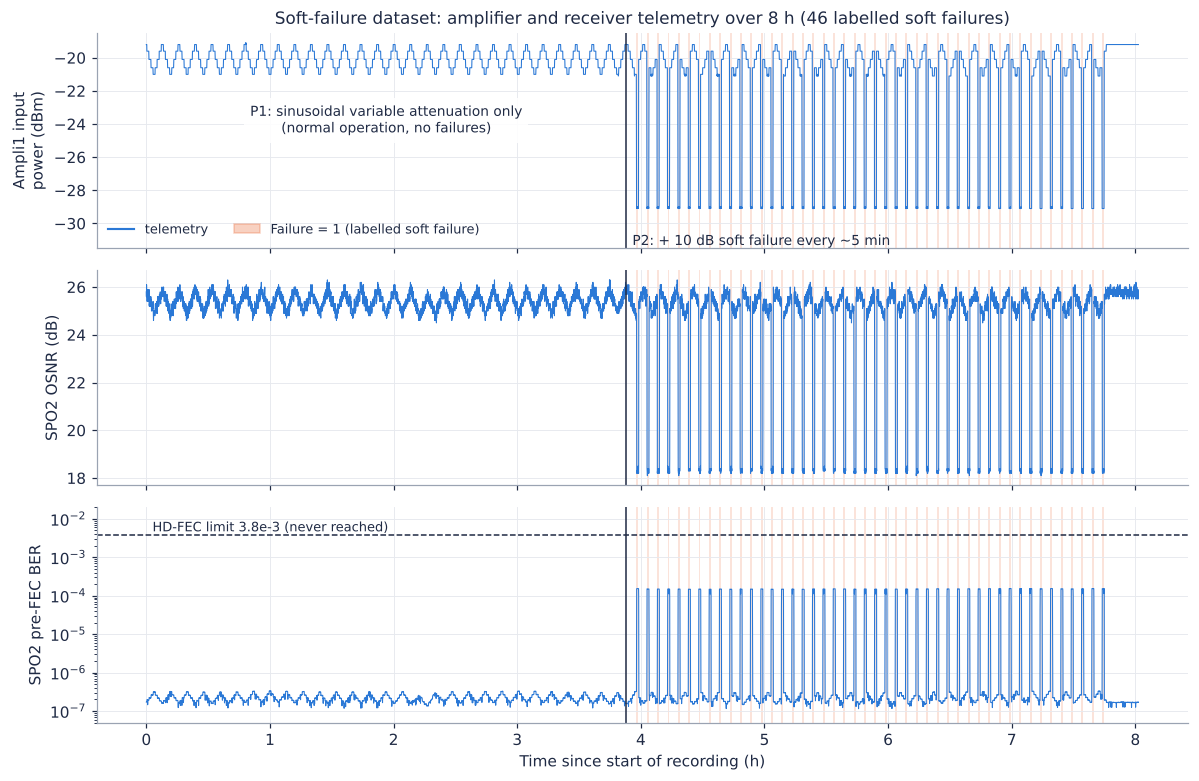

In [10]:
def shade_events(ax, ev, t0, unit=3600.0, color=C_FAIL, alpha=0.18):
    for _, e in ev.iterrows():
        ax.axvspan((e['onset_t'] - t0) / unit, (e['end_t'] - t0) / unit, color=color, alpha=alpha, lw=0)


A, ev = ALIGNED['soft'], EVENTS['soft']
t0 = A['t'].iloc[0]
fig, axes = plt.subplots(3, 1, figsize=(11, 7.2), sharex=True)
axes[0].plot(A['hours'], A['A1_Pin'], color=PAL[0], lw=0.7)
axes[0].set_ylabel('Ampli1 input\npower (dBm)')
axes[1].plot(A['hours'], A['SPO2_OSNR'], color=PAL[0], lw=0.7)
axes[1].set_ylabel('SPO2 OSNR (dB)')
axes[2].semilogy(A['hours'], A['SPO2_BER'], color=PAL[0], lw=0.7)
axes[2].axhline(FEC_HD, color=NAVY, ls='--', lw=1)
axes[2].text(0.05, FEC_HD * 1.25, 'HD-FEC limit 3.8e-3 (never reached)', fontsize=8.5, color=NAVY)
axes[2].set_ylim(5e-8, 2e-2)
axes[2].set_ylabel('SPO2 pre-FEC BER')
axes[2].set_xlabel('Time since start of recording (h)')
for ax in axes:
    shade_events(ax, ev, t0)
    ax.axvline((FAIL_START['soft'] - t0) / 3600, color=NAVY, lw=1)
xb = (FAIL_START['soft'] - t0) / 3600
axes[0].set_ylim(-31.5, -18.5)
axes[0].text(xb / 2, -24.5, 'P1: sinusoidal variable attenuation only\n(normal operation, no failures)',
             ha='center', fontsize=9, bbox=dict(facecolor='white', edgecolor='none', alpha=0.9))
axes[0].text(xb + 0.05, -31.3, 'P2: + 10 dB soft failure every ~5 min', ha='left', fontsize=9)
axes[0].legend(handles=[Line2D([], [], color=PAL[0], label='telemetry'),
                        Patch(color=C_FAIL, alpha=0.3, label='Failure = 1 (labelled soft failure)')],
               loc='lower left', ncol=2)
axes[0].set_title('Soft-failure dataset: amplifier and receiver telemetry over 8 h (46 labelled soft failures)')
fig.tight_layout()
savefig(fig, 'fig01_soft_timeseries_overview')
plt.show()

saved ../figures/fig02_soft_zoom_20min.png


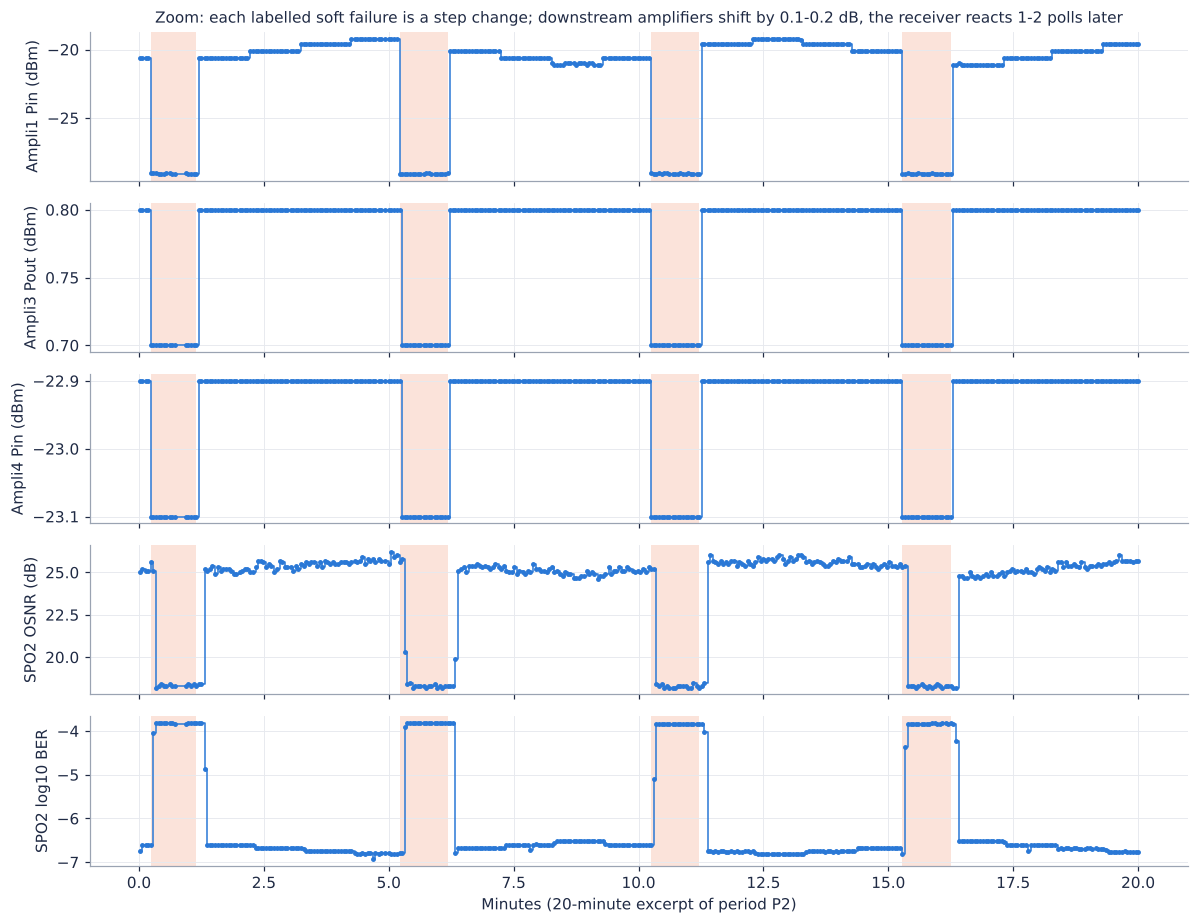

In [11]:
# Zoom on 20 minutes of the failure period plus onset-aligned response of each signal
z0 = FAIL_START['soft'] + 3600
Z = A[(A['t'] >= z0) & (A['t'] <= z0 + 1200)]
evz = ev[(ev['onset_t'] >= z0) & (ev['onset_t'] <= z0 + 1200)]
panels = [('A1_Pin', 'Ampli1 Pin (dBm)'), ('A3_Pout', 'Ampli3 Pout (dBm)'), ('A4_Pin', 'Ampli4 Pin (dBm)'),
          ('SPO2_OSNR', 'SPO2 OSNR (dB)'), ('SPO2_logBER', 'SPO2 log10 BER')]
fig, axes = plt.subplots(len(panels), 1, figsize=(11, 8.5), sharex=True)
for ax, (s, lab) in zip(axes, panels):
    ax.step((Z['t'] - z0) / 60, Z[s], where='post', color=PAL[0], lw=1)
    ax.plot((Z['t'] - z0) / 60, Z[s], 'o', ms=2.2, color=PAL[0])
    shade_events(ax, evz, z0, unit=60)
    ax.set_ylabel(lab)
axes[-1].set_xlabel('Minutes (20-minute excerpt of period P2)')
axes[0].set_title('Zoom: each labelled soft failure is a step change; downstream amplifiers shift by 0.1-0.2 dB, '
                  'the receiver reacts 1-2 polls later', fontsize=10)
fig.tight_layout()
savefig(fig, 'fig02_soft_zoom_20min')
plt.show()

saved ../figures/fig03_soft_onset_aligned_profiles.png


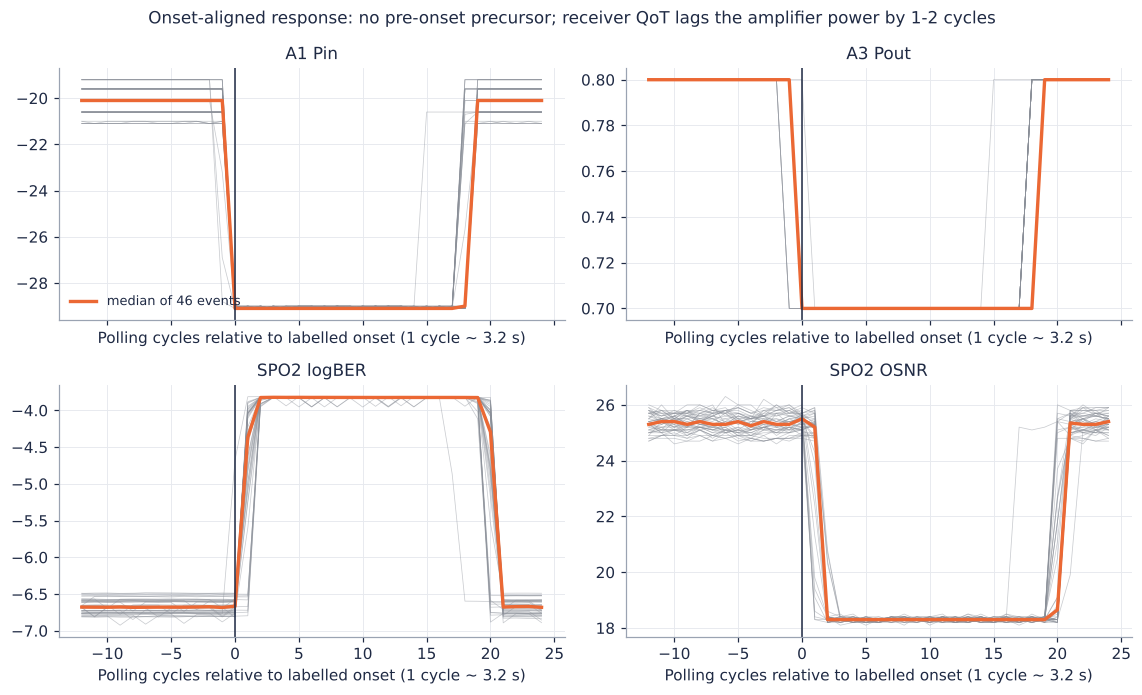

saved ../tables/tab07_soft_signal_response_lag.csv


,signal,events,detected_events,median_first_cycle,mean_first_cycle,share_events_cycle0,share_pre_onset_cycles_outside_range
0,A1_Pin,46,46,0.0,0.000,1.000,0.0851
1,A3_Pout,46,46,0.0,0.022,0.978,0.0072
2,SPO2_logBER,46,46,1.0,1.152,0.022,0.0072
3,SPO2_OSNR,46,46,2.0,1.739,0.000,0.0091
4,A2_Pin,46,46,0.0,0.022,0.978,0.0072
5,A3_Pin,46,46,0.0,0.022,0.978,0.0054
6,A4_Pin,46,46,0.0,0.022,0.978,0.0054
7,SPO1_OSNR,46,2,8.0,8.000,0.000,0.0018
8,SPO1_logBER,46,0,NaN,NaN,0.000,0.0000


In [12]:
# Onset-aligned ("superposed epoch") profiles: signal value vs time relative to the labelled onset.
def onset_profiles(A, ev, signals, before=12, after=24):
    out = {s: [] for s in signals}
    for _, e in ev.iterrows():
        i0 = int(e['onset_idx'])
        if i0 - before < 0 or i0 + after >= len(A):
            continue
        sl = A.iloc[i0 - before:i0 + after + 1]
        for s in signals:
            out[s].append(pd.Series(sl[s].values, index=np.arange(-before, after + 1)))
    return {s: pd.concat(v, axis=1) for s, v in out.items()}


prof_signals = ['A1_Pin', 'A3_Pout', 'SPO2_logBER', 'SPO2_OSNR']
PROF = onset_profiles(A, ev, prof_signals)
fig, axes = plt.subplots(2, 2, figsize=(10.5, 6.4), sharex=True)
for ax, s in zip(axes.ravel(), prof_signals):
    P = PROF[s]
    for c in P.columns:
        ax.plot(P.index, P[c], color=GREY, lw=0.5, alpha=0.45)
    ax.plot(P.index, P.median(axis=1), color=PAL[1], lw=2.2, label='median of 46 events')
    ax.axvline(0, color=NAVY, lw=1)
    ax.set_title(s.replace('_', ' '))
    ax.set_xlabel('Polling cycles relative to labelled onset (1 cycle ~ 3.2 s)')
axes[0, 0].legend(loc='lower left')
fig.suptitle('Onset-aligned response: no pre-onset precursor; receiver QoT lags the amplifier power by 1-2 cycles',
             fontsize=11, color=NAVY)
fig.tight_layout()
savefig(fig, 'fig03_soft_onset_aligned_profiles')
plt.show()

# Quantify the lag: first cycle (relative to onset) at which each signal leaves its P1 (failure-free) range
p1 = A[A['t'] < CALIB_END['soft']]
lag_rows = []
for s in prof_signals + ['A2_Pin', 'A3_Pin', 'A4_Pin', 'SPO1_OSNR', 'SPO1_logBER']:
    lo, hi = p1[s].quantile(0.005), p1[s].quantile(0.995)
    P = onset_profiles(A, ev, [s])[s]
    out = (P < lo) | (P > hi)
    first = []
    for c in P.columns:
        idx = out.index[(out.index >= 0) & out[c].values]
        first.append(idx.min() if len(idx) else np.nan)
    pre = out.loc[out.index < 0].values.mean()
    first = pd.Series(first)
    lag_rows.append({'signal': s, 'events': P.shape[1], 'detected_events': int(first.notna().sum()),
                     'median_first_cycle': first.median(), 'mean_first_cycle': round(first.mean(), 3),
                     'share_events_cycle0': round((first == 0).mean(), 3),
                     'share_pre_onset_cycles_outside_range': round(float(pre), 4)})
lag_tab = pd.DataFrame(lag_rows)
save_table(lag_tab, 'tab07_soft_signal_response_lag')
lag_tab

### 3.5 Pre-onset precursor test
If soft failures were preceded by gradual degradation, signals in the 30 s before onset would
differ from other normal records. We compare the two groups (Mann-Whitney U, standardised mean
difference) for each raw signal, using normal records of period P2 only.

In [13]:
from scipy.stats import mannwhitneyu


def precursor_test(A, ev, signals, window_s=30, fail_start=None, exclude_last_s=0):
    """Compare normal cycles in (onset - window_s, onset - exclude_last_s] with all other normal
    cycles of the failure period. exclude_last_s > 0 drops the polling cycle immediately before onset,
    where readings polled 1-2 s apart can straddle the WSS switching instant."""
    t = A['t'].values
    onsets = ev['onset_t'].values
    j = np.searchsorted(onsets, t, side='right')
    nxt = np.where(j < len(onsets), onsets[np.minimum(j, len(onsets) - 1)], np.inf)
    ttn = nxt - t
    normal = (A['y'].values == 0) & (t >= fail_start)
    pre = normal & (ttn <= window_s) & (ttn > exclude_last_s)
    other = normal & (ttn > window_s)
    rows = []
    for s in signals:
        a, b = A.loc[pre, s].values, A.loc[other, s].values
        p = mannwhitneyu(a, b).pvalue if np.std(np.r_[a, b]) > 0 else np.nan
        smd = (a.mean() - b.mean()) / (np.sqrt((a.var() + b.var()) / 2) + 1e-12)
        rows.append({'signal': s, 'window': f'({exclude_last_s}, {window_s}] s before onset', 'pre_onset_n': len(a),
                     'other_normal_n': len(b), 'pre_onset_mean': a.mean(), 'other_normal_mean': b.mean(),
                     'std_mean_difference': round(smd, 3), 'mannwhitney_p': p})
    return pd.DataFrame(rows)


prec_soft = pd.concat([precursor_test(A, ev, SIGNALS['soft'], 30, FAIL_START['soft'], 0),
                       precursor_test(A, ev, SIGNALS['soft'], 30, FAIL_START['soft'], 5)], ignore_index=True)
save_table(prec_soft, 'tab08_soft_precursor_test_30s')
prec_soft

saved ../tables/tab08_soft_precursor_test_30s.csv


,signal,window,pre_onset_n,other_normal_n,pre_onset_mean,other_normal_mean,std_mean_difference,mannwhitney_p
0,A1_Pin,"(0, 30] s before onset",413,3358,-20.169976,-20.027040,-0.197,6.521898e-04
1,A2_Pin,"(0, 30] s before onset",413,3358,-15.500969,-15.500030,-0.134,7.566410e-07
2,A3_Pin,"(0, 30] s before onset",413,3358,-16.700726,-16.700000,-0.121,7.825432e-07
3,A3_Pout,"(0, 30] s before onset",413,3358,0.799031,0.800000,-0.140,1.165209e-08
4,A4_Pin,"(0, 30] s before onset",413,3358,-22.900484,-22.898332,-0.142,1.398030e-02
5,SPO1_logBER,"(0, 30] s before onset",413,3358,-7.643338,-7.641992,-0.045,5.219646e-01
6,SPO1_OSNR,"(0, 30] s before onset",413,3358,38.531719,38.539875,-0.046,4.114071e-01
7,SPO2_logBER,"(0, 30] s before onset",413,3358,-6.666907,-6.600400,-0.198,9.227795e-02
8,SPO2_OSNR,"(0, 30] s before onset",413,3358,25.341404,25.200149,0.160,2.486126e-02
9,A1_Pin,"(5, 30] s before onset",367,3358,-20.120981,-20.027040,-0.155,3.786637e-03


### 3.6 Correlation and per-class distributions

saved ../tables/tab09_soft_spearman_correlation.csv


saved ../figures/fig04_soft_correlation_heatmap.png


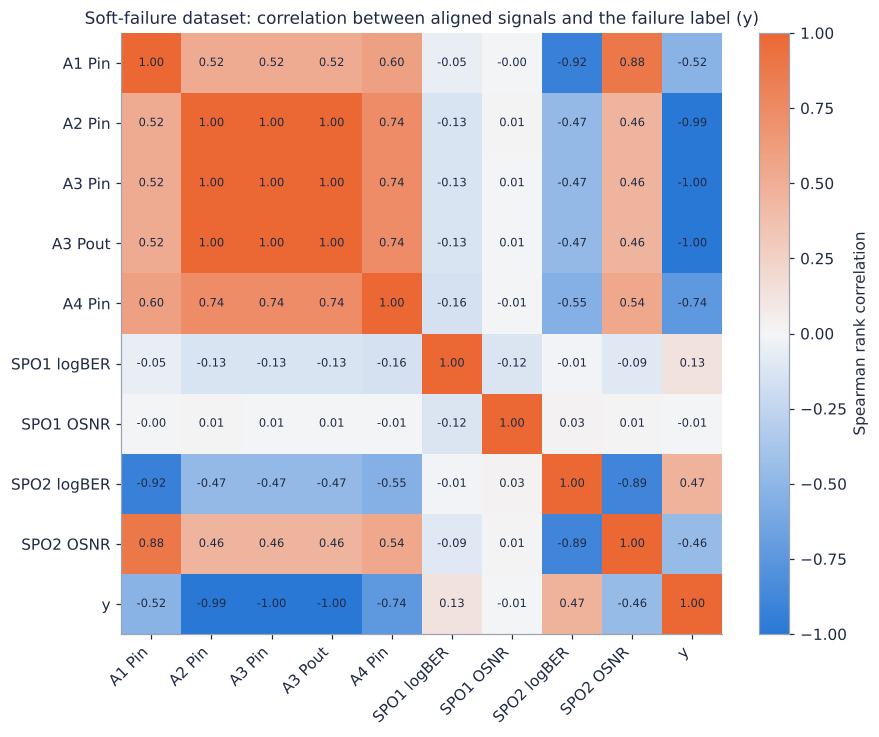

In [14]:
corr_cols = SIGNALS['soft'] + ['y']
C = A[corr_cols].corr(method='spearman')
save_table(C.reset_index().rename(columns={'index': 'signal'}), 'tab09_soft_spearman_correlation')
fig, ax = plt.subplots(figsize=(8.2, 6.8))
im = ax.imshow(C.values, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)), [c.replace('_', ' ') for c in corr_cols], rotation=45, ha='right')
ax.set_yticks(range(len(corr_cols)), [c.replace('_', ' ') for c in corr_cols])
ax.grid(False)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax.text(j, i, f'{C.values[i, j]:.2f}', ha='center', va='center', fontsize=7.5, color=NAVY)
cb = fig.colorbar(im, ax=ax, fraction=0.046)
cb.set_label('Spearman rank correlation')
ax.set_title('Soft-failure dataset: correlation between aligned signals and the failure label (y)')
fig.tight_layout()
savefig(fig, 'fig04_soft_correlation_heatmap')
plt.show()

saved ../figures/fig05_soft_feature_distributions.png


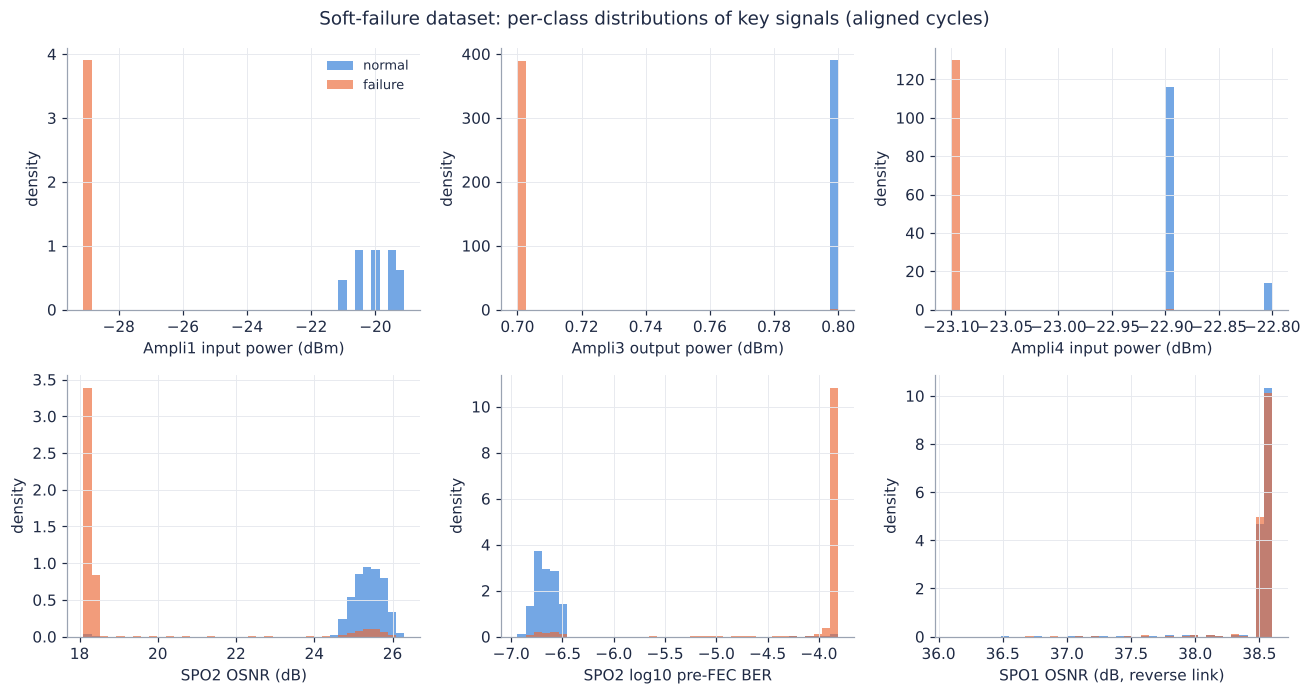

In [15]:
dist_signals = [('A1_Pin', 'Ampli1 input power (dBm)'), ('A3_Pout', 'Ampli3 output power (dBm)'),
                ('A4_Pin', 'Ampli4 input power (dBm)'), ('SPO2_OSNR', 'SPO2 OSNR (dB)'),
                ('SPO2_logBER', 'SPO2 log10 pre-FEC BER'), ('SPO1_OSNR', 'SPO1 OSNR (dB, reverse link)')]
fig, axes = plt.subplots(2, 3, figsize=(12, 6.4))
for ax, (s, lab) in zip(axes.ravel(), dist_signals):
    lo, hi = A[s].min(), A[s].max()
    bins = np.linspace(lo, hi, 40) if hi > lo else 10
    ax.hist(A.loc[A['y'] == 0, s], bins=bins, density=True, color=C_NORMAL, alpha=0.65, label='normal')
    ax.hist(A.loc[A['y'] == 1, s], bins=bins, density=True, color=C_FAIL, alpha=0.65, label='failure')
    ax.set_xlabel(lab)
    ax.set_ylabel('density')
axes[0, 0].legend()
fig.suptitle('Soft-failure dataset: per-class distributions of key signals (aligned cycles)', color=NAVY)
fig.tight_layout()
savefig(fig, 'fig05_soft_feature_distributions')
plt.show()

### 3.7 Soft vs hard events (severity at the receiver)
For each event we take the worst receiver reading between onset and end + 10 s (receiver lag).
* **hard**: loss of signal (BER or OSNR reported as 0) or pre-FEC BER >= the HD-FEC limit 3.8e-3
  (service-affecting once the FEC can no longer correct errors);
* **soft**: no LOS and BER below the FEC limit, but OSNR at least 3 dB below the failure-free median
  (margin erosion visible to the receiver while traffic still flows);
* **not visible at receiver**: neither.

In [16]:
def event_severity(A, ev, k):
    calib = A[A['t'] < CALIB_END[k]]
    osnr_med = calib['SPO2_OSNR'].median()
    rows = []
    for _, e in ev.iterrows():
        w = A[(A['t'] >= e['onset_t']) & (A['t'] <= e['end_t'] + TAIL_S)]
        los = bool(w['SPO2_LOS'].max())
        valid = w[w['SPO2_LOS'] == 0]
        peak_ber = valid['SPO2_BER'].max() if len(valid) else np.nan
        min_osnr = valid['SPO2_OSNR'].min() if len(valid) else np.nan
        if los or (peak_ber >= FEC_HD):
            sev = 'hard'
        elif min_osnr <= osnr_med - OSNR_MARGIN_DB:
            sev = 'soft'
        else:
            sev = 'not visible at receiver'
        rows.append({'dataset': k, 'onset_t': e['onset_t'], 'n_cycles': e['n_cycles'], 'LOS': los,
                     'peak_valid_BER': peak_ber, 'min_valid_OSNR': min_osnr,
                     'OSNR_drop_dB': osnr_med - min_osnr, 'severity': sev})
    return pd.DataFrame(rows), osnr_med


SEV = {}
for k in ALIGNED:
    SEV[k], med = event_severity(ALIGNED[k], EVENTS[k], k)
    SUMMARY[f'{k}_calib_osnr_median'] = float(med)
sev_all = pd.concat(SEV.values(), ignore_index=True)
save_table(sev_all, 'tab10_event_severity_per_event')
sev_tab = sev_all.groupby(['dataset', 'severity']).agg(events=('onset_t', 'size'),
                                                         median_peak_BER=('peak_valid_BER', 'median'),
                                                         median_OSNR_drop_dB=('OSNR_drop_dB', 'median')).reset_index()
save_table(sev_tab, 'tab11_event_severity_summary')
SUMMARY['severity'] = sev_tab.to_dict(orient='records')
sev_tab

saved ../tables/tab10_event_severity_per_event.csv
saved ../tables/tab11_event_severity_summary.csv


,dataset,severity,events,median_peak_BER,median_OSNR_drop_dB
0,hard,hard,131,0.000145,5.2
1,soft,soft,46,0.000151,7.2


## 4. Feature engineering

* **F1 - raw instantaneous readings** of the informative signals in the current polling cycle.
* **F2(W) - raw + temporal context**: for each signal, the first difference `d1 = x_t - x_(t-1)`,
  and over a causal, time-based window (t - W, t] the mean, standard deviation, minimum, maximum,
  least-squares slope (units per second, i.e. rate of change) and deviation of the current value from
  the window mean. W in {15, 30, 60} s (about 5, 9 and 19 cycles). **F2-multi** concatenates all
  three windows. Every window ends at the current cycle, so features use past data only.

**Telemetry views** (which monitoring points the model may see):
* **ALL** - every informative amplifier and transponder signal (the proposal's design). Ampli1 input
  power *defines* the label, so this view is an upper bound / sanity check.
* **NOA1** - everything except Ampli1 (the attenuated span's own amplifier is not monitored).
* **QOT** - transponder quality-of-transmission metrics only (SPO1/SPO2 BER, OSNR): what an operator
  sees at the coherent receivers. This is the realistic and non-trivial soft-failure detection task.

In [17]:
def build_features(A, signals, windows=WINDOWS):
    idx = pd.to_datetime(A['t'], unit='s')
    tt = pd.Series((A['t'] - A['t'].iloc[0]).astype(float).values, index=idx)
    cols = {}
    for s in signals:
        x = pd.Series(A[s].astype(float).values, index=idx)
        cols[s] = x.values
        cols[f'{s}__d1'] = x.diff().fillna(0).values
        for w in windows:
            r = x.rolling(f'{w}s', min_periods=1)
            m = r.mean()
            cols[f'{s}__mean_{w}s'] = m.values
            cols[f'{s}__std_{w}s'] = r.std().fillna(0).values
            cols[f'{s}__min_{w}s'] = r.min().values
            cols[f'{s}__max_{w}s'] = r.max().values
            cov = x.rolling(f'{w}s', min_periods=2).cov(tt)
            var = tt.rolling(f'{w}s', min_periods=2).var()
            cols[f'{s}__slope_{w}s'] = (cov / var).replace([np.inf, -np.inf], np.nan).fillna(0).values
            cols[f'{s}__dev_{w}s'] = (x - m).values
    return pd.DataFrame(cols, index=A.index)


def view_signals(k, view):
    sig = SIGNALS[k]
    if view == 'ALL':
        return list(sig)
    if view == 'NOA1':
        return [s for s in sig if not s.startswith('A1_')]
    if view == 'QOT':
        return [s for s in sig if s.startswith('SPO')]
    if view == 'AMP':
        return [s for s in sig if s.startswith('A')]
    raise ValueError(view)


def fset_columns(F, signals, fset):
    if fset == 'F1':
        return list(signals)
    base = [c for c in F.columns if c.split('__')[0] in signals]
    if fset == 'F2-multi':
        return base
    w = fset.split('-')[1]          # e.g. '30s'
    return [c for c in base if '__' not in c or c.endswith('__d1') or c.endswith(f'_{w}')]


FEATS = {k: build_features(ALIGNED[k], SIGNALS[k]) for k in ALIGNED}
for k, F in FEATS.items():
    assert not F.isna().any().any()
    print(k, 'feature matrix', F.shape)
FSETS = ['F1'] + [f'F2-{w}s' for w in WINDOWS] + ['F2-multi']
nf = [{'dataset': k, 'view': v, 'feature_set': fs, 'n_features': len(fset_columns(FEATS[k], view_signals(k, v), fs))}
      for k in FEATS for v in ['ALL', 'NOA1', 'QOT', 'AMP'] for fs in FSETS]
save_table(pd.DataFrame(nf), 'tab12_feature_counts')

# Causality check: features at cycle i must not change when all later cycles are deleted.
_A = ALIGNED['soft']
_cut = 6000
_Fp = build_features(_A.iloc[:_cut + 1].reset_index(drop=True), SIGNALS['soft'])
assert np.allclose(_Fp.iloc[_cut].values, FEATS['soft'].iloc[_cut].values), 'non-causal feature detected'
print('causality check passed: features of cycle', _cut, 'are identical when the future is removed')

soft feature matrix (8953, 180)
hard feature matrix (10949, 200)
saved ../tables/tab12_feature_counts.csv
causality check passed: features of cycle 6000 are identical when the future is removed


## 5. Targets

* **T0 - detection (now-cast):** `y(t)` = Failure flag of the current cycle.
* **T_H - early warning (pre-onset prediction):** for a cycle that is currently normal,
  `y_H(t) = 1` if a failure onset occurs in (t, t + H]; cycles that are already in failure are
  excluded (they are the detection task), and the last H seconds of the recording are dropped
  because their future is not observed. H in {10, 30, 60, 120} s (soft) and {10, 20} s (hard).

In [18]:
def time_to_next_onset(A, ev):
    t = A['t'].values
    onsets = ev['onset_t'].values
    j = np.searchsorted(onsets, t, side='right')
    nxt = np.where(j < len(onsets), onsets[np.minimum(j, len(onsets) - 1)], np.inf)
    return nxt - t


def make_target(k, task):
    """Return (y, valid_mask) for task 'T0' or 'H<seconds>'."""
    A = ALIGNED[k]
    y0 = A['y'].values
    if task == 'T0':
        return y0.copy(), np.ones(len(A), bool)
    H = int(task[1:])
    ttn = time_to_next_onset(A, EVENTS[k])
    yH = ((y0 == 0) & (ttn <= H)).astype(int)
    valid = (y0 == 0) & (A['t'].values <= A['t'].values.max() - H)
    return yH, valid

## 6. Chronological split with embargo, and blocked time-series CV

The failures exist only in the second (soft) or third (hard) period, so a single cut over the whole
series would leave one partition without positives. The failure period itself, however, alternates
normal and failure states every few minutes, so we keep strict temporal order and place both split
boundaries **inside the failure period**:

* **train** = all earlier failure-free data + the first 50 % of the failure events;
* **validation** = the next 25 % of the failure events (threshold tuning, imbalance-strategy selection);
* **test** = the last 25 % of the failure events and everything after them (used once for reporting).

Each boundary is placed in the middle of the normal gap between two consecutive events, so no event
straddles two partitions, and all cycles within +/-60 s of the boundary are removed (embargo
>= the longest rolling window); any event touching the embargo zone is removed entirely. Training
precedes validation, which precedes test. Hyperparameters are tuned only on the training block with
`TimeSeriesSplit` (4 expanding folds, validation folds placed in the failure-period part of the
training block, gap of ~120 s between fold-train and fold-validation).

In [19]:
def event_boundaries(k, fracs):
    """Boundaries placed in the middle of the normal gap that follows a given share of the
    failure-period events (so each partition receives the intended share of events)."""
    ev = EVENTS[k]
    evp = ev[ev['onset_t'] >= FAIL_START[k]].reset_index(drop=True)
    out = []
    for f in fracs:
        i = int(round(f * len(evp)))          # events 0..i-1 before the boundary
        out.append(float((evp.loc[i - 1, 'end_t'] + evp.loc[i, 'onset_t']) / 2))
    return out


def chrono_split(k, fracs=(0.5, 0.75), embargo=EMBARGO_S):
    A, ev = ALIGNED[k], EVENTS[k]
    t = A['t'].values
    bounds = event_boundaries(k, fracs)
    emb = np.zeros(len(A), bool)
    for b in bounds:
        zone = (t >= b - embargo) & (t <= b + embargo)
        emb |= zone
        for _, e in ev.iterrows():   # purge whole events that touch the zone
            if e['end_t'] >= b - embargo and e['onset_t'] <= b + embargo:
                emb |= (t >= e['onset_t']) & (t <= e['end_t'])
    b1, b2 = bounds
    masks = {'train': (t < b1) & ~emb, 'val': (t >= b1) & (t < b2) & ~emb, 'test': (t >= b2) & ~emb,
             'embargo': emb}
    return masks, bounds


SPLITS, BOUNDS = {}, {}
split_rows = []
for k in ALIGNED:
    SPLITS[k], BOUNDS[k] = chrono_split(k)
    A = ALIGNED[k]
    for part in ['train', 'val', 'test', 'embargo']:
        m = SPLITS[k][part]
        tt = A.loc[m, 't']
        n_ev = sum(((A['t'] >= e['onset_t']) & (A['t'] <= e['end_t']) & m).any() for _, e in EVENTS[k].iterrows())
        split_rows.append({'dataset': k, 'partition': part, 'start_utc': pd.to_datetime(tt.min(), unit='s'),
                           'end_utc': pd.to_datetime(tt.max(), unit='s'), 'start_unix': tt.min(), 'end_unix': tt.max(),
                           'cycles': int(m.sum()), 'failure_cycles': int(A.loc[m, 'y'].sum()),
                           'failure_share': round(A.loc[m, 'y'].mean(), 4), 'events': int(n_ev)})
    print(k, 'boundaries (unix):', BOUNDS[k], [str(pd.to_datetime(b, unit='s')) for b in BOUNDS[k]])
split_tab = pd.DataFrame(split_rows)
save_table(split_tab, 'tab13_chronological_split')
SUMMARY['split_bounds'] = {k: BOUNDS[k] for k in BOUNDS}
split_tab

soft boundaries (unix): [1624478643.5, 1624481958.0] ['2021-06-23 20:04:03.500000', '2021-06-23 20:59:18']


hard boundaries (unix): [1623427056.5, 1623428698.0] ['2021-06-11 15:57:36.500000', '2021-06-11 16:24:58']
saved ../tables/tab13_chronological_split.csv


,dataset,partition,start_utc,end_utc,start_unix,end_unix,cycles,failure_cycles,failure_share,events
0,soft,train,2021-06-23 14:12:42,2021-06-23 20:03:03,1624457562,1624478583,6514,427,0.0656,23
1,soft,val,2021-06-23 20:05:05,2021-06-23 20:58:17,1624478705,1624481897,992,204,0.2056,11
2,soft,test,2021-06-23 21:00:19,2021-06-23 22:14:11,1624482019,1624486451,1373,223,0.1624,12
3,soft,embargo,2021-06-23 20:03:06,2021-06-23 21:00:16,1624478586,1624482016,74,0,0.0000,0
4,hard,train,2021-06-11 06:57:15,2021-06-11 15:56:36,1623394635,1623426996,9909,199,0.0201,65
5,hard,val,2021-06-11 15:58:37,2021-06-11 16:23:56,1623427117,1623428636,467,96,0.2056,30
6,hard,test,2021-06-11 16:26:01,2021-06-11 16:52:45,1623428761,1623430365,499,103,0.2064,32
7,hard,embargo,2021-06-11 15:56:39,2021-06-11 16:25:58,1623426999,1623428758,74,12,0.1622,4


In [20]:
# Leakage guard for the horizon targets: no training/validation label may look past its partition.
for k, Hs in [('soft', HORIZONS_SOFT), ('hard', HORIZONS_HARD)]:
    A = ALIGNED[k]
    t = A['t'].values
    ttn = time_to_next_onset(A, EVENTS[k])
    for part, b in [('train', BOUNDS[k][0]), ('val', BOUNDS[k][1])]:
        m = SPLITS[k][part]
        nxt = t[m] + ttn[m]
        for H in Hs:
            # a positive label is only allowed if the onset it refers to lies before the boundary
            bad = ((ttn[m] <= H) & (nxt > b)).sum()
            assert bad == 0, (k, part, H, bad)
print('horizon-label leakage guard passed')

horizon-label leakage guard passed


saved ../figures/fig06_chronological_split_timeline.png


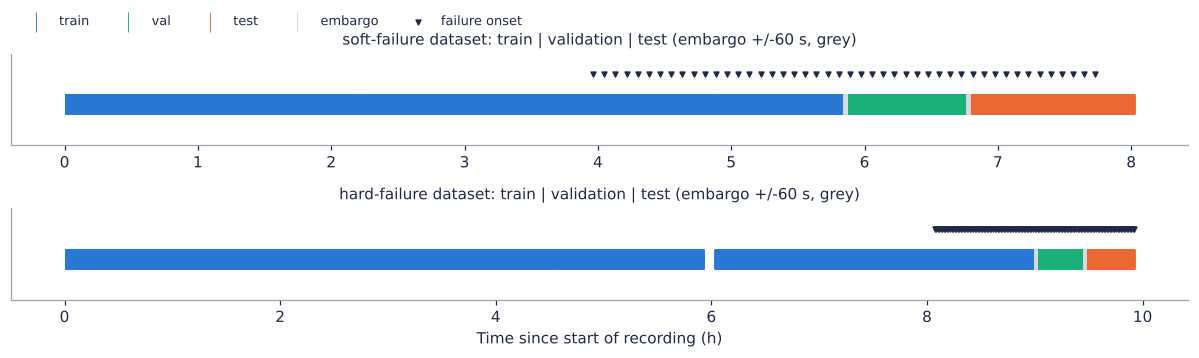

In [21]:
# Split timeline figure (both datasets)
fig, axes = plt.subplots(2, 1, figsize=(11, 3.6))
for ax, k in zip(axes, ['soft', 'hard']):
    A = ALIGNED[k]
    h0 = A['t'].iloc[0]
    for part in ['train', 'val', 'test', 'embargo']:
        m = SPLITS[k][part]
        ax.scatter((A.loc[m, 't'] - h0) / 3600, np.zeros(m.sum()), marker='|', s=180,
                   color=SPLIT_COLORS[part], label=part, linewidths=0.6)
    on = (EVENTS[k]['onset_t'] - h0) / 3600
    ax.scatter(on, np.full(len(on), 0.6), marker='v', s=10, color=NAVY, label='failure onset')
    ax.set_ylim(-0.8, 1.0)
    ax.set_yticks([])
    ax.grid(False)
    ax.set_title(f"{k}-failure dataset: train | validation | test (embargo +/-{EMBARGO_S} s, grey)", fontsize=10)
axes[1].set_xlabel('Time since start of recording (h)')
axes[0].legend(ncol=5, loc='upper left', bbox_to_anchor=(0, 1.55), markerscale=1)
fig.tight_layout()
savefig(fig, 'fig06_chronological_split_timeline')
plt.show()

saved ../tables/tab14_class_balance_by_target_and_split.csv


saved ../figures/fig07_class_balance.png


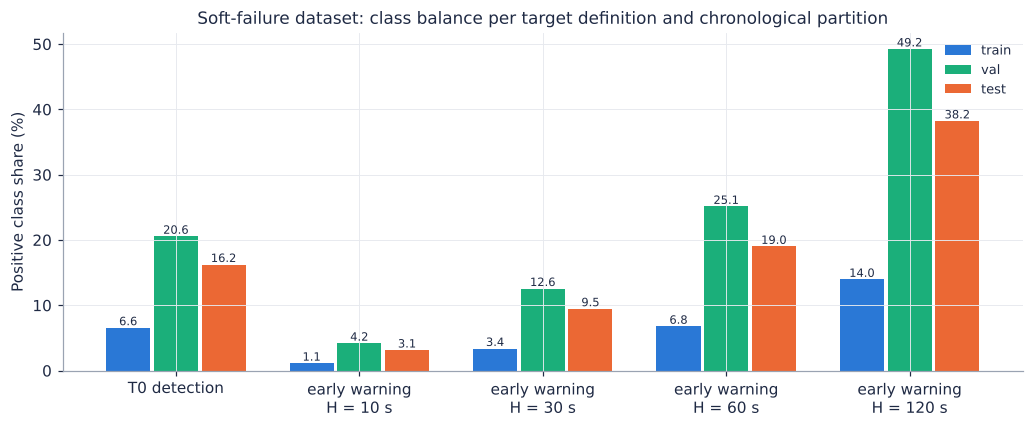

,dataset,target,partition,records,positives,positive_share,neg_to_pos_ratio
0,soft,T0,train,6514,427,0.0656,14.26
1,soft,T0,val,992,204,0.2056,3.86
2,soft,T0,test,1373,223,0.1624,5.16
3,soft,H10,train,6087,69,0.0113,87.22
4,soft,H10,val,788,33,0.0419,22.88
5,soft,H10,test,1147,36,0.0314,30.86
6,soft,H30,train,6087,206,0.0338,28.55
7,soft,H30,val,788,99,0.1256,6.96
8,soft,H30,test,1140,108,0.0947,9.56
9,soft,H60,train,6087,413,0.0678,13.74


In [22]:
# Class ratio under each target definition and partition
cb_rows = []
for k, tasks in [('soft', ['T0'] + [f'H{h}' for h in HORIZONS_SOFT]), ('hard', ['T0'] + [f'H{h}' for h in HORIZONS_HARD])]:
    for task in tasks:
        y, valid = make_target(k, task)
        for part in ['train', 'val', 'test']:
            m = SPLITS[k][part] & valid
            cb_rows.append({'dataset': k, 'target': task, 'partition': part, 'records': int(m.sum()),
                            'positives': int(y[m].sum()), 'positive_share': round(y[m].mean(), 4),
                            'neg_to_pos_ratio': round((1 - y[m].mean()) / max(y[m].mean(), 1e-9), 2)})
cb = pd.DataFrame(cb_rows)
save_table(cb, 'tab14_class_balance_by_target_and_split')
fig, ax = plt.subplots(figsize=(9.5, 4))
sub = cb[cb['dataset'] == 'soft']
tasks = list(dict.fromkeys(sub['target']))
xx = np.arange(len(tasks))
for i, part in enumerate(['train', 'val', 'test']):
    v = sub[sub['partition'] == part].set_index('target').loc[tasks, 'positive_share'] * 100
    bars = ax.bar(xx + (i - 1) * 0.26, v, width=0.24, color=SPLIT_COLORS[part], label=part)
    for b, val in zip(bars, v):
        ax.text(b.get_x() + b.get_width() / 2, val + 0.4, f'{val:.1f}', ha='center', fontsize=7.5)
ax.set_xticks(xx, ['T0 detection'] + [f'early warning\nH = {t[1:]} s' for t in tasks[1:]])
ax.set_ylabel('Positive class share (%)')
ax.set_title('Soft-failure dataset: class balance per target definition and chronological partition')
ax.legend()
fig.tight_layout()
savefig(fig, 'fig07_class_balance')
plt.show()
cb

## 7. Models, baselines and evaluation utilities

* **Dummy**: majority class (always "normal").
* **Conventional fixed-threshold monitoring** (no learning; static limits on the receiver's metrics):
  * `TH-FEC-HD`: pre-FEC BER >= 3.8e-3 (hard-decision FEC limit; a link beyond it starts losing frames);
  * `TH-FEC-SD`: pre-FEC BER >= 2.0e-2 (soft-decision FEC limit);
  * `TH-BER-99`, `TH-OSNR-99`: BER above the 99th percentile / OSNR below the 1st percentile of
    the failure-free period (the "99 % confidence" static threshold used by Silva et al., 2022);
  * `TH-QoT-99`: `TH-BER-99` OR `TH-OSNR-99` (the conventional receiver-side alarm used as the
    reference for lead-time comparisons);
  * `TH-OSNR-3dB`: OSNR more than 3 dB below the failure-free median (fixed engineering margin);
  * `TH-A1Pin-99`: Ampli1 input power below its failure-free 1st percentile (an amplifier
    power alarm, essentially the rule that generated the labels).
* **LR** (logistic regression, L2, standardised inputs), **RF** (random forest, 200 trees during
  tuning and evaluation), **SVM** (RBF kernel, standardised inputs). Scores: predicted probability
  (LR, RF) or signed distance to the hyperplane (SVM); default thresholds 0.5 and 0.
* **SVM training subsample:** RBF-SVM training time grows roughly quadratically with the number of
  cycles, so when a training block exceeds 3,000 cycles the SVM is trained on every k-th cycle
  (uniform temporal thinning, k = 3 for the soft and 4 for the hard training block). Class prevalence
  and temporal coverage are preserved; validation and test data are never thinned. LR and RF always
  use every training cycle.

In [23]:
def calib_mask(k):
    return ALIGNED[k]['t'].values < CALIB_END[k]


def rule_scores(k, rule):
    """Continuous score and binary alarm for a conventional threshold rule. Thresholds are
    calibrated on the failure-free period only."""
    A = ALIGNED[k]
    cm = calib_mask(k) & (A['SPO2_LOS'].values == 0)
    lb, osnr, pin = A['SPO2_logBER'].values, A['SPO2_OSNR'].values, A['A1_Pin'].values
    los = A['SPO2_LOS'].values == 1
    if rule == 'TH-FEC-HD':
        s, thr = lb, np.log10(FEC_HD)
        alarm = (s >= thr) | los
        return s + los * 10, alarm.astype(int), thr
    if rule == 'TH-FEC-SD':
        s, thr = lb, np.log10(FEC_SD)
        alarm = (s >= thr) | los
        return s + los * 10, alarm.astype(int), thr
    if rule == 'TH-BER-99':
        thr = np.quantile(lb[cm], 0.99)
        return lb, (lb > thr).astype(int), thr
    if rule == 'TH-OSNR-99':
        thr = np.quantile(osnr[cm], 0.01)
        return -osnr, (osnr < thr).astype(int), thr
    if rule == 'TH-OSNR-3dB':
        thr = np.median(osnr[cm]) - OSNR_MARGIN_DB
        return -osnr, (osnr < thr).astype(int), thr
    if rule == 'TH-QoT-99':
        tb, to = np.quantile(lb[cm], 0.99), np.quantile(osnr[cm], 0.01)
        sb = (lb - tb) / (np.subtract(*np.quantile(lb[cm], [0.75, 0.25])) + 1e-9)
        so = (to - osnr) / (np.subtract(*np.quantile(osnr[cm], [0.75, 0.25])) + 1e-9)
        s = np.maximum(sb, so)
        return s, ((lb > tb) | (osnr < to)).astype(int), (tb, to)
    if rule == 'TH-A1Pin-99':
        thr = np.quantile(pin[cm], 0.01)
        return -pin, (pin < thr).astype(int), thr
    raise ValueError(rule)


RULES = ['TH-FEC-HD', 'TH-FEC-SD', 'TH-BER-99', 'TH-OSNR-99', 'TH-QoT-99', 'TH-OSNR-3dB', 'TH-A1Pin-99']
rule_thr_rows = []
for k in ALIGNED:
    for r in RULES:
        _, _, thr = rule_scores(k, r)
        rule_thr_rows.append({'dataset': k, 'rule': r, 'threshold': str(np.round(thr, 4))})
rule_thr = pd.DataFrame(rule_thr_rows)
save_table(rule_thr, 'tab15_threshold_rule_definitions')
rule_thr

saved ../tables/tab15_threshold_rule_definitions.csv


,dataset,rule,threshold
0,soft,TH-FEC-HD,-2.4202
1,soft,TH-FEC-SD,-1.699
2,soft,TH-BER-99,-6.4845
3,soft,TH-OSNR-99,24.7
4,soft,TH-QoT-99,[-6.4845 24.7 ]
5,soft,TH-OSNR-3dB,22.4
6,soft,TH-A1Pin-99,-21.0
7,hard,TH-FEC-HD,-2.4202
8,hard,TH-FEC-SD,-1.699
9,hard,TH-BER-99,-1.8197


In [24]:
def metrics_from(y, score, alarm):
    y = np.asarray(y).astype(int)
    alarm = np.asarray(alarm).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, alarm, labels=[0, 1]).ravel()
    both = len(np.unique(y)) == 2
    return {'recall': recall_score(y, alarm, zero_division=0), 'precision': precision_score(y, alarm, zero_division=0),
            'f1': f1_score(y, alarm, zero_division=0), 'f2': fbeta_score(y, alarm, beta=2, zero_division=0),
            'pr_auc': average_precision_score(y, score) if both else np.nan,
            'roc_auc': roc_auc_score(y, score) if both else np.nan,
            'mcc': matthews_corrcoef(y, alarm), 'balanced_acc': balanced_accuracy_score(y, alarm),
            'accuracy': accuracy_score(y, alarm), 'tp': int(tp), 'fp': int(fp), 'fn': int(fn), 'tn': int(tn),
            'type1_fpr': fp / max(fp + tn, 1), 'type2_fnr': fn / max(fn + tp, 1),
            'n': int(len(y)), 'prevalence': float(y.mean())}


def is_svm(model):
    est = model.steps[-1][1] if hasattr(model, 'steps') else model
    return isinstance(est, SVC)


def model_scores(model, X):
    if is_svm(model):
        return model.decision_function(X)
    return model.predict_proba(X)[:, 1]


def default_threshold(model):
    return 0.0 if is_svm(model) else 0.5


def tune_threshold(y, s, beta=2.0):
    """Threshold maximising F-beta on (chronological) validation data."""
    p, r, thr = precision_recall_curve(y, s)
    f = (1 + beta ** 2) * p * r / np.maximum(beta ** 2 * p + r, 1e-12)
    i = int(np.nanargmax(f[:-1]))
    return float(thr[i])


def make_model(name, strategy, n_features, seed=SEED):
    """Pipeline + hyperparameter grid. strategy in {'none', 'balanced', 'smote'}."""
    cw = 'balanced' if strategy == 'balanced' else None
    if name == 'LR':
        clf = LogisticRegression(max_iter=5000, class_weight=cw)
        grid = {'clf__C': [0.01, 0.1, 1, 10]}
    elif name == 'RF':
        clf = RandomForestClassifier(n_estimators=200, class_weight=cw, random_state=seed, n_jobs=1)
        grid = {'clf__max_depth': [None, 12], 'clf__min_samples_leaf': [1, 10]}
    elif name == 'SVM':
        g = 1.0 / n_features
        clf = SVC(kernel='rbf', class_weight=cw, cache_size=1000)
        grid = {'clf__C': [0.1, 1, 10], 'clf__gamma': [g, g / 10]}
    else:
        raise ValueError(name)
    if FAST:
        grid = {k: v[:1] for k, v in grid.items()}
    steps = [('scaler', StandardScaler())]
    if strategy == 'smote':
        steps.append(('smote', SMOTE(random_state=seed, k_neighbors=5)))
        return ImbPipeline(steps + [('clf', clf)]), grid
    return Pipeline(steps + [('clf', clf)]), grid


SVM_MAX_TRAIN = 3000   # RBF-SVM training cost grows ~quadratically: thin its training data above this size


def thin_for_svm(idx, model, max_n=SVM_MAX_TRAIN):
    """For the SVM only: keep every k-th training cycle (uniform temporal thinning) so that at most
    max_n cycles remain. Thinning preserves temporal coverage and class prevalence; neighbouring
    cycles 3 s apart are highly redundant. Other models use all training cycles."""
    if model != 'SVM' or len(idx) <= max_n:
        return idx
    step = int(np.ceil(len(idx) / max_n))
    return idx[::step]


def cv_splits(k, train_idx, gap_s=CV_GAP_S, n_splits=4):
    """Expanding-window TimeSeriesSplit whose validation folds lie in the failure-period part
    of the training block, with a gap of ~gap_s seconds between fold-train and fold-validation."""
    t = ALIGNED[k]['t'].values[train_idx]
    n_fail_part = int((t >= FAIL_START[k]).sum())
    med_dt = float(np.median(np.diff(t)))
    gap = int(np.ceil(gap_s / med_dt))
    # n_splits + 1 equal blocks of the failure-period part: the first block only ever trains,
    # so every fold's training data already contains failures.
    test_size = (n_fail_part - gap) // (n_splits + 1)
    return list(TimeSeriesSplit(n_splits=n_splits, test_size=test_size, gap=gap).split(t)), gap, test_size


CACHE = {}


def run_config(k, task, view, fset, model, strategy, seed=SEED, params=None, train_part='train'):
    """Tune (TimeSeriesSplit on the training block) and fit one configuration; score val and test."""
    key = (k, task, view, fset, model, strategy, seed, str(params), train_part)
    if key in CACHE:
        return CACHE[key]
    F = FEATS[k]
    cols = fset_columns(F, view_signals(k, view), fset)
    y, valid = make_target(k, task)
    idx = {p: np.where(SPLITS[k][p] & valid)[0] for p in ['train', 'val', 'test']}
    idx['train'] = thin_for_svm(idx['train'], model)
    Xtr, ytr = F.iloc[idx['train']][cols].values, y[idx['train']]
    pipe, grid = make_model(model, strategy, len(cols), seed)
    t0 = time.perf_counter()
    if params is None:
        folds, gap, tsize = cv_splits(k, idx['train'])
        for tr_f, va in folds:
            assert ytr[va].sum() > 0 and ytr[tr_f].sum() > 0, 'CV fold without positives'
        if strategy == 'smote':   # SMOTE needs k_neighbors < positives in the smallest fold-train set
            min_pos = int(min(ytr[tr_f].sum() for tr_f, _ in folds))
            pipe.set_params(smote__k_neighbors=max(1, min(5, min_pos - 1)))
        gs = GridSearchCV(pipe, grid, scoring='average_precision', cv=folds, n_jobs=N_JOBS, refit=False)
        gs.fit(Xtr, ytr)
        best, cv_ap = gs.best_params_, gs.best_score_
    else:
        best, cv_ap = params, np.nan
    tune_s = time.perf_counter() - t0
    est = clone(pipe).set_params(**best)
    t0 = time.perf_counter()
    est.fit(Xtr, ytr)
    fit_s = time.perf_counter() - t0
    out = {'dataset': k, 'task': task, 'view': view, 'fset': fset, 'model': model, 'strategy': strategy,
           'seed': seed, 'params': best, 'cv_pr_auc': cv_ap, 'n_features': len(cols), 'tune_s': tune_s,
           'fit_s': fit_s, 'estimator': est, 'cols': cols, 'idx': idx, 'y': y}
    for p in ['val', 'test']:
        Xp = F.iloc[idx[p]][cols].values
        t0 = time.perf_counter()
        out[f's_{p}'] = model_scores(est, Xp)
        out[f'pred_s_{p}'] = time.perf_counter() - t0
    out['thr_default'] = default_threshold(est)
    out['thr_tuned'] = tune_threshold(y[idx['val']], out['s_val'])
    CACHE[key] = out
    return out


def evaluate(res, part='test', thr='default'):
    y = res['y'][res['idx'][part]]
    s = res[f's_{part}']
    th = res['thr_default'] if thr == 'default' else res['thr_tuned']
    m = metrics_from(y, s, s >= th)
    m.update({k: res[k] for k in ['dataset', 'task', 'view', 'fset', 'model', 'strategy', 'seed', 'n_features']})
    m.update({'threshold': thr, 'threshold_value': th, 'partition': part, 'params': str(res['params']),
              'cv_pr_auc': res['cv_pr_auc'], 'n_train': len(res['idx']['train'])})
    return m


def baseline_rows(k, task, part='test'):
    """Dummy and threshold-rule metrics for a task on a partition."""
    y, valid = make_target(k, task)
    m = SPLITS[k][part] & valid
    rows = []
    d = metrics_from(y[m], np.zeros(m.sum()), np.zeros(m.sum()))
    d.update({'dataset': k, 'task': task, 'view': '-', 'fset': '-', 'model': 'Dummy', 'strategy': 'majority',
              'partition': part, 'threshold': 'n/a'})
    rows.append(d)
    for r in RULES:
        s, alarm, _ = rule_scores(k, r)
        d = metrics_from(y[m], s[m], alarm[m])
        d.update({'dataset': k, 'task': task, 'view': 'ALL' if r == 'TH-A1Pin-99' else 'QOT', 'fset': 'F1',
                  'model': r, 'strategy': 'fixed rule', 'partition': part, 'threshold': 'static'})
        rows.append(d)
    return rows

## 8. Detection (T0): feature sets x telemetry views x models
Cost-sensitive learning (`class_weight='balanced'`) is used here; the imbalance strategies are
compared in Section 9. Metrics are reported on the chronological **test** block at the default
threshold and at the threshold tuned on the validation block (F2-optimal).

In [25]:
MODELS = ['LR', 'RF', 'SVM']
grid_plan = [('QOT', fs) for fs in FSETS] + [('NOA1', 'F1'), ('NOA1', 'F2-multi'), ('ALL', 'F1'), ('ALL', 'F2-multi')]
rows = []
t_start = time.perf_counter()
for view, fs in grid_plan:
    for mdl in MODELS:
        res = run_config('soft', 'T0', view, fs, mdl, 'balanced')
        rows.append(evaluate(res, 'test', 'default'))
        rows.append(evaluate(res, 'test', 'tuned'))
        print(f'{view:5s} {fs:9s} {mdl:4s} cv_AP={res["cv_pr_auc"]:.3f} params={res["params"]} '
              f'({res["tune_s"]:.1f}s tune)')
print(f'stage time {time.perf_counter() - t_start:.0f} s')
det = pd.DataFrame(rows)
base_soft = pd.DataFrame(baseline_rows('soft', 'T0', 'test'))
det_all = pd.concat([base_soft, det], ignore_index=True)
cols_show = ['view', 'fset', 'model', 'strategy', 'threshold', 'recall', 'precision', 'f1', 'f2', 'pr_auc',
             'roc_auc', 'mcc', 'balanced_acc', 'accuracy', 'tp', 'fp', 'fn', 'tn', 'params']
save_table(det_all[['dataset', 'task'] + cols_show + ['prevalence', 'n', 'cv_pr_auc', 'threshold_value']],
           'tab16_soft_detection_featuresets_views_models')
det_all[cols_show].round(4)

QOT   F1        LR   cv_AP=0.897 params={'clf__C': 0.01} (1.4s tune)


QOT   F1        RF   cv_AP=0.895 params={'clf__max_depth': 12, 'clf__min_samples_leaf': 1} (5.6s tune)


QOT   F1        SVM  cv_AP=0.916 params={'clf__C': 1, 'clf__gamma': 0.25} (0.4s tune)


QOT   F2-15s    LR   cv_AP=0.916 params={'clf__C': 0.01} (0.4s tune)


QOT   F2-15s    RF   cv_AP=0.912 params={'clf__max_depth': 12, 'clf__min_samples_leaf': 1} (10.5s tune)


QOT   F2-15s    SVM  cv_AP=0.884 params={'clf__C': 0.1, 'clf__gamma': 0.03125} (0.5s tune)


... (17 outputs left out)

ALL   F2-multi  LR   cv_AP=1.000 params={'clf__C': 0.01} (0.5s tune)


ALL   F2-multi  RF   cv_AP=1.000 params={'clf__max_depth': None, 'clf__min_samples_leaf': 1} (6.8s tune)


ALL   F2-multi  SVM  cv_AP=1.000 params={'clf__C': 0.1, 'clf__gamma': 0.005555555555555556} (0.5s tune)
stage time 94 s
saved ../tables/tab16_soft_detection_featuresets_views_models.csv


,view,fset,model,strategy,threshold,recall,precision,f1,f2,pr_auc,roc_auc,mcc,balanced_acc,accuracy,tp,fp,fn,tn,params
0,-,-,Dummy,majority,n/a,0.0000,0.0000,0.0000,0.0000,0.1624,0.5000,0.0000,0.5000,0.8376,0,0,223,1150,NaN
1,QOT,F1,TH-FEC-HD,fixed rule,static,0.0000,0.0000,0.0000,0.0000,0.8943,0.9739,0.0000,0.5000,0.8376,0,0,223,1150,NaN
2,QOT,F1,TH-FEC-SD,fixed rule,static,0.0000,0.0000,0.0000,0.0000,0.8943,0.9739,0.0000,0.5000,0.8376,0,0,223,1150,NaN
3,QOT,F1,TH-BER-99,fixed rule,static,0.9462,0.8115,0.8737,0.9158,0.8943,0.9739,0.8506,0.9518,0.9556,211,49,12,1101,NaN
4,QOT,F1,TH-OSNR-99,fixed rule,static,0.9103,0.8826,0.8962,0.9046,0.8602,0.9529,0.8759,0.9434,0.9658,203,27,20,1123,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57,ALL,F2-multi,LR,balanced,tuned,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,223,0,0,1150,{'clf__C': 0.01}
58,ALL,F2-multi,RF,balanced,default,1.0000,0.9955,0.9978,0.9991,1.0000,1.0000,0.9973,0.9996,0.9993,223,1,0,1149,"{'clf__max_depth': None, 'clf__min_samples_lea..."
59,ALL,F2-multi,RF,balanced,tuned,0.9731,1.0000,0.9864,0.9784,1.0000,1.0000,0.9839,0.9865,0.9956,217,0,6,1150,"{'clf__max_depth': None, 'clf__min_samples_lea..."
60,ALL,F2-multi,SVM,balanced,default,1.0000,0.9530,0.9759,0.9902,0.9973,0.9996,0.9715,0.9952,0.9920,223,11,0,1139,"{'clf__C': 0.1, 'clf__gamma': 0.00555555555555..."


saved ../figures/fig08_feature_set_comparison.png


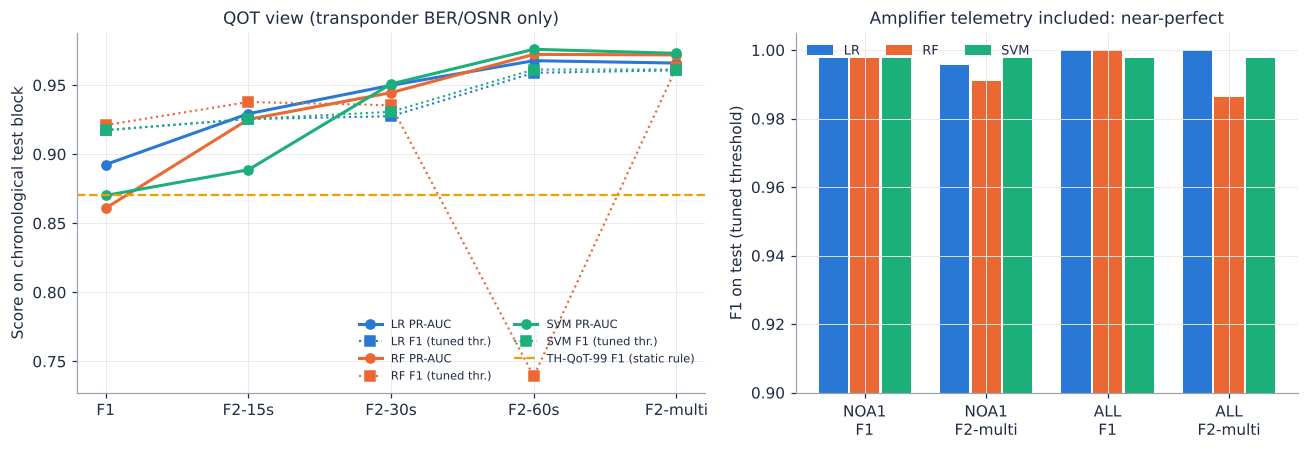

In [26]:
# Feature-set comparison figure (test PR-AUC and F1 at the tuned threshold)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={'width_ratios': [5, 4]})
sub = det[(det['view'] == 'QOT') & (det['threshold'] == 'tuned')]
xx = np.arange(len(FSETS))
for i, mdl in enumerate(MODELS):
    v = sub[sub['model'] == mdl].set_index('fset').loc[FSETS]
    axes[0].plot(xx, v['pr_auc'], marker='o', color=MODEL_COLORS[mdl], label=f'{mdl} PR-AUC', lw=2)
    axes[0].plot(xx, v['f1'], marker='s', color=MODEL_COLORS[mdl], ls=':', label=f'{mdl} F1 (tuned thr.)')
th = base_soft.set_index('model')
axes[0].axhline(th.loc['TH-QoT-99', 'f1'], color=MODEL_COLORS['Threshold'], lw=1.5, ls='--',
                label='TH-QoT-99 F1 (static rule)')
axes[0].set_xticks(xx, FSETS)
axes[0].set_ylabel('Score on chronological test block')
axes[0].set_title('QOT view (transponder BER/OSNR only)')
axes[0].legend(ncol=2, fontsize=7.5, loc='lower right')
sub2 = det[(det['view'] != 'QOT') & (det['threshold'] == 'tuned')]
labels = [f'{v}\n{f}' for v, f in [('NOA1', 'F1'), ('NOA1', 'F2-multi'), ('ALL', 'F1'), ('ALL', 'F2-multi')]]
xx2 = np.arange(len(labels))
for i, mdl in enumerate(MODELS):
    vals = [sub2[(sub2['view'] == v) & (sub2['fset'] == f) & (sub2['model'] == mdl)]['f1'].iloc[0]
            for v, f in [('NOA1', 'F1'), ('NOA1', 'F2-multi'), ('ALL', 'F1'), ('ALL', 'F2-multi')]]
    axes[1].bar(xx2 + (i - 1) * 0.26, vals, width=0.24, color=MODEL_COLORS[mdl], label=mdl)
axes[1].set_xticks(xx2, labels)
axes[1].set_ylim(0.9, 1.005)
axes[1].set_ylabel('F1 on test (tuned threshold)')
axes[1].set_title('Amplifier telemetry included: near-perfect')
axes[1].legend(ncol=3)
fig.tight_layout()
savefig(fig, 'fig08_feature_set_comparison')
plt.show()

## 9. Class-imbalance strategies (QOT view)
Compared for each model on F1 and F2-multi: no handling; cost-sensitive `class_weight='balanced'`;
SMOTE inside an `imblearn` pipeline (oversampling happens only when fitting on training folds; the
validation/test data are never resampled); and decision-threshold tuning on the chronological
validation block (F2-optimal) applied on top of each. The final strategy is chosen on **validation F2**
(test results are shown for transparency only), with a pre-declared tie rule (Section 9.1).

In [27]:
imb_rows = []
for fs in ['F1', 'F2-multi']:
    for mdl in MODELS:
        for strat in ['none', 'balanced', 'smote']:
            res = run_config('soft', 'T0', 'QOT', fs, mdl, strat)
            for thr in ['default', 'tuned']:
                for part in ['val', 'test']:
                    r = evaluate(res, part, thr)
                    r['strategy_label'] = strat + (' + thr. tuning' if thr == 'tuned' else '')
                    imb_rows.append(r)
            print(fs, mdl, strat, res['params'])
imb = pd.DataFrame(imb_rows)
save_table(imb[['fset', 'model', 'strategy_label', 'partition', 'recall', 'precision', 'f1', 'f2', 'pr_auc', 'mcc',
                'threshold_value', 'params', 'tp', 'fp', 'fn', 'tn', 'prevalence']],
           'tab17_soft_imbalance_strategies_QOT')
# choose the final strategy per (fset, model) on validation F2
val_choice = (imb[imb['partition'] == 'val'].sort_values(['fset', 'model', 'f2', 'precision'], ascending=[True, True, False, False])
              .groupby(['fset', 'model']).head(1)[['fset', 'model', 'strategy_label', 'f2', 'recall', 'precision']])
save_table(val_choice, 'tab18_soft_imbalance_choice_on_validation')
# mean validation F2 across models per strategy (to pick one strategy for the whole study)
strat_rank = imb[imb['partition'] == 'val'].groupby('strategy_label')[['f2', 'recall', 'precision', 'pr_auc']].mean() \
    .sort_values('f2', ascending=False)
save_table(strat_rank.reset_index(), 'tab19_soft_imbalance_strategy_ranking_validation')
print(strat_rank.round(4))
val_choice

F1 LR none {'clf__C': 0.01}
F1 LR balanced {'clf__C': 0.01}


F1 LR smote {'clf__C': 0.01}


F1 RF none {'clf__max_depth': 12, 'clf__min_samples_leaf': 1}
F1 RF balanced {'clf__max_depth': 12, 'clf__min_samples_leaf': 1}


F1 RF smote {'clf__max_depth': None, 'clf__min_samples_leaf': 10}


F1 SVM none {'clf__C': 0.1, 'clf__gamma': 0.025}
F1 SVM balanced {'clf__C': 1, 'clf__gamma': 0.25}


F1 SVM smote {'clf__C': 1, 'clf__gamma': 0.25}


... (3 outputs left out)

F2-multi RF smote {'clf__max_depth': 12, 'clf__min_samples_leaf': 10}


F2-multi SVM none {'clf__C': 10, 'clf__gamma': 0.00125}
F2-multi SVM balanced {'clf__C': 10, 'clf__gamma': 0.00125}


F2-multi SVM smote {'clf__C': 10, 'clf__gamma': 0.00125}
saved ../tables/tab17_soft_imbalance_strategies_QOT.csv
saved ../tables/tab18_soft_imbalance_choice_on_validation.csv
saved ../tables/tab19_soft_imbalance_strategy_ranking_validation.csv
                            f2  recall  precision  pr_auc
strategy_label                                           
smote + thr. tuning     0.9330  0.9338     0.9307  0.9418
none + thr. tuning      0.9325  0.9306     0.9429  0.9363
balanced + thr. tuning  0.9321  0.9314     0.9368  0.9358
smote                   0.9297  0.9297     0.9311  0.9418
balanced                0.9293  0.9289     0.9323  0.9358
none                    0.9213  0.9167     0.9412  0.9363


,fset,model,strategy_label,f2,recall,precision
6,F1,LR,balanced + thr. tuning,0.923226,0.931373,0.892019
22,F1,RF,smote + thr. tuning,0.925926,0.931373,0.904762
30,F1,SVM,balanced + thr. tuning,0.922330,0.931373,0.887850
38,F2-multi,LR,none + thr. tuning,0.943396,0.931373,0.994764
58,F2-multi,RF,smote + thr. tuning,0.947007,0.946078,0.950739
62,F2-multi,SVM,none + thr. tuning,0.939364,0.926471,0.994737


saved ../figures/fig09_imbalance_strategies.png


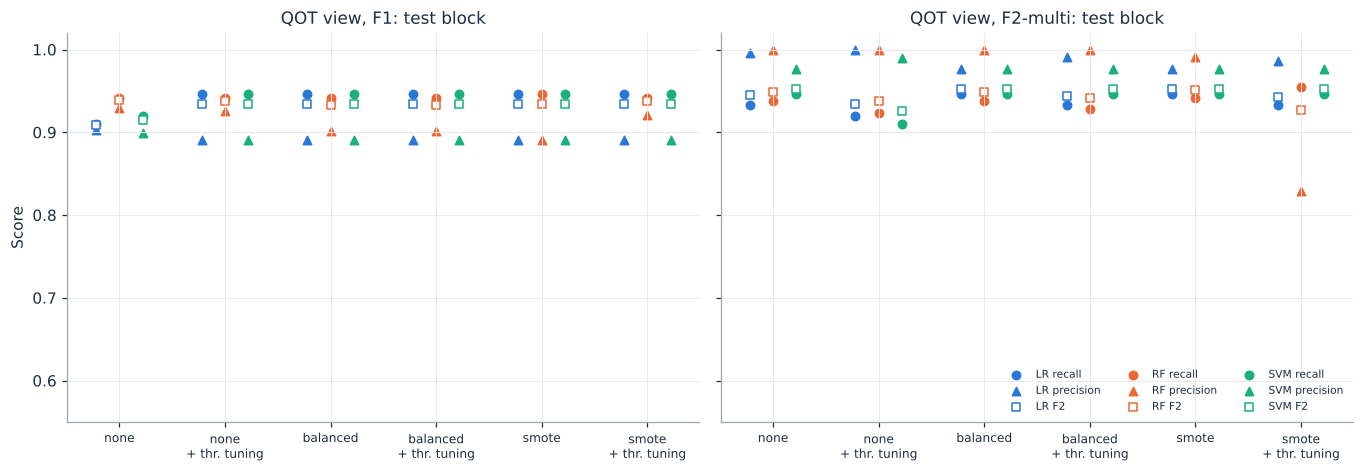

In [28]:
piv = imb[imb['partition'] == 'test'].copy()
strat_order = ['none', 'none + thr. tuning', 'balanced', 'balanced + thr. tuning', 'smote', 'smote + thr. tuning']
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4), sharey=True)
for ax, fs in zip(axes, ['F1', 'F2-multi']):
    for i, mdl in enumerate(MODELS):
        v = piv[(piv['fset'] == fs) & (piv['model'] == mdl)].set_index('strategy_label').loc[strat_order]
        x = np.arange(len(strat_order)) + (i - 1) * 0.22
        ax.scatter(x, v['recall'], marker='o', color=MODEL_COLORS[mdl], s=30, label=f'{mdl} recall')
        ax.scatter(x, v['precision'], marker='^', color=MODEL_COLORS[mdl], s=30, label=f'{mdl} precision')
        ax.scatter(x, v['f2'], marker='s', facecolor='white', edgecolor=MODEL_COLORS[mdl], s=34, label=f'{mdl} F2')
    ax.set_xticks(np.arange(len(strat_order)), [s.replace(' + ', '\n+ ') for s in strat_order], fontsize=8)
    ax.set_title(f'QOT view, {fs}: test block')
    ax.set_ylim(0.55, 1.02)
axes[0].set_ylabel('Score')
axes[1].legend(ncol=3, fontsize=7, loc='lower right')
fig.tight_layout()
savefig(fig, 'fig09_imbalance_strategies')
plt.show()

### 9.1 Final configuration and random-forest seed variability
The final strategy (selected on validation, see table above) is applied to all models. RF is
re-fitted with 5 seeds (same hyperparameters) and reported as mean +/- sd; SMOTE-based pipelines
also re-sample with each seed.

In [29]:
# Selection rule (decided before looking at test results): strategies whose mean validation F2 is within
# 0.005 of the best are treated as equivalent; among them the least invasive is preferred, in the order
# threshold tuning only -> cost-sensitive -> cost-sensitive + threshold -> no handling -> SMOTE -> SMOTE +
# threshold (SMOTE synthesises interpolated records from strongly autocorrelated neighbours and is the
# most expensive option).
SIMPLICITY = ['none + thr. tuning', 'balanced', 'balanced + thr. tuning', 'none', 'smote', 'smote + thr. tuning']
best_f2 = strat_rank['f2'].max()
eligible = [s for s in SIMPLICITY if strat_rank.loc[s, 'f2'] >= best_f2 - 0.005]
FINAL_STRATEGY_LABEL = eligible[0]
SUMMARY['strategy_ranking_validation'] = strat_rank.round(4).reset_index().to_dict(orient='records')
FINAL_STRATEGY = FINAL_STRATEGY_LABEL.split(' + ')[0]
FINAL_THR = 'tuned' if 'thr. tuning' in FINAL_STRATEGY_LABEL else 'default'
SUMMARY['final_strategy'] = FINAL_STRATEGY_LABEL
print('best mean validation F2:', round(best_f2, 4), '| equivalent strategies:', eligible)
print('final imbalance strategy:', FINAL_STRATEGY_LABEL)

final_rows = []
for view, fs in [('QOT', 'F1'), ('QOT', 'F2-multi'), ('NOA1', 'F1'), ('ALL', 'F1'), ('ALL', 'F2-multi')]:
    for mdl in MODELS:
        base = run_config('soft', 'T0', view, fs, mdl, FINAL_STRATEGY)
        seeds = RF_SEEDS if mdl == 'RF' or FINAL_STRATEGY == 'smote' else [SEED]
        for sd in seeds:
            res = base if sd == SEED else run_config('soft', 'T0', view, fs, mdl, FINAL_STRATEGY, seed=sd,
                                                     params=base['params'])
            r = evaluate(res, 'test', FINAL_THR)
            final_rows.append(r)
final = pd.DataFrame(final_rows)
mcols = ['recall', 'precision', 'f1', 'f2', 'pr_auc', 'roc_auc', 'mcc', 'balanced_acc', 'accuracy', 'tp', 'fp', 'fn', 'tn']
final_agg = final.groupby(['view', 'fset', 'model'])[mcols].agg(['mean', 'std']).round(4)
final_agg.columns = [f'{a}_{b}' for a, b in final_agg.columns]
final_agg = final_agg.reset_index()
final_agg['n_seeds'] = final.groupby(['view', 'fset', 'model']).size().values
save_table(final_agg, 'tab20_soft_final_models_test_mean_sd')
final_agg

best mean validation F2: 0.933 | equivalent strategies: ['none + thr. tuning', 'balanced', 'balanced + thr. tuning', 'smote', 'smote + thr. tuning']
final imbalance strategy: none + thr. tuning


saved ../tables/tab20_soft_final_models_test_mean_sd.csv


,view,fset,model,recall_mean,recall_std,precision_mean,precision_std,f1_mean,f1_std,f2_mean,...,accuracy_std,tp_mean,tp_std,fp_mean,fp_std,fn_mean,fn_std,tn_mean,tn_std,n_seeds
0,ALL,F1,LR,1.0000,NaN,1.0000,NaN,1.0000,NaN,1.0000,...,NaN,223.0,NaN,0.0,NaN,0.0,NaN,1150.0,NaN,1
1,ALL,F1,RF,0.9991,0.0020,1.0000,0.0000,0.9996,0.0010,0.9993,...,0.0003,222.8,0.4472,0.0,0.0000,0.2,0.4472,1150.0,0.0000,5
2,ALL,F1,SVM,1.0000,NaN,0.9955,NaN,0.9978,NaN,0.9991,...,NaN,223.0,NaN,1.0,NaN,0.0,NaN,1149.0,NaN,1
3,ALL,F2-multi,LR,1.0000,NaN,1.0000,NaN,1.0000,NaN,1.0000,...,NaN,223.0,NaN,0.0,NaN,0.0,NaN,1150.0,NaN,1
4,ALL,F2-multi,RF,0.9910,0.0045,1.0000,0.0000,0.9955,0.0023,0.9928,...,0.0007,221.0,1.0000,0.0,0.0000,2.0,1.0000,1150.0,0.0000,5
5,ALL,F2-multi,SVM,1.0000,NaN,0.9955,NaN,0.9978,NaN,0.9991,...,NaN,223.0,NaN,1.0,NaN,0.0,NaN,1149.0,NaN,1
6,NOA1,F1,LR,1.0000,NaN,0.9955,NaN,0.9978,NaN,0.9991,...,NaN,223.0,NaN,1.0,NaN,0.0,NaN,1149.0,NaN,1
7,NOA1,F1,RF,1.0000,0.0000,0.9955,0.0000,0.9978,0.0000,0.9991,...,0.0000,223.0,0.0000,1.0,0.0000,0.0,0.0000,1149.0,0.0000,5
8,NOA1,F1,SVM,1.0000,NaN,0.9955,NaN,0.9978,NaN,0.9991,...,NaN,223.0,NaN,1.0,NaN,0.0,NaN,1149.0,NaN,1
9,QOT,F1,LR,0.9462,NaN,0.8903,NaN,0.9174,NaN,0.9345,...,NaN,211.0,NaN,26.0,NaN,12.0,NaN,1124.0,NaN,1


saved ../figures/fig10_model_comparison_test.png


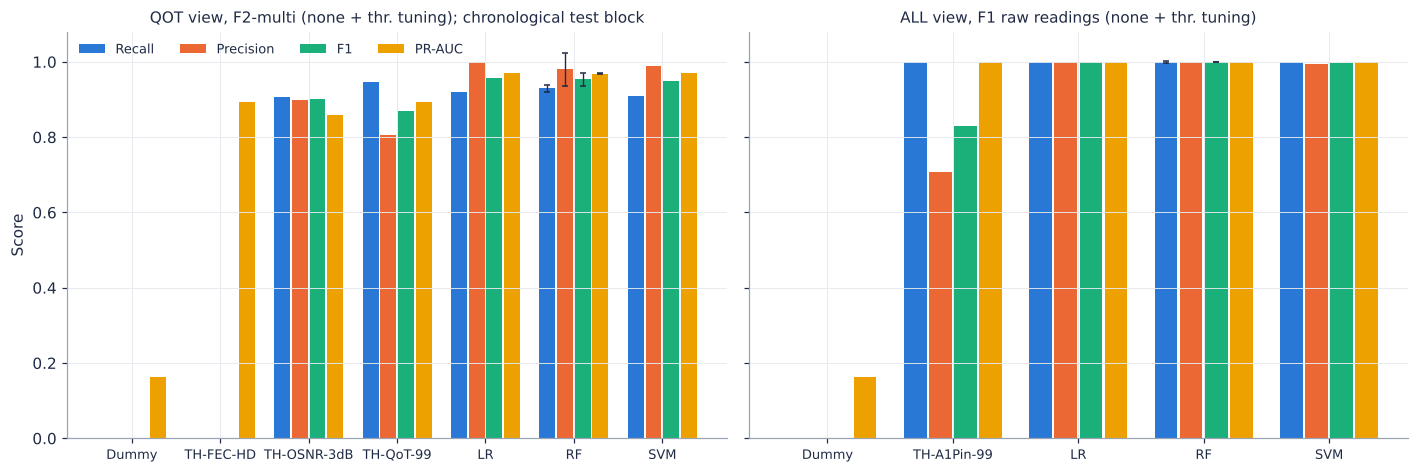

In [30]:
# Model comparison bar chart: QOT F2-multi (main) and ALL F1 vs baselines
def bar_block(ax, labels, table, title):
    metrics = ['recall', 'precision', 'f1', 'pr_auc']
    names = {'recall': 'Recall', 'precision': 'Precision', 'f1': 'F1', 'pr_auc': 'PR-AUC'}
    xx = np.arange(len(labels))
    for i, met in enumerate(metrics):
        vals = [table[l][met] for l in labels]
        errs = [table[l].get(met + '_sd', 0) for l in labels]
        ax.bar(xx + (i - 1.5) * 0.2, vals, width=0.18, color=PAL[i], label=names[met])
        for x_, v_, e_ in zip(xx + (i - 1.5) * 0.2, vals, errs):
            if e_ > 0:
                ax.errorbar(x_, v_, yerr=e_, color=NAVY, elinewidth=0.9, capsize=2)
    ax.set_xticks(xx, labels, fontsize=8.5)
    ax.set_ylim(0, 1.08)
    ax.set_title(title, fontsize=10)


def table_for(view, fs):
    tb = {}
    for mdl in MODELS:
        r = final_agg[(final_agg['view'] == view) & (final_agg['fset'] == fs) & (final_agg['model'] == mdl)].iloc[0]
        tb[mdl] = {m: r[f'{m}_mean'] for m in ['recall', 'precision', 'f1', 'pr_auc']}
        tb[mdl].update({m + '_sd': (0 if np.isnan(r[f'{m}_std']) else r[f'{m}_std']) for m in ['recall', 'precision', 'f1', 'pr_auc']})
    bs = base_soft.set_index('model')
    for nm in ['Dummy', 'TH-FEC-HD', 'TH-QoT-99', 'TH-OSNR-3dB', 'TH-A1Pin-99']:
        tb[nm] = {m: bs.loc[nm, m] for m in ['recall', 'precision', 'f1', 'pr_auc']}
        tb[nm]['pr_auc'] = 0 if np.isnan(tb[nm]['pr_auc']) else tb[nm]['pr_auc']
    return tb


fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
bar_block(axes[0], ['Dummy', 'TH-FEC-HD', 'TH-OSNR-3dB', 'TH-QoT-99', 'LR', 'RF', 'SVM'], table_for('QOT', 'F2-multi'),
          f'QOT view, F2-multi ({FINAL_STRATEGY_LABEL}); chronological test block')
bar_block(axes[1], ['Dummy', 'TH-A1Pin-99', 'LR', 'RF', 'SVM'], table_for('ALL', 'F1'),
          f'ALL view, F1 raw readings ({FINAL_STRATEGY_LABEL})')
axes[0].set_ylabel('Score')
axes[0].legend(ncol=4, loc='upper left')
fig.tight_layout()
savefig(fig, 'fig10_model_comparison_test')
plt.show()

saved ../figures/fig11_pr_curves_test.png


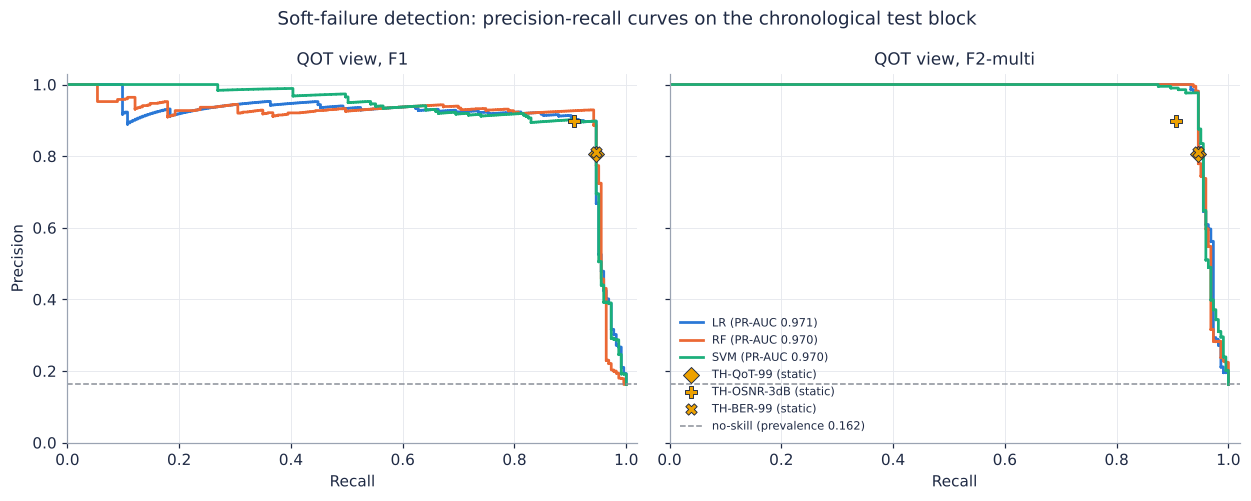

In [31]:
# Precision-recall curves on the test block (QOT view)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6), sharey=True)
for ax, fs in zip(axes, ['F1', 'F2-multi']):
    for mdl in MODELS:
        res = run_config('soft', 'T0', 'QOT', fs, mdl, FINAL_STRATEGY)
        y = res['y'][res['idx']['test']]
        p, r, _ = precision_recall_curve(y, res['s_test'])
        ax.step(r, p, where='post', color=MODEL_COLORS[mdl], lw=1.8,
                label=f"{mdl} (PR-AUC {average_precision_score(y, res['s_test']):.3f})")
    for nm, mk in [('TH-QoT-99', 'D'), ('TH-OSNR-3dB', 'P'), ('TH-BER-99', 'X')]:
        b = base_soft.set_index('model').loc[nm]
        ax.scatter(b['recall'], b['precision'], marker=mk, s=55, color=MODEL_COLORS['Threshold'],
                   edgecolor=NAVY, lw=0.6, zorder=5, label=f'{nm} (static)')
    ax.axhline(y.mean(), color=GREY, lw=1, ls='--', label=f'no-skill (prevalence {y.mean():.3f})')
    ax.set_xlabel('Recall')
    ax.set_title(f'QOT view, {fs}')
    ax.set_xlim(0, 1.02)
    ax.set_ylim(0, 1.03)
axes[0].set_ylabel('Precision')
axes[1].legend(fontsize=7.5, loc='lower left')
fig.suptitle('Soft-failure detection: precision-recall curves on the chronological test block', color=NAVY)
fig.tight_layout()
savefig(fig, 'fig11_pr_curves_test')
plt.show()

saved ../figures/fig12_confusion_matrices.png
saved ../tables/tab21_soft_confusion_matrices_test.csv


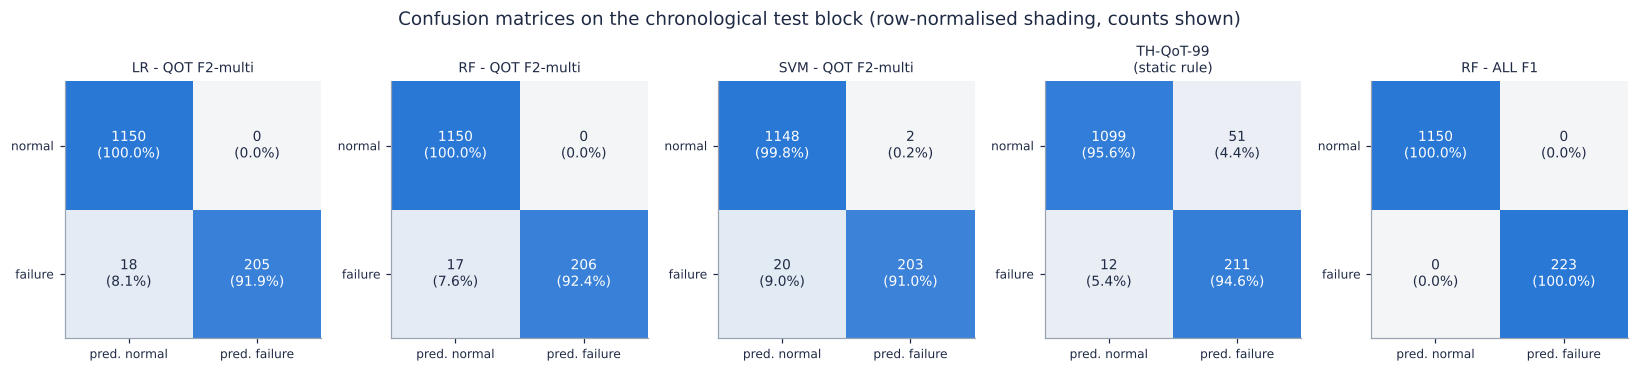

In [32]:
# Confusion matrices (test block)
cm_items = [('LR', 'QOT', 'F2-multi'), ('RF', 'QOT', 'F2-multi'), ('SVM', 'QOT', 'F2-multi'), ('TH-QoT-99', 'QOT', 'F1'),
            ('RF', 'ALL', 'F1')]
fig, axes = plt.subplots(1, len(cm_items), figsize=(15, 3.4))
cm_rows = []
for ax, (mdl, view, fs) in zip(axes, cm_items):
    if mdl.startswith('TH'):
        y, _ = make_target('soft', 'T0')
        m = SPLITS['soft']['test']
        _, alarm, _ = rule_scores('soft', mdl)
        cmx = confusion_matrix(y[m], alarm[m], labels=[0, 1])
        title = f'{mdl}\n(static rule)'
    else:
        res = run_config('soft', 'T0', view, fs, mdl, FINAL_STRATEGY)
        y = res['y'][res['idx']['test']]
        th = res['thr_tuned'] if FINAL_THR == 'tuned' else res['thr_default']
        cmx = confusion_matrix(y, res['s_test'] >= th, labels=[0, 1])
        title = f'{mdl} - {view} {fs}'
    cm_rows.append({'model': mdl, 'view': view, 'fset': fs, 'tn': cmx[0, 0], 'fp': cmx[0, 1], 'fn': cmx[1, 0], 'tp': cmx[1, 1]})
    ax.imshow(cmx / cmx.sum(axis=1, keepdims=True), cmap=LinearSegmentedColormap.from_list('b', ['#f4f5f7', PAL[0]]),
              vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            frac = cmx[i, j] / cmx[i].sum()
            ax.text(j, i, f'{cmx[i, j]}\n({frac:.1%})', ha='center', va='center', fontsize=9,
                    color='white' if frac > 0.6 else NAVY)
    ax.set_xticks([0, 1], ['pred. normal', 'pred. failure'], fontsize=8)
    ax.set_yticks([0, 1], ['normal', 'failure'], fontsize=8)
    ax.grid(False)
    ax.set_title(title, fontsize=9)
fig.suptitle('Confusion matrices on the chronological test block (row-normalised shading, counts shown)', color=NAVY)
fig.tight_layout()
savefig(fig, 'fig12_confusion_matrices')
save_table(pd.DataFrame(cm_rows), 'tab21_soft_confusion_matrices_test')
plt.show()

## 10. Early identification
### 10.1 Event-level detection delay and lead time over conventional thresholds
For every failure event in the test block we record the first alarm in [onset, end + 10 s]
(`detection delay` = alarm time - onset; 0 s means the alarm is raised in the very polling cycle in
which the label switches on). The **lead time over a conventional alarm** is the conventional
rule's delay minus the model's delay for the same event. False-alarm episodes are maximal runs of
alarms that do not overlap any [onset, end + 10 s] window, expressed per hour of monitored time.

In [33]:
def event_eval(k, part, alarm, mode='detect', H=0, tail=TAIL_S):
    """alarm: binary array over all aligned cycles (NaN/0 outside the partition is fine)."""
    A, ev = ALIGNED[k], EVENTS[k]
    m = SPLITS[k][part]
    t = A['t'].values
    al = np.asarray(alarm).astype(bool) & m
    rows = []
    covered = np.zeros(len(A), bool)
    for _, e in ev.iterrows():
        in_block = m[(t >= e['onset_t']) & (t <= e['end_t'])]
        if not in_block.any() or not in_block.all():
            continue
        win = (t >= e['onset_t'] - (H if mode == 'warn' else 0)) & (t <= e['end_t'] + tail)
        covered |= win
        r = {'onset_t': e['onset_t']}
        det_w = al & (t >= e['onset_t']) & (t <= e['end_t'] + tail)
        r['detected'] = bool(det_w.any())
        r['delay_s'] = (t[det_w].min() - e['onset_t']) if det_w.any() else np.nan
        if mode == 'warn':
            pre = al & (t >= e['onset_t'] - H) & (t < e['onset_t'])
            r['warned'] = bool(pre.any())
            r['lead_s'] = (e['onset_t'] - t[pre].min()) if pre.any() else np.nan
        rows.append(r)
    per_event = pd.DataFrame(rows)
    # false alarm episodes outside the event windows
    fa = al & ~covered
    episodes = int(np.sum(np.diff(np.r_[0, fa[m].astype(int)]) == 1))
    hours = m.sum() * np.median(np.diff(t)) / 3600
    summary = {'events': len(per_event), 'detected': int(per_event['detected'].sum()) if len(per_event) else 0,
               'detection_rate': per_event['detected'].mean() if len(per_event) else np.nan,
               'delay_median_s': per_event['delay_s'].median(), 'delay_mean_s': per_event['delay_s'].mean(),
               'delay_min_s': per_event['delay_s'].min(), 'delay_max_s': per_event['delay_s'].max(),
               'false_alarm_episodes': episodes, 'false_alarm_episodes_per_h': episodes / hours,
               'false_alarm_cycles': int(fa.sum()), 'monitored_h': hours}
    normal_block = m & (A['y'].values == 0)
    summary['alarm_rate_normal_cycles'] = al[normal_block].mean()
    if mode == 'warn':
        # chance level: probability that an alarm process with the same per-cycle alarm rate on normal
        # cycles fires at least once in the n pre-onset cycles of each event
        r = al[normal_block].mean()
        n_pre = [int((m & (t >= o - H) & (t < o)).sum()) for o in per_event['onset_t']]
        chance = np.mean([1 - (1 - r) ** n_ for n_ in n_pre]) if len(n_pre) else np.nan
        summary.update({'warned': int(per_event['warned'].sum()), 'warning_rate': per_event['warned'].mean(),
                        'chance_warning_rate': chance,
                        'lead_median_s': per_event['lead_s'].median(), 'lead_mean_s': per_event['lead_s'].mean()})
    return per_event, summary


def model_alarm(k, res, part='test', thr=None):
    th = (res['thr_tuned'] if FINAL_THR == 'tuned' else res['thr_default']) if thr is None else thr
    al = np.zeros(len(ALIGNED[k]), bool)
    al[res['idx'][part]] = res[f's_{part}'] >= th
    return al


detectors = {}
for nm in ['TH-FEC-HD', 'TH-FEC-SD', 'TH-OSNR-3dB', 'TH-BER-99', 'TH-OSNR-99', 'TH-QoT-99', 'TH-A1Pin-99']:
    detectors[nm] = rule_scores('soft', nm)[1].astype(bool)
for view, fs in [('QOT', 'F1'), ('QOT', 'F2-multi'), ('NOA1', 'F1'), ('ALL', 'F1')]:
    for mdl in MODELS:
        detectors[f'{mdl} {view} {fs}'] = model_alarm('soft', run_config('soft', 'T0', view, fs, mdl, FINAL_STRATEGY))

ev_rows, per_ev = [], {}
for nm, al in detectors.items():
    pe, s = event_eval('soft', 'test', al)
    per_ev[nm] = pe
    s['detector'] = nm
    ev_rows.append(s)
ev_tab = pd.DataFrame(ev_rows)
# lead time over the conventional receiver alarm (TH-QoT-99), per event
ref = per_ev['TH-QoT-99'].set_index('onset_t')['delay_s']
for nm in ev_tab['detector']:
    d = per_ev[nm].set_index('onset_t')['delay_s']
    lead = (ref - d).dropna()
    ev_tab.loc[ev_tab['detector'] == nm, 'lead_vs_TH-QoT-99_median_s'] = lead.median() if len(lead) else np.nan
    ev_tab.loc[ev_tab['detector'] == nm, 'lead_vs_TH-QoT-99_mean_s'] = lead.mean() if len(lead) else np.nan
    ev_tab.loc[ev_tab['detector'] == nm, 'events_earlier_than_TH-QoT-99'] = int((lead > 0).sum())
ev_tab = ev_tab[['detector'] + [c for c in ev_tab.columns if c != 'detector']]
save_table(ev_tab, 'tab22_soft_event_level_detection_delay_test')
pd.concat([pe.assign(detector=nm) for nm, pe in per_ev.items()]).to_csv(TAB_DIR / 'tab22b_soft_event_level_per_event_test.csv', index=False)
ev_tab.round(3)

saved ../tables/tab22_soft_event_level_detection_delay_test.csv


,detector,events,detected,detection_rate,delay_median_s,delay_mean_s,delay_min_s,delay_max_s,false_alarm_episodes,false_alarm_episodes_per_h,false_alarm_cycles,monitored_h,alarm_rate_normal_cycles,lead_vs_TH-QoT-99_median_s,lead_vs_TH-QoT-99_mean_s,events_earlier_than_TH-QoT-99
0,TH-FEC-HD,12,0,0.0,NaN,NaN,NaN,NaN,0,0.000,0,1.144,0.000,NaN,NaN,0.0
1,TH-FEC-SD,12,0,0.0,NaN,NaN,NaN,NaN,0,0.000,0,1.144,0.000,NaN,NaN,0.0
2,TH-OSNR-3dB,12,12,1.0,6.0,5.75,3.0,7.0,0,0.000,0,1.144,0.020,-3.0,-2.50,0.0
3,TH-BER-99,12,12,1.0,3.0,3.25,0.0,6.0,10,8.740,23,1.144,0.043,0.0,0.00,0.0
4,TH-OSNR-99,12,12,1.0,6.0,5.50,3.0,7.0,3,2.622,3,1.144,0.023,-3.0,-2.25,0.0
5,TH-QoT-99,12,12,1.0,3.0,3.25,0.0,6.0,12,10.488,25,1.144,0.044,0.0,0.00,0.0
6,TH-A1Pin-99,12,12,1.0,0.0,0.00,0.0,0.0,7,6.118,89,1.144,0.080,3.0,3.25,11.0
7,LR QOT F1,12,12,1.0,3.0,3.25,0.0,6.0,0,0.000,0,1.144,0.023,0.0,0.00,0.0
8,RF QOT F1,12,12,1.0,3.0,3.50,0.0,6.0,0,0.000,0,1.144,0.015,0.0,-0.25,0.0
9,SVM QOT F1,12,12,1.0,3.0,3.25,0.0,6.0,0,0.000,0,1.144,0.023,0.0,0.00,0.0


saved ../figures/fig13_detection_delay_vs_thresholds.png


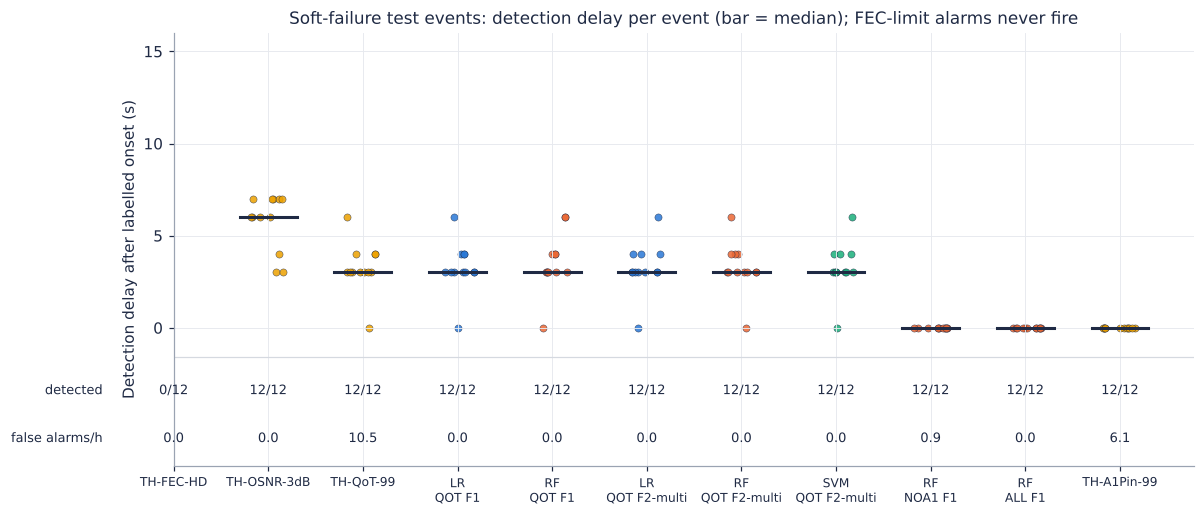

In [34]:
# Lead-time / delay distribution figure
show = ['TH-FEC-HD', 'TH-OSNR-3dB', 'TH-QoT-99', 'LR QOT F1', 'RF QOT F1', 'LR QOT F2-multi', 'RF QOT F2-multi',
        'SVM QOT F2-multi', 'RF NOA1 F1', 'RF ALL F1', 'TH-A1Pin-99']
fig, ax = plt.subplots(figsize=(11, 4.8))
rng = np.random.default_rng(0)
for i, nm in enumerate(show):
    pe = per_ev[nm]
    d = pe['delay_s'].dropna().values
    col = MODEL_COLORS['Threshold'] if nm.startswith('TH') else MODEL_COLORS[nm.split()[0]]
    if len(d):
        ax.scatter(np.full(len(d), i) + rng.uniform(-0.18, 0.18, len(d)), d, s=22, color=col, alpha=0.85,
                   edgecolor=NAVY, lw=0.3)
        ax.plot([i - 0.3, i + 0.3], [np.median(d)] * 2, color=NAVY, lw=2)
    ax.text(i, -3.6, f"{int(pe['detected'].sum())}/{len(pe)}", ha='center', fontsize=8.5)
    fa = ev_tab.loc[ev_tab['detector'] == nm, 'false_alarm_episodes_per_h'].iloc[0]
    ax.text(i, -6.2, f'{fa:.1f}', ha='center', fontsize=8.5)
ax.text(-0.75, -3.6, 'detected', ha='right', fontsize=8.5)
ax.text(-0.75, -6.2, 'false alarms/h', ha='right', fontsize=8.5)
ax.axhline(-1.6, color=LIGHTGREY, lw=0.8)
ax.set_xticks(range(len(show)), [s.replace(' ', '\n', 1) for s in show], fontsize=8)
ax.set_ylabel('Detection delay after labelled onset (s)')
ax.set_yticks([0, 5, 10, 15, 20])
ax.set_ylim(-7.5, max(16, ev_tab['delay_max_s'].max() + 3))
ax.set_title('Soft-failure test events: detection delay per event (bar = median); FEC-limit alarms never fire')
fig.tight_layout()
savefig(fig, 'fig13_detection_delay_vs_thresholds')
plt.show()

### 10.2 Prediction-horizon (pre-onset) early warning
Models are trained on the T_H target (F2-multi, QOT and ALL views, final imbalance strategy) and
evaluated on the test block's normal cycles. Event level: an event is *warned* if an alarm occurs in
[onset - H, onset). A **schedule-only diagnostic** scores each cycle by the time elapsed since the
previous event ended (known causally from past labels): because failures were injected on a fixed
~301 s cycle, this artefact alone predicts onsets; real soft failures would not be periodic.
A second timing diagnostic, the **WSS step clock** (time since the last >= 0.3 dB step of the Ampli1
input power), captures the fact that the WSS changes attenuation on a ~60 s clock and that every
injected failure starts on one of those steps. Neither diagnostic is used as a model feature; no
time-of-day, elapsed-time, index or time-since-event feature is given to any model.

In [35]:
hz_rows, hz_ev_rows = [], []
for H in HORIZONS_SOFT:
    task = f'H{H}'
    y, valid = make_target('soft', task)
    mt = SPLITS['soft']['test'] & valid
    # baselines
    hz_rows.append({**metrics_from(y[mt], np.zeros(mt.sum()), np.zeros(mt.sum())), 'H': H, 'model': 'Dummy', 'view': '-'})
    ev_s = EVENTS['soft']
    tA = ALIGNED['soft']['t'].values
    ends = ev_s['end_t'].values
    j = np.searchsorted(ends, tA, side='right') - 1
    since = np.where(j >= 0, tA - ends[np.maximum(j, 0)], 0.0)
    since[ALIGNED['soft']['y'].values == 1] = 0
    yv, sv = y[SPLITS['soft']['val'] & valid], since[SPLITS['soft']['val'] & valid]
    th_s = tune_threshold(yv, sv)
    hz_rows.append({**metrics_from(y[mt], since[mt], since[mt] >= th_s), 'H': H, 'model': 'Schedule-only (time since last event)',
                    'view': 'labels'})
    # Second timing diagnostic: the WSS changes attenuation on a ~60 s clock and every soft failure starts
    # on one of those steps, so "time since the last Ampli1 power step (>= 0.3 dB)" carries timing information.
    pin = ALIGNED['soft']['A1_Pin'].values
    step_t = tA[np.r_[False, np.abs(np.diff(pin)) >= 0.3]]
    js = np.searchsorted(step_t, tA, side='right') - 1
    since_step = np.where(js >= 0, tA - step_t[np.maximum(js, 0)], 0.0)
    th_p = tune_threshold(y[SPLITS['soft']['val'] & valid], since_step[SPLITS['soft']['val'] & valid])
    hz_rows.append({**metrics_from(y[mt], since_step[mt], since_step[mt] >= th_p), 'H': H,
                    'model': 'WSS step clock (time since last Ampli1 power step)', 'view': 'ALL'})
    for nm in ['TH-QoT-99', 'TH-A1Pin-99']:
        s, al, _ = rule_scores('soft', nm)
        hz_rows.append({**metrics_from(y[mt], s[mt], al[mt]), 'H': H, 'model': nm, 'view': 'QOT' if 'QoT' in nm else 'ALL'})
    for view in ['QOT', 'ALL']:
        for mdl in MODELS:
            res = run_config('soft', task, view, 'F2-multi', mdl, FINAL_STRATEGY)
            r = evaluate(res, 'test', FINAL_THR)
            r.update({'H': H, 'model': mdl})
            hz_rows.append(r)
            # event-level warning analysis: score every test cycle (also those in failure)
            Ft = FEATS['soft'].iloc[np.where(SPLITS['soft']['test'])[0]][res['cols']].values
            th = res['thr_tuned'] if FINAL_THR == 'tuned' else res['thr_default']
            al = np.zeros(len(ALIGNED['soft']), bool)
            al[SPLITS['soft']['test']] = model_scores(res['estimator'], Ft) >= th
            _, s = event_eval('soft', 'test', al, mode='warn', H=H)
            hz_ev_rows.append({'H': H, 'view': view, 'model': mdl, **s})
            print(f'H={H:3d} {view} {mdl}: PR-AUC={r["pr_auc"]:.3f} recall={r["recall"]:.3f} '
                  f'precision={r["precision"]:.3f} warned {s["warned"]}/{s["events"]} FA/h={s["false_alarm_episodes_per_h"]:.1f}')
    al = np.zeros(len(ALIGNED['soft']), bool)
    al[SPLITS['soft']['test']] = since[SPLITS['soft']['test']] >= th_s
    _, s = event_eval('soft', 'test', al, mode='warn', H=H)
    hz_ev_rows.append({'H': H, 'view': 'labels', 'model': 'Schedule-only', **s})
    al = np.zeros(len(ALIGNED['soft']), bool)
    al[SPLITS['soft']['test']] = since_step[SPLITS['soft']['test']] >= th_p
    _, s = event_eval('soft', 'test', al, mode='warn', H=H)
    hz_ev_rows.append({'H': H, 'view': 'ALL', 'model': 'WSS step clock', **s})
hz = pd.DataFrame(hz_rows)
hz_ev = pd.DataFrame(hz_ev_rows)
save_table(hz[['H', 'view', 'model', 'prevalence', 'n', 'recall', 'precision', 'f1', 'f2', 'pr_auc', 'roc_auc', 'mcc',
               'balanced_acc', 'tp', 'fp', 'fn', 'tn']], 'tab23_soft_horizon_sample_level_test')
save_table(hz_ev, 'tab24_soft_horizon_event_level_test')
hz[['H', 'view', 'model', 'prevalence', 'recall', 'precision', 'f1', 'pr_auc', 'roc_auc', 'mcc']].round(3)

H= 10 QOT LR: PR-AUC=0.121 recall=0.361 precision=0.070 warned 8/12 FA/h=55.9


H= 10 QOT RF: PR-AUC=0.041 recall=0.306 precision=0.053 warned 6/12 FA/h=46.3


H= 10 QOT SVM: PR-AUC=0.058 recall=0.472 precision=0.068 warned 9/12 FA/h=108.4


H= 10 ALL LR: PR-AUC=0.095 recall=0.667 precision=0.101 warned 12/12 FA/h=43.7


H= 10 ALL RF: PR-AUC=0.152 recall=0.833 precision=0.081 warned 12/12 FA/h=62.9


H= 10 ALL SVM: PR-AUC=0.089 recall=0.722 precision=0.071 warned 12/12 FA/h=97.0


... (15 outputs left out)

H=120 ALL LR: PR-AUC=0.432 recall=1.000 precision=0.474 warned 12/12 FA/h=10.5


H=120 ALL RF: PR-AUC=0.618 recall=0.981 precision=0.516 warned 12/12 FA/h=13.1


H=120 ALL SVM: PR-AUC=0.431 recall=0.998 precision=0.475 warned 12/12 FA/h=17.5
saved ../tables/tab23_soft_horizon_sample_level_test.csv
saved ../tables/tab24_soft_horizon_event_level_test.csv


,H,view,model,prevalence,recall,precision,f1,pr_auc,roc_auc,mcc
0,10,-,Dummy,0.031,0.000,0.000,0.000,0.031,0.500,0.000
1,10,labels,Schedule-only (time since last event),0.031,1.000,0.132,0.233,0.080,0.789,0.322
2,10,ALL,WSS step clock (time since last Ampli1 power s...,0.031,0.917,0.076,0.140,0.052,0.674,0.199
3,10,QOT,TH-QoT-99,0.031,0.000,0.000,0.000,0.039,0.593,-0.039
4,10,ALL,TH-A1Pin-99,0.031,0.111,0.043,0.062,0.071,0.640,0.020
5,10,QOT,LR,0.031,0.361,0.070,0.117,0.121,0.763,0.097
6,10,QOT,RF,0.031,0.306,0.053,0.091,0.041,0.564,0.059
7,10,QOT,SVM,0.031,0.472,0.068,0.119,0.058,0.622,0.111
8,10,ALL,LR,0.031,0.667,0.101,0.175,0.095,0.810,0.204
9,10,ALL,RF,0.031,0.833,0.081,0.147,0.152,0.826,0.196


In [36]:
# What do the early-warning models use? Grouped permutation importance (RF, test block, PR-AUC drop).
# Defined in Section 13; repeated here for the horizon models.
def _gpi(res, groups, n_repeats=20, seed=SEED):
    idx = res['idx']['test']
    X = FEATS['soft'].iloc[idx][res['cols']].reset_index(drop=True)
    y = res['y'][idx]
    base = average_precision_score(y, model_scores(res['estimator'], X.values))
    rng = np.random.default_rng(seed)
    rows = []
    for g, cols in groups.items():
        drops = []
        for _ in range(n_repeats):
            Xp = X.copy()
            Xp[cols] = X[cols].values[rng.permutation(len(Xp))]
            drops.append(base - average_precision_score(y, model_scores(res['estimator'], Xp.values)))
        rows.append({'group': g, 'pr_auc_drop_mean': np.mean(drops), 'pr_auc_drop_sd': np.std(drops), 'baseline_pr_auc': base})
    return pd.DataFrame(rows).sort_values('pr_auc_drop_mean', ascending=False)


hz_imp = []
for H in [10, 30, 60]:
    for view in ['QOT', 'ALL']:
        res = run_config('soft', f'H{H}', view, 'F2-multi', 'RF', FINAL_STRATEGY)
        groups = {s: [c for c in res['cols'] if c.split('__')[0] == s] for s in view_signals('soft', view)}
        groups.update({f'all {w}s-window features': [c for c in res['cols'] if c.endswith(f'_{w}s')] for w in WINDOWS})
        hz_imp.append(_gpi(res, groups).assign(H=H, view=view))
hz_imp = pd.concat(hz_imp, ignore_index=True)
save_table(hz_imp, 'tab24b_soft_horizon_rf_grouped_importance')
hz_imp.groupby(['H', 'view']).head(4).round(4)

saved ../tables/tab24b_soft_horizon_rf_grouped_importance.csv


,group,pr_auc_drop_mean,pr_auc_drop_sd,baseline_pr_auc,H,view
0,SPO2_OSNR,0.0048,0.0056,0.0413,10,QOT
1,all 30s-window features,0.0017,0.0041,0.0413,10,QOT
2,all 60s-window features,0.0011,0.0082,0.0413,10,QOT
3,SPO2_logBER,0.0005,0.0080,0.0413,10,QOT
7,A1_Pin,0.0810,0.0062,0.1517,10,ALL
8,all 60s-window features,0.0788,0.0101,0.1517,10,ALL
9,A3_Pin,0.0440,0.0042,0.1517,10,ALL
10,SPO2_OSNR,0.0303,0.0123,0.1517,10,ALL
19,all 60s-window features,0.0217,0.0111,0.1275,30,QOT
20,SPO2_OSNR,0.0157,0.0049,0.1275,30,QOT


saved ../figures/fig14_early_warning_horizons.png


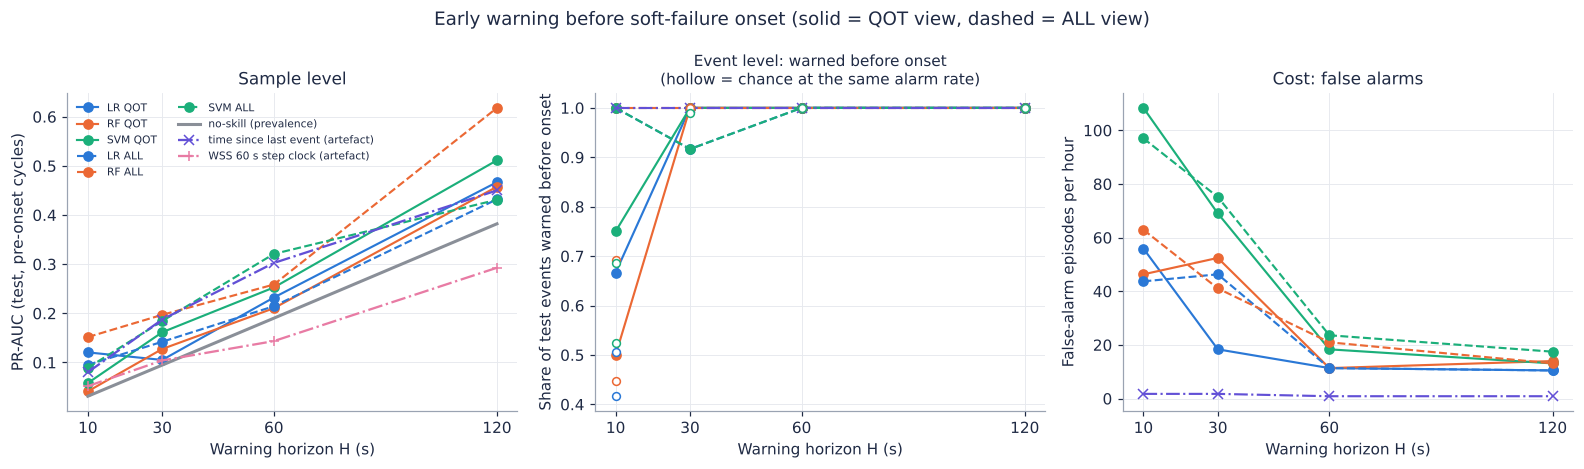

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.3))
Hs = list(HORIZONS_SOFT)
for view, ls in [('QOT', '-'), ('ALL', '--')]:
    for mdl in MODELS:
        v = hz[(hz['view'] == view) & (hz['model'] == mdl)].set_index('H').loc[Hs]
        axes[0].plot(Hs, v['pr_auc'], marker='o', ls=ls, color=MODEL_COLORS[mdl], label=f'{mdl} {view}')
        e = hz_ev[(hz_ev['view'] == view) & (hz_ev['model'] == mdl)].set_index('H').loc[Hs]
        axes[1].plot(Hs, e['warning_rate'], marker='o', ls=ls, color=MODEL_COLORS[mdl])
        axes[1].scatter(Hs, e['chance_warning_rate'], marker='o', facecolor='white', edgecolor=MODEL_COLORS[mdl],
                        s=26, zorder=4)
        axes[2].plot(Hs, e['false_alarm_episodes_per_h'], marker='o', ls=ls, color=MODEL_COLORS[mdl])
prev = hz[hz['model'] == 'Dummy'].set_index('H').loc[Hs, 'prevalence']
sched = hz[hz['model'].str.startswith('Schedule')].set_index('H').loc[Hs]
axes[0].plot(Hs, prev, color=GREY, lw=2, label='no-skill (prevalence)')
axes[0].plot(Hs, sched['pr_auc'], color=PAL[6], lw=1.5, ls='-.', marker='x', label='time since last event (artefact)')
stepc = hz[hz['model'].str.startswith('WSS step clock')].set_index('H').loc[Hs]
axes[0].plot(Hs, stepc['pr_auc'], color=PAL[4], lw=1.5, ls='-.', marker='+', label='WSS 60 s step clock (artefact)')
es = hz_ev[hz_ev['model'] == 'Schedule-only'].set_index('H').loc[Hs]
axes[1].plot(Hs, es['warning_rate'], color=PAL[6], ls='-.', marker='x')
axes[2].plot(Hs, es['false_alarm_episodes_per_h'], color=PAL[6], ls='-.', marker='x')
axes[0].set_ylabel('PR-AUC (test, pre-onset cycles)')
axes[1].set_ylabel('Share of test events warned before onset')
axes[2].set_ylabel('False-alarm episodes per hour')
for ax in axes:
    ax.set_xlabel('Warning horizon H (s)')
    ax.set_xticks(Hs)
axes[0].legend(fontsize=7, ncol=2)
axes[0].set_title('Sample level')
axes[1].set_title('Event level: warned before onset\n(hollow = chance at the same alarm rate)', fontsize=10)
axes[2].set_title('Cost: false alarms')
fig.suptitle('Early warning before soft-failure onset (solid = QOT view, dashed = ALL view)', color=NAVY)
fig.tight_layout()
savefig(fig, 'fig14_early_warning_horizons')
plt.show()

## 11. Temporal leakage: naive random stratified split vs chronological split
Same features, same hyperparameters (those tuned chronologically) and the same imbalance strategy
with default threshold. The random protocol uses (a) a single stratified 70/30 shuffle split and
(b) stratified 5-fold CV with shuffling, both over all cycles of the dataset - the design originally
proposed. Differences quantify the optimism caused by near-duplicate neighbouring cycles (and
overlapping rolling windows) appearing in both training and test data.

In [38]:
leak_rows = []
leak_plan = [('T0', 'QOT', 'F1'), ('T0', 'QOT', 'F2-multi'), ('T0', 'ALL', 'F1'), ('H30', 'QOT', 'F2-multi'),
             ('H60', 'QOT', 'F2-multi'), ('H30', 'ALL', 'F2-multi'), ('H60', 'ALL', 'F2-multi')]
for task, view, fs in leak_plan:
    y, valid = make_target('soft', task)
    vidx = np.where(valid)[0]
    F = FEATS['soft']
    for mdl in MODELS:
        chrono = run_config('soft', task, view, fs, mdl, FINAL_STRATEGY)
        rc = evaluate(chrono, 'test', 'default')
        leak_rows.append({**rc, 'protocol': 'chronological (test block)'})
        X = F.iloc[vidx][chrono['cols']].values
        yy = y[vidx]
        pipe, _ = make_model(mdl, FINAL_STRATEGY, len(chrono['cols']))
        pipe.set_params(**chrono['params'])
        Xa, Xb, ya, yb = train_test_split(X, yy, test_size=0.3, stratify=yy, random_state=SEED, shuffle=True)
        if mdl == 'SVM' and len(ya) > SVM_MAX_TRAIN:      # same training-size cap as in the chronological protocol
            keep = np.random.default_rng(SEED).choice(len(ya), SVM_MAX_TRAIN, replace=False)
            Xa, ya = Xa[keep], ya[keep]
        est = clone(pipe).fit(Xa, ya)
        s = model_scores(est, Xb)
        leak_rows.append({**metrics_from(yb, s, s >= default_threshold(est)), 'task': task, 'view': view, 'fset': fs,
                          'model': mdl, 'protocol': 'random stratified 70/30'})
        cvm = []
        for tr_i, te_i in StratifiedKFold(5, shuffle=True, random_state=SEED).split(X, yy):
            if mdl == 'SVM' and len(tr_i) > SVM_MAX_TRAIN:
                tr_i = np.random.default_rng(SEED).choice(tr_i, SVM_MAX_TRAIN, replace=False)
            est = clone(pipe).fit(X[tr_i], yy[tr_i])
            s = model_scores(est, X[te_i])
            cvm.append(metrics_from(yy[te_i], s, s >= default_threshold(est)))
        cvm = pd.DataFrame(cvm)
        leak_rows.append({**cvm.mean(numeric_only=True).to_dict(), **{f'{c}_sd': v for c, v in cvm.std(numeric_only=True).items()},
                          'task': task, 'view': view, 'fset': fs, 'model': mdl, 'protocol': 'random stratified 5-fold CV'})
    print('done', task, view, fs)
leak = pd.DataFrame(leak_rows)
save_table(leak[['task', 'view', 'fset', 'model', 'protocol', 'prevalence', 'recall', 'precision', 'f1', 'f2', 'pr_auc',
                 'roc_auc', 'mcc', 'balanced_acc', 'accuracy', 'f1_sd', 'pr_auc_sd']], 'tab25_soft_random_vs_chronological')
lk = leak.pivot_table(index=['task', 'view', 'fset', 'model'], columns='protocol', values=['f1', 'pr_auc']).round(4)
lk

done T0 QOT F1


done T0 QOT F2-multi


done T0 ALL F1


done H30 QOT F2-multi


done H60 QOT F2-multi


done H30 ALL F2-multi


done H60 ALL F2-multi
saved ../tables/tab25_soft_random_vs_chronological.csv


f1  \
protocol                 chronological (test block)   
task view fset     model                              
H30  ALL  F2-multi LR                        0.0000   
                   RF                        0.1463   
                   SVM                       0.0000   
     QOT  F2-multi LR                        0.0000   
                   RF                        0.0000   
                   SVM                       0.0000   
H60  ALL  F2-multi LR                        0.0093   
                   RF                        0.1203   
                   SVM                       0.0000   
     QOT  F2-multi LR                        0.0000   
                   RF                        0.0000   
                   SVM                       0.0000   
T0   ALL  F1       LR                        0.9978   
                   RF                        0.9978   
                   SVM                       0.9887   
     QOT  F1       LR                        0.9062   
                   RF                        0.9354   
                   SVM                       0.9091   
          F2-multi LR                        0.9630   
                   RF                        0.9676   
                   SVM                       0.9613   

                                                                              \
protocol                 random stratified 5-fold CV random stratified 70/30   
task view fset     model                                                       
H30  ALL  F2-multi LR                         0.0143                  0.0000   
                   RF                         0.3212                  0.2657   
                   SVM                        0.0096                  0.0000   
     QOT  F2-multi LR                         0.0000                  0.0000   
                   RF                         0.4780                  0.4848   
                   SVM                        0.0000                  0.0000   
H60  ALL  F2-multi LR                         0.0095                  0.0000   
                   RF                         0.8689                  0.8246   
                   SVM                        0.0000                  0.0000   
     QOT  F2-multi LR                         0.0000                  0.0000   
                   RF                         0.7284                  0.7342   
                   SVM                        0.0000                  0.0000   
T0   ALL  F1       LR                         0.9977                  0.9981   
                   RF                         0.9988                  1.0000   
                   SVM                        0.9900                  0.9961   
     QOT  F1       LR                         0.8997                  0.8919   
                   RF                         0.9218                  0.9112   
                   SVM                        0.9014                  0.8963   
          F2-multi LR                         0.9590                  0.9455   
                   RF                         0.9649                  0.9532   
                   SVM                        0.9552                  0.9457   

                                             pr_auc  \
protocol                 chronological (test block)   
task view fset     model                              
H30  ALL  F2-multi LR                        0.1422   
                   RF                        0.1970   
                   SVM                       0.1844   
     QOT  F2-multi LR                        0.1052   
                   RF                        0.1275   
                   SVM                       0.1615   
H60  ALL  F2-multi LR                        0.2144   
                   RF                        0.2586   
                   SVM                       0.3208   
     QOT  F2-multi LR                        0.2321   
                   RF                        0.2104   
                   SVM               

saved ../figures/fig15_random_vs_chronological.png


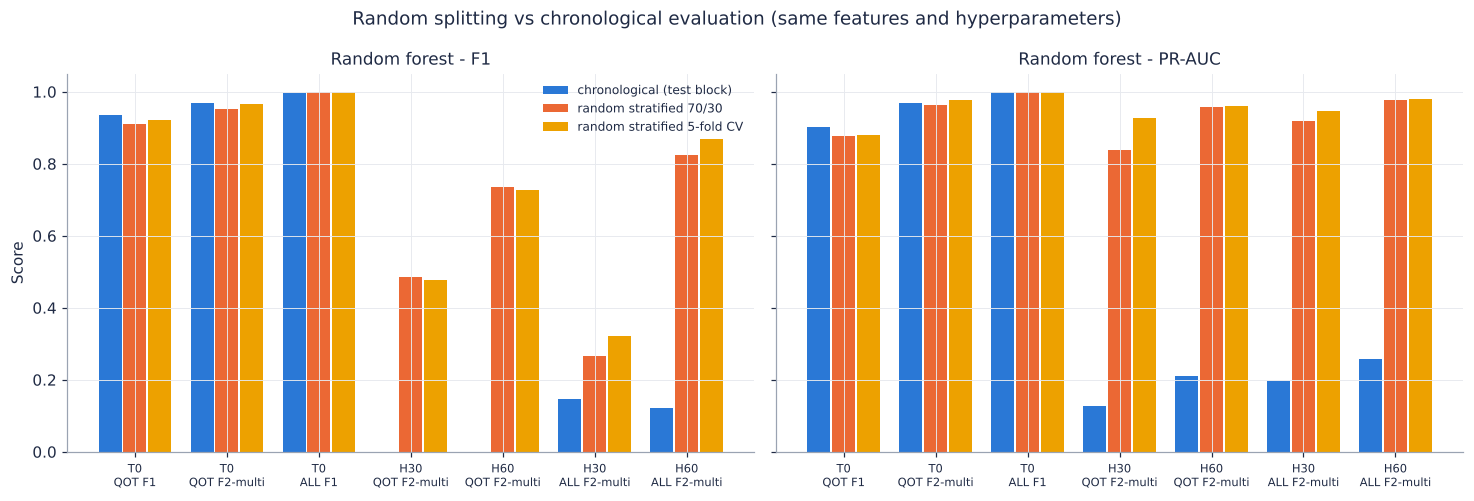

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6), sharey=True)
prots = ['chronological (test block)', 'random stratified 70/30', 'random stratified 5-fold CV']
pcol = {prots[0]: PAL[0], prots[1]: PAL[1], prots[2]: PAL[3]}
for ax, met in zip(axes, ['f1', 'pr_auc']):
    sub = leak[leak['model'] == 'RF']
    labels = [f'{t}\n{v} {f}' for t, v, f in leak_plan]
    xx = np.arange(len(leak_plan))
    for i, p in enumerate(prots):
        vals = [sub[(sub['task'] == t) & (sub['view'] == v) & (sub['fset'] == f) & (sub['protocol'] == p)][met].iloc[0]
                for t, v, f in leak_plan]
        ax.bar(xx + (i - 1) * 0.27, vals, width=0.25, color=pcol[p], label=p)
    ax.set_xticks(xx, labels, fontsize=7.5)
    ax.set_title(f'Random forest - {met.upper().replace("_", "-")}')
axes[0].set_ylabel('Score')
axes[0].legend(fontsize=8)
fig.suptitle('Random splitting vs chronological evaluation (same features and hyperparameters)', color=NAVY)
fig.tight_layout()
savefig(fig, 'fig15_random_vs_chronological')
plt.show()

## 12. Robustness: rolling-origin (forward-chaining) evaluation
The failure period is divided into 8 blocks with equal numbers of events; folds k = 4..8 test on
block k and train on all data before it (minus a 60 s embargo; boundaries in mid normal gaps). Hyperparameters are the
ones tuned in the main protocol, the imbalance strategy is `class_weight='balanced'` at the default
threshold (no per-fold validation data are needed).

In [40]:
def rolling_origin(k, n_blocks=8, first_test_block=4):
    A = ALIGNED[k]
    t = A['t'].values
    edges = event_boundaries(k, [f / n_blocks for f in range(1, n_blocks)])
    edges = [FAIL_START[k]] + edges + [t.max() + 1]
    folds = []
    for b in range(first_test_block - 1, n_blocks):
        lo, hi = edges[b], edges[b + 1]
        tr = t < lo - EMBARGO_S
        te = (t >= lo + EMBARGO_S) & (t < hi)
        folds.append((tr, te, lo, hi))
    return folds


ro_rows, ro_ev_rows = [], []
for view, fs in [('QOT', 'F1'), ('QOT', 'F2-multi'), ('ALL', 'F1')]:
    for mdl in MODELS:
        params = run_config('soft', 'T0', view, fs, mdl, 'balanced')['params']
        cols = fset_columns(FEATS['soft'], view_signals('soft', view), fs)
        pipe, _ = make_model(mdl, 'balanced', len(cols))
        pipe.set_params(**params)
        y = ALIGNED['soft']['y'].values
        for fi, (tr, te, lo, hi) in enumerate(rolling_origin('soft')):
            tr_i = thin_for_svm(np.where(tr)[0], mdl)
            est = clone(pipe).fit(FEATS['soft'].iloc[tr_i][cols].values, y[tr_i])
            s = model_scores(est, FEATS['soft'].loc[te, cols].values)
            ro_rows.append({**metrics_from(y[te], s, s >= default_threshold(est)), 'view': view, 'fset': fs, 'model': mdl,
                            'fold': fi + 1, 'test_start_utc': pd.to_datetime(lo, unit='s')})
            al = np.zeros(len(y), bool)
            al[te] = s >= default_threshold(est)
            # event-level on this fold (temporarily register the fold as a partition)
            SPLITS['soft']['_fold'] = te
            pe, sm = event_eval('soft', '_fold', al)
            ro_ev_rows.append({**sm, 'view': view, 'fset': fs, 'model': mdl, 'fold': fi + 1})
SPLITS['soft'].pop('_fold', None)
ro = pd.DataFrame(ro_rows)
ro_ev = pd.DataFrame(ro_ev_rows)
ro_agg = ro.groupby(['view', 'fset', 'model'])[['recall', 'precision', 'f1', 'f2', 'pr_auc', 'mcc']].agg(['mean', 'std']).round(4)
ro_agg.columns = [f'{a}_{b}' for a, b in ro_agg.columns]
ro_agg = ro_agg.reset_index()
ro_ev_agg = ro_ev.groupby(['view', 'fset', 'model']).agg(events=('events', 'sum'), detected=('detected', 'sum'),
                                                         delay_median_s=('delay_median_s', 'median'),
                                                         fa_per_h_mean=('false_alarm_episodes_per_h', 'mean')).reset_index()
save_table(ro, 'tab26_soft_rolling_origin_per_fold')
save_table(ro_agg.merge(ro_ev_agg, on=['view', 'fset', 'model']), 'tab27_soft_rolling_origin_summary')
ro_agg.merge(ro_ev_agg, on=['view', 'fset', 'model'])

saved ../tables/tab26_soft_rolling_origin_per_fold.csv
saved ../tables/tab27_soft_rolling_origin_summary.csv


,view,fset,model,recall_mean,recall_std,precision_mean,precision_std,f1_mean,f1_std,f2_mean,f2_std,pr_auc_mean,pr_auc_std,mcc_mean,mcc_std,events,detected,delay_median_s,fa_per_h_mean
0,ALL,F1,LR,1.0000,0.0000,0.9964,0.0049,0.9982,0.0025,0.9993,0.0010,1.0000,0.0000,0.9978,0.0030,29,29,0.0,0.738371
1,ALL,F1,RF,1.0000,0.0000,0.9964,0.0049,0.9982,0.0025,0.9993,0.0010,0.9982,0.0040,0.9978,0.0030,29,29,0.0,0.738371
2,ALL,F1,SVM,0.9982,0.0040,0.9964,0.0049,0.9973,0.0025,0.9978,0.0029,0.9999,0.0002,0.9967,0.0030,29,29,0.0,0.738371
3,QOT,F1,LR,0.9380,0.0150,0.8910,0.0063,0.9139,0.0080,0.9282,0.0119,0.9085,0.0206,0.8928,0.0133,29,29,3.5,0.000000
4,QOT,F1,RF,0.9362,0.0128,0.9029,0.0129,0.9192,0.0123,0.9294,0.0125,0.8939,0.0172,0.8994,0.0179,29,29,3.0,1.033937
5,QOT,F1,SVM,0.9345,0.0146,0.8903,0.0068,0.9118,0.0091,0.9253,0.0121,0.9020,0.0288,0.8902,0.0148,29,29,3.0,0.000000
6,QOT,F2-multi,LR,0.9402,0.0111,0.9729,0.0085,0.9562,0.0094,0.9465,0.0104,0.9679,0.0013,0.9460,0.0128,29,29,3.0,0.000000
7,QOT,F2-multi,RF,0.9366,0.0074,0.9981,0.0043,0.9663,0.0045,0.9482,0.0061,0.9840,0.0042,0.9593,0.0058,29,29,3.0,0.000000
8,QOT,F2-multi,SVM,0.9402,0.0111,0.9729,0.0085,0.9562,0.0094,0.9465,0.0104,0.9672,0.0087,0.9460,0.0128,29,29,3.0,0.000000


## 13. Interpretability
* Univariate separability of each raw signal on the test block (ROC-AUC/PR-AUC of the signal used
  alone, oriented so that larger = more abnormal).
* Random forest permutation importance on the test block (PR-AUC drop, 20 repeats), grouped by
  signal (all features derived from one signal permuted together, so correlated rolling features do
  not hide each other) and, for QOT, also by feature type.
* Logistic regression standardised coefficients (inputs are z-scored inside the pipeline).

In [41]:
A = ALIGNED['soft']
mt = SPLITS['soft']['test']
uni = []
for s in SIGNALS['soft']:
    v = A.loc[mt, s].values
    yy = A.loc[mt, 'y'].values
    auc = roc_auc_score(yy, v)
    sign = 1 if auc >= 0.5 else -1
    uni.append({'signal': s, 'direction': 'higher = failure' if sign > 0 else 'lower = failure',
                'roc_auc': roc_auc_score(yy, sign * v), 'pr_auc': average_precision_score(yy, sign * v)})
uni = pd.DataFrame(uni).sort_values('pr_auc', ascending=False)
save_table(uni, 'tab28_soft_univariate_separability_test')


def grouped_permutation_importance(res, groups, n_repeats=20, seed=SEED):
    idx = res['idx']['test']
    X = FEATS['soft'].iloc[idx][res['cols']].reset_index(drop=True)
    y = res['y'][idx]
    base = average_precision_score(y, model_scores(res['estimator'], X.values))
    rng = np.random.default_rng(seed)
    rows = []
    for g, cols in groups.items():
        cols = [c for c in cols if c in X.columns]
        if not cols:
            continue
        drops = []
        for _ in range(n_repeats):
            Xp = X.copy()
            perm = rng.permutation(len(Xp))
            Xp[cols] = X[cols].values[perm]
            drops.append(base - average_precision_score(y, model_scores(res['estimator'], Xp.values)))
        rows.append({'group': g, 'n_features': len(cols), 'pr_auc_drop_mean': np.mean(drops), 'pr_auc_drop_sd': np.std(drops),
                     'baseline_pr_auc': base})
    return pd.DataFrame(rows).sort_values('pr_auc_drop_mean', ascending=False)


imp_tabs = {}
for view, fs in [('ALL', 'F1'), ('ALL', 'F2-multi'), ('QOT', 'F2-multi')]:
    res = run_config('soft', 'T0', view, fs, 'RF', FINAL_STRATEGY)
    groups = {s: [c for c in res['cols'] if c.split('__')[0] == s] for s in view_signals('soft', view)}
    imp_tabs[(view, fs, 'signal')] = grouped_permutation_importance(res, groups)
    if view == 'QOT':
        types = ['raw', 'd1', 'mean', 'std', 'min', 'max', 'slope', 'dev']
        tg = {}
        for ty in types:
            if ty == 'raw':
                tg[ty] = [c for c in res['cols'] if '__' not in c]
            elif ty == 'd1':
                tg[ty] = [c for c in res['cols'] if c.endswith('__d1')]
            else:
                tg[ty] = [c for c in res['cols'] if f'__{ty}_' in c]
        imp_tabs[(view, fs, 'type')] = grouped_permutation_importance(res, tg)
        wg = {f'{w}s window': [c for c in res['cols'] if c.endswith(f'_{w}s')] for w in WINDOWS}
        wg['raw + d1 (no window)'] = [c for c in res['cols'] if '__' not in c or c.endswith('__d1')]
        imp_tabs[(view, fs, 'window')] = grouped_permutation_importance(res, wg)
    # impurity-based importance aggregated by signal, for reference
    rf = res['estimator'].steps[-1][1]
    mdi = pd.Series(rf.feature_importances_, index=res['cols'])
    imp_tabs[(view, fs, 'mdi')] = mdi.groupby(lambda c: c.split('__')[0]).sum().sort_values(ascending=False) \
        .rename('mdi_importance').reset_index().rename(columns={'index': 'group'})
imp_all = pd.concat([v.assign(view=k[0], fset=k[1], grouping=k[2]) for k, v in imp_tabs.items()], ignore_index=True)
save_table(imp_all, 'tab29_soft_rf_importance')

lr_coef = []
for view, fs in [('ALL', 'F1'), ('QOT', 'F1'), ('QOT', 'F2-multi')]:
    res = run_config('soft', 'T0', view, fs, 'LR', FINAL_STRATEGY)
    coef = res['estimator'].steps[-1][1].coef_.ravel()
    for c, w in zip(res['cols'], coef):
        lr_coef.append({'view': view, 'fset': fs, 'feature': c, 'std_coef': w, 'abs_coef': abs(w)})
lr_coef = pd.DataFrame(lr_coef).sort_values(['view', 'fset', 'abs_coef'], ascending=[True, True, False])
save_table(lr_coef, 'tab30_soft_lr_standardised_coefficients')
uni

saved ../tables/tab28_soft_univariate_separability_test.csv


saved ../tables/tab29_soft_rf_importance.csv
saved ../tables/tab30_soft_lr_standardised_coefficients.csv


,signal,direction,roc_auc,pr_auc
0,A1_Pin,lower = failure,1.000000,1.000000
1,A2_Pin,lower = failure,0.999565,0.995536
2,A3_Pin,lower = failure,0.999565,0.995536
3,A3_Pout,lower = failure,0.999565,0.995536
4,A4_Pin,lower = failure,0.999565,0.995536
7,SPO2_logBER,higher = failure,0.973944,0.894304
8,SPO2_OSNR,lower = failure,0.952870,0.860202
5,SPO1_logBER,lower = failure,0.540560,0.189501
6,SPO1_OSNR,higher = failure,0.503151,0.163292


saved ../figures/fig16_feature_importance.png


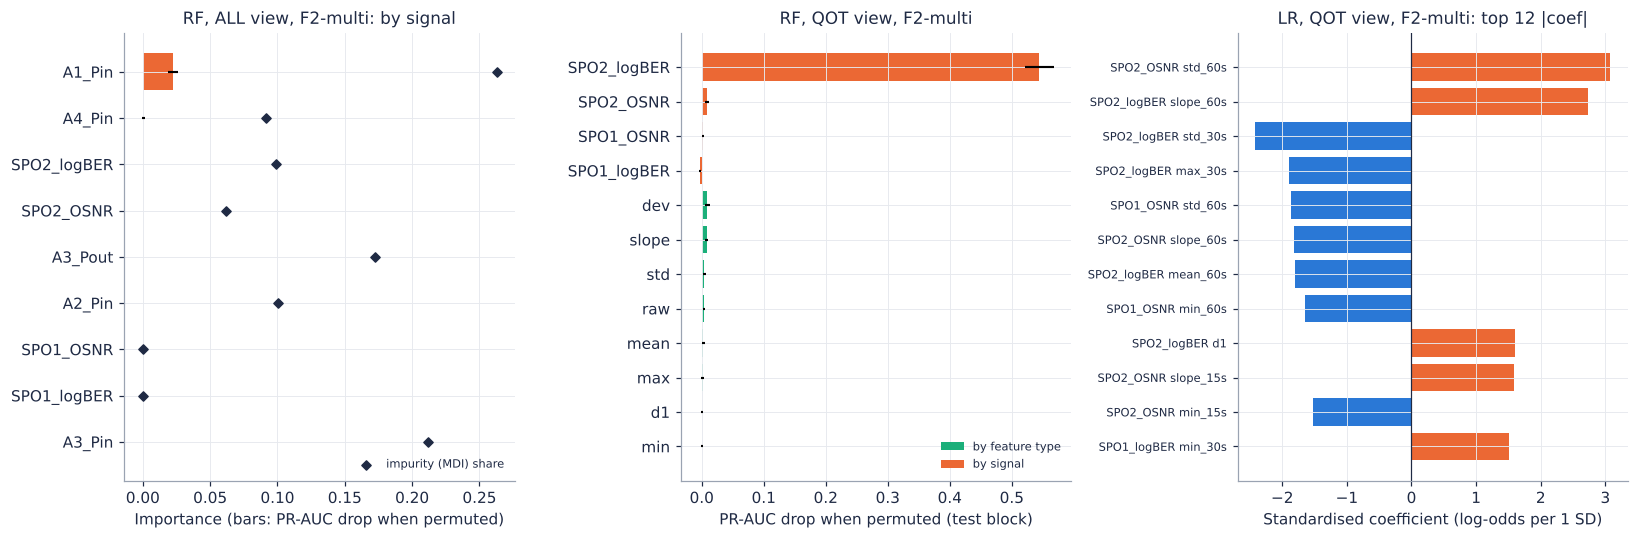

In [42]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
t1 = imp_tabs[('ALL', 'F2-multi', 'signal')].iloc[::-1]
axes[0].barh(t1['group'], t1['pr_auc_drop_mean'], xerr=t1['pr_auc_drop_sd'], color=PAL[1])
mdi = imp_tabs[('ALL', 'F2-multi', 'mdi')].set_index('group').loc[t1['group'], 'mdi_importance']
axes[0].scatter(mdi.values, range(len(mdi)), marker='D', color=NAVY, s=18, zorder=5, label='impurity (MDI) share')
axes[0].set_xlabel('Importance (bars: PR-AUC drop when permuted)')
axes[0].set_title('RF, ALL view, F2-multi: by signal')
axes[0].legend(fontsize=7.5, loc='lower right')
t2 = imp_tabs[('QOT', 'F2-multi', 'signal')].iloc[::-1]
t3 = imp_tabs[('QOT', 'F2-multi', 'type')].iloc[::-1]
axes[1].barh(list(t3['group']), t3['pr_auc_drop_mean'], xerr=t3['pr_auc_drop_sd'], color=PAL[2], label='by feature type')
axes[1].barh(list(t2['group']), t2['pr_auc_drop_mean'], xerr=t2['pr_auc_drop_sd'], color=PAL[1], label='by signal')
axes[1].set_xlabel('PR-AUC drop when permuted (test block)')
axes[1].set_title('RF, QOT view, F2-multi')
axes[1].legend(fontsize=7.5, loc='lower right')
c = lr_coef[(lr_coef['view'] == 'QOT') & (lr_coef['fset'] == 'F2-multi')].head(12).iloc[::-1]
axes[2].barh(c['feature'].str.replace('__', ' '), c['std_coef'], color=[PAL[1] if v > 0 else PAL[0] for v in c['std_coef']])
axes[2].axvline(0, color=NAVY, lw=0.8)
axes[2].set_xlabel('Standardised coefficient (log-odds per 1 SD)')
axes[2].set_title('LR, QOT view, F2-multi: top 12 |coef|')
axes[2].tick_params(axis='y', labelsize=7.5)
fig.tight_layout()
savefig(fig, 'fig16_feature_importance')
plt.show()

## 14. Inference cost
Training time (final fit on the training block, no tuning) and prediction time per 1,000 cycles,
median of 3 repetitions, single process unless stated (RF uses `n_jobs=1`).

In [43]:
cost_rows = []
for view, fs in [('QOT', 'F1'), ('QOT', 'F2-multi'), ('ALL', 'F1'), ('ALL', 'F2-multi')]:
    for mdl in MODELS:
        res = run_config('soft', 'T0', view, fs, mdl, FINAL_STRATEGY)
        Xtr = FEATS['soft'].iloc[res['idx']['train']][res['cols']].values
        ytr = res['y'][res['idx']['train']]
        Xte = FEATS['soft'].iloc[res['idx']['test']][res['cols']].values
        fits, preds = [], []
        for _ in range(3):
            est = clone(res['estimator'])
            t0 = time.perf_counter(); est.fit(Xtr, ytr); fits.append(time.perf_counter() - t0)
            t0 = time.perf_counter(); model_scores(est, Xte); preds.append(time.perf_counter() - t0)
        n_sv = int(est.steps[-1][1].n_support_.sum()) if mdl == 'SVM' else np.nan
        cost_rows.append({'view': view, 'fset': fs, 'model': mdl, 'n_features': len(res['cols']), 'train_cycles': len(ytr),
                          'fit_time_s': np.median(fits), 'predict_ms_per_1000': 1000 * np.median(preds) / len(Xte) * 1000,
                          'svm_support_vectors': n_sv})
# feature extraction cost for the whole soft dataset
t0 = time.perf_counter(); build_features(ALIGNED['soft'], SIGNALS['soft']); fe_s = time.perf_counter() - t0
cost = pd.DataFrame(cost_rows)
cost['feature_extraction_ms_per_1000_all_signals'] = 1000 * fe_s / len(ALIGNED['soft']) * 1000
save_table(cost, 'tab31_soft_inference_cost')
cost.round(4)

saved ../tables/tab31_soft_inference_cost.csv


,view,fset,model,n_features,train_cycles,fit_time_s,predict_ms_per_1000,svm_support_vectors,feature_extraction_ms_per_1000_all_signals
0,QOT,F1,LR,4,6514,0.0085,0.5337,NaN,10.549
1,QOT,F1,RF,4,6514,0.7007,17.6267,NaN,10.549
2,QOT,F1,SVM,4,2172,0.0093,3.9256,122.0,10.549
3,QOT,F2-multi,LR,80,6514,0.7114,0.9214,NaN,10.549
4,QOT,F2-multi,RF,80,6514,3.0167,15.3207,NaN,10.549
5,QOT,F2-multi,SVM,80,2172,0.0215,6.7162,89.0,10.549
6,ALL,F1,LR,9,6514,0.0083,0.5005,NaN,10.549
7,ALL,F1,RF,9,6514,0.3972,11.1295,NaN,10.549
8,ALL,F1,SVM,9,2172,0.0080,3.3922,87.0,10.549
9,ALL,F2-multi,LR,180,6514,0.2727,1.3485,NaN,10.549


## 15. Hard-failure dataset
### 15.1 Overview, regimes and label semantics
The second file contains 25 dB attenuation steps (hard failures) on top of random 0-18 dB
attenuation changes. We characterise the "normal" variable-attenuation regime (P2) as a potential
soft-degradation regime and check what the label does and does not mark.

saved ../tables/tab32_hard_regimes_and_label_semantics.csv


saved ../figures/fig17_hard_timeseries_overview.png


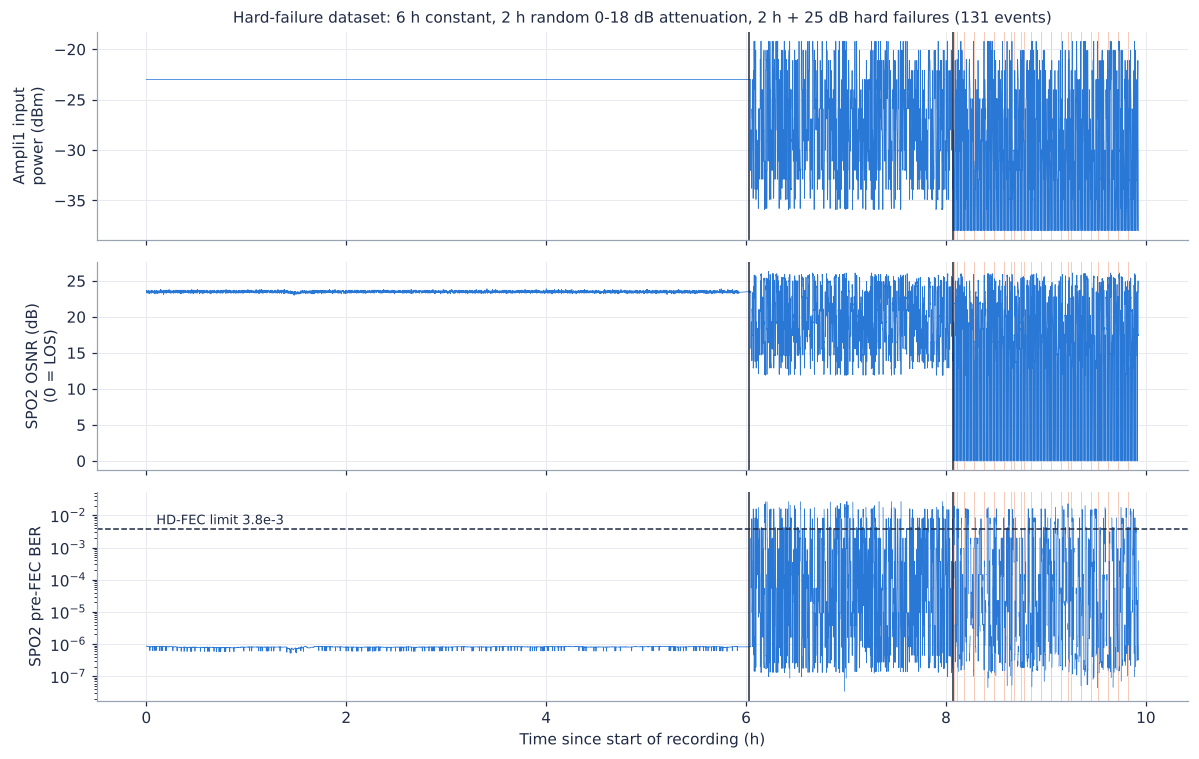

,period,label,cycles,A1_Pin_min,A1_Pin_max,OSNR_median,share_OSNR_3dB_below_P1,share_BER_ge_HD_FEC,share_LOS
0,"P1 normal, constant",normal,6605,-23.0,-23.0,23.5,0.0000,0.0000,0.0000
1,P2 variable attenuation (normal),normal,2279,-35.9,-19.2,19.4,0.5516,0.1781,0.0364
2,P3 periodic hard failures,normal,1655,-35.9,-19.2,18.3,0.6266,0.1390,0.2211
3,P3 periodic hard failures,failure,410,-38.0,-38.0,14.7,0.7366,0.0341,0.6927


In [44]:
A, ev = ALIGNED['hard'], EVENTS['hard']
calib = A[A['t'] < FAIL_START['hard']]
p1h = A[A['period'].str.startswith('P1')]
osnr_ref = p1h['SPO2_OSNR'].median()
reg_rows = []
for per, g in A.groupby('period', sort=False):
    for cls, gg in g.groupby('y'):
        reg_rows.append({'period': per, 'label': 'failure' if cls else 'normal', 'cycles': len(gg),
                         'A1_Pin_min': gg['A1_Pin'].min(), 'A1_Pin_max': gg['A1_Pin'].max(),
                         'OSNR_median': gg['SPO2_OSNR'].median(),
                         'share_OSNR_3dB_below_P1': round((gg['SPO2_OSNR'] <= osnr_ref - 3).mean(), 4),
                         'share_BER_ge_HD_FEC': round((gg['SPO2_BER'] >= FEC_HD).mean(), 4),
                         'share_LOS': round(gg['SPO2_LOS'].mean(), 4)})
reg = pd.DataFrame(reg_rows)
save_table(reg, 'tab32_hard_regimes_and_label_semantics')
SUMMARY['hard_P1_osnr_median'] = float(osnr_ref)

fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
h0 = A['t'].iloc[0]
axes[0].plot(A['hours'], A['A1_Pin'], color=PAL[0], lw=0.5)
axes[0].set_ylabel('Ampli1 input\npower (dBm)')
axes[1].plot(A['hours'], A['SPO2_OSNR'], color=PAL[0], lw=0.5)
axes[1].set_ylabel('SPO2 OSNR (dB)\n(0 = LOS)')
axes[2].semilogy(A['hours'], A['SPO2_BER'].where(A['SPO2_BER'] > 0), color=PAL[0], lw=0.5)
axes[2].axhline(FEC_HD, color=NAVY, ls='--', lw=1)
axes[2].text(0.1, FEC_HD * 1.4, 'HD-FEC limit 3.8e-3', fontsize=8.5)
axes[2].set_ylabel('SPO2 pre-FEC BER')
axes[2].set_xlabel('Time since start of recording (h)')
for ax in axes:
    shade_events(ax, ev, h0, alpha=0.35)
    for _, start in PERIODS['hard'][1:]:
        ax.axvline((start - h0) / 3600, color=NAVY, lw=1)
axes[0].set_title('Hard-failure dataset: 6 h constant, 2 h random 0-18 dB attenuation, 2 h + 25 dB hard failures '
                  '(131 events)', fontsize=10)
fig.tight_layout()
savefig(fig, 'fig17_hard_timeseries_overview')
plt.show()
reg

### 15.2 Detection, thresholds and event-level delay on the hard dataset
Same protocol as for the soft dataset (chronological split inside P3, embargo, TimeSeriesSplit tuning,
final imbalance strategy).

In [45]:
hard_rows = []
for view in ['ALL', 'NOA1', 'QOT']:
    for fs in ['F1', 'F2-multi']:
        for mdl in MODELS:
            res = run_config('hard', 'T0', view, fs, mdl, FINAL_STRATEGY)
            hard_rows.append(evaluate(res, 'test', FINAL_THR))
            print('hard', view, fs, mdl, res['params'], round(hard_rows[-1]['f1'], 4))
hard_det = pd.concat([pd.DataFrame(baseline_rows('hard', 'T0', 'test')), pd.DataFrame(hard_rows)], ignore_index=True)
save_table(hard_det[['view', 'fset', 'model', 'strategy', 'threshold', 'recall', 'precision', 'f1', 'f2', 'pr_auc', 'roc_auc',
                     'mcc', 'balanced_acc', 'accuracy', 'tp', 'fp', 'fn', 'tn', 'prevalence', 'params']],
           'tab33_hard_detection_test')
hev_rows, hper = [], {}
for nm in ['TH-FEC-HD', 'TH-QoT-99', 'TH-OSNR-3dB', 'TH-A1Pin-99']:
    pe, s = event_eval('hard', 'test', rule_scores('hard', nm)[1])
    hper[nm] = pe
    hev_rows.append({'detector': nm, **s})
for view, fs in [('QOT', 'F1'), ('QOT', 'F2-multi'), ('ALL', 'F1')]:
    for mdl in MODELS:
        pe, s = event_eval('hard', 'test', model_alarm('hard', run_config('hard', 'T0', view, fs, mdl, FINAL_STRATEGY)))
        hper[f'{mdl} {view} {fs}'] = pe
        hev_rows.append({'detector': f'{mdl} {view} {fs}', **s})
hev = pd.DataFrame(hev_rows)
save_table(hev, 'tab34_hard_event_level_test')
hard_det[['view', 'fset', 'model', 'recall', 'precision', 'f1', 'pr_auc', 'mcc', 'tp', 'fp', 'fn']].round(4)

hard ALL F1 LR {'clf__C': 10} 0.97


hard ALL F1 RF {'clf__max_depth': None, 'clf__min_samples_leaf': 1} 1.0


hard ALL F1 SVM {'clf__C': 10, 'clf__gamma': 0.1} 0.8889


hard ALL F2-multi LR {'clf__C': 0.1} 0.8832


hard ALL F2-multi RF {'clf__max_depth': None, 'clf__min_samples_leaf': 1} 0.9904


hard ALL F2-multi SVM {'clf__C': 10, 'clf__gamma': 0.0005} 0.844


... (9 outputs left out)

hard QOT F2-multi RF {'clf__max_depth': 12, 'clf__min_samples_leaf': 1} 0.8557


hard QOT F2-multi SVM {'clf__C': 10, 'clf__gamma': 0.001} 0.728
saved ../tables/tab33_hard_detection_test.csv


saved ../tables/tab34_hard_event_level_test.csv


,view,fset,model,recall,precision,f1,pr_auc,mcc,tp,fp,fn
0,-,-,Dummy,0.0000,0.0000,0.0000,0.2064,0.0000,0,0,103
1,QOT,F1,TH-FEC-HD,0.7670,0.3496,0.4802,0.4404,0.3218,79,147,24
2,QOT,F1,TH-FEC-SD,0.7184,0.4540,0.5564,0.4404,0.4261,74,89,29
3,QOT,F1,TH-BER-99,0.7184,0.4625,0.5627,0.4437,0.4347,74,86,29
4,QOT,F1,TH-OSNR-99,0.4757,0.3427,0.3984,0.3190,0.2134,49,94,54
5,QOT,F1,TH-QoT-99,0.7184,0.4134,0.5248,0.4435,0.3825,74,105,29
6,QOT,F1,TH-OSNR-3dB,0.7767,0.2623,0.3922,0.3190,0.1731,80,225,23
7,ALL,F1,TH-A1Pin-99,1.0000,0.8110,0.8957,1.0000,0.8729,103,24,0
8,ALL,F1,LR,0.9417,1.0000,0.9700,0.9994,0.9632,97,0,6
9,ALL,F1,RF,1.0000,1.0000,1.0000,1.0000,1.0000,103,0,0


In [46]:
hev.round(3)

,detector,events,detected,detection_rate,delay_median_s,delay_mean_s,delay_min_s,delay_max_s,false_alarm_episodes,false_alarm_episodes_per_h,false_alarm_cycles,monitored_h,alarm_rate_normal_cycles
0,TH-FEC-HD,32,32,1.000,3.0,2.375,0.0,4.0,27,64.930,73,0.416,0.371
1,TH-QoT-99,32,32,1.000,3.0,2.875,0.0,4.0,15,36.072,34,0.416,0.265
2,TH-OSNR-3dB,32,32,1.000,0.0,2.344,0.0,7.0,40,96.192,144,0.416,0.568
3,TH-A1Pin-99,32,32,1.000,0.0,0.000,0.0,0.0,4,9.619,12,0.416,0.061
4,LR QOT F1,32,28,0.875,3.0,2.857,0.0,4.0,6,14.429,14,0.416,0.162
5,RF QOT F1,32,32,1.000,3.0,2.875,0.0,4.0,6,14.429,12,0.416,0.172
6,SVM QOT F1,32,32,1.000,3.0,1.781,0.0,4.0,49,117.836,125,0.416,0.477
7,LR QOT F2-multi,32,32,1.000,0.0,0.812,0.0,4.0,16,38.477,21,0.416,0.081
8,RF QOT F2-multi,32,32,1.000,0.0,0.750,0.0,7.0,7,16.834,12,0.416,0.030
9,SVM QOT F2-multi,32,32,1.000,0.0,0.719,0.0,4.0,25,60.120,39,0.416,0.141


### 15.3 Hard-failure early warning (H = 10, 20 s), precursor test and degradation-as-risk analysis

In [47]:
hh_rows = []
for H in HORIZONS_HARD:
    task = f'H{H}'
    y, valid = make_target('hard', task)
    mt = SPLITS['hard']['test'] & valid
    hh_rows.append({**metrics_from(y[mt], np.zeros(mt.sum()), np.zeros(mt.sum())), 'H': H, 'view': '-', 'model': 'Dummy'})
    for view in ['QOT', 'ALL']:
        for mdl in MODELS:
            res = run_config('hard', task, view, 'F2-multi', mdl, FINAL_STRATEGY)
            r = evaluate(res, 'test', FINAL_THR)
            Ft = FEATS['hard'].iloc[np.where(SPLITS['hard']['test'])[0]][res['cols']].values
            th = res['thr_tuned'] if FINAL_THR == 'tuned' else res['thr_default']
            al = np.zeros(len(ALIGNED['hard']), bool)
            al[SPLITS['hard']['test']] = model_scores(res['estimator'], Ft) >= th
            _, s = event_eval('hard', 'test', al, mode='warn', H=H)
            hh_rows.append({**r, 'H': H, 'model': mdl, 'warned': s['warned'], 'events': s['events'],
                            'lead_median_s': s['lead_median_s'], 'fa_episodes_per_h': s['false_alarm_episodes_per_h']})
hh = pd.DataFrame(hh_rows)
save_table(hh[['H', 'view', 'model', 'prevalence', 'recall', 'precision', 'f1', 'pr_auc', 'roc_auc', 'mcc', 'warned', 'events',
               'lead_median_s', 'fa_episodes_per_h']], 'tab35_hard_horizon_test')
prec_hard = pd.concat([precursor_test(ALIGNED['hard'], EVENTS['hard'], SIGNALS['hard'], 10, FAIL_START['hard'], 0),
                       precursor_test(ALIGNED['hard'], EVENTS['hard'], SIGNALS['hard'], 10, FAIL_START['hard'], 5)],
                      ignore_index=True)
save_table(prec_hard, 'tab36_hard_precursor_test_10s')

# Does a degraded (soft) state precede hard failures?  Relative risk of an onset within H seconds.
A = ALIGNED['hard']
p3n = (A['t'].values >= FAIL_START['hard']) & (A['y'].values == 0) & (A['SPO2_LOS'].values == 0)
degraded = A['SPO2_OSNR'].values <= osnr_ref - OSNR_MARGIN_DB
ttn = time_to_next_onset(A, EVENTS['hard'])
rr_rows = []
for H in HORIZONS_HARD:
    soon = ttn <= H
    a = (soon & degraded & p3n).sum(); b = (degraded & p3n).sum()
    c = (soon & ~degraded & p3n).sum(); d = (~degraded & p3n).sum()
    rr_rows.append({'H': H, 'P(onset within H | degraded)': a / b, 'P(onset within H | not degraded)': c / d,
                    'relative_risk': (a / b) / (c / d), 'degraded_cycles': int(b), 'not_degraded_cycles': int(d)})
rr = pd.DataFrame(rr_rows)
save_table(rr, 'tab37_hard_degradation_relative_risk')
hh[['H', 'view', 'model', 'prevalence', 'recall', 'precision', 'pr_auc', 'roc_auc', 'warned', 'events', 'fa_episodes_per_h']].round(3)

saved ../tables/tab35_hard_horizon_test.csv
saved ../tables/tab36_hard_precursor_test_10s.csv
saved ../tables/tab37_hard_degradation_relative_risk.csv


,H,view,model,prevalence,recall,precision,pr_auc,roc_auc,warned,events,fa_episodes_per_h
0,10,-,Dummy,0.241,0.000,0.000,0.241,0.500,NaN,NaN,NaN
1,10,QOT,LR,0.241,0.842,0.879,0.942,0.975,29.0,32.0,24.048
2,10,QOT,RF,0.241,0.968,0.780,0.954,0.984,32.0,32.0,40.882
3,10,QOT,SVM,0.241,0.758,0.673,0.815,0.864,26.0,32.0,52.906
4,10,ALL,LR,0.241,0.758,0.837,0.867,0.922,26.0,32.0,26.453
5,10,ALL,RF,0.241,0.979,0.738,0.958,0.986,32.0,32.0,57.715
6,10,ALL,SVM,0.241,0.705,0.736,0.771,0.833,25.0,32.0,36.072
7,20,-,Dummy,0.471,0.000,0.000,0.471,0.500,NaN,NaN,NaN
8,20,QOT,LR,0.471,0.897,0.868,0.960,0.952,31.0,32.0,38.477
9,20,QOT,RF,0.471,1.000,0.889,0.986,0.989,32.0,32.0,48.096


In [48]:
rr

,H,P(onset within H | degraded),P(onset within H | not degraded),relative_risk,degraded_cycles,not_degraded_cycles
0,10,0.295588,0.285714,1.034559,680,609
1,20,0.582353,0.579639,1.004683,680,609


### 15.4 Secondary task: data-derived soft-degradation label (hard dataset)
Definition: a cycle is **soft-degraded** if it is not in a labelled hard failure, the receiver has a
valid reading (no LOS), and the SPO2 OSNR is at least 3 dB below the median of the 6 h constant
period P1 (fixed engineering margin; the k-sigma alternative is unusable because sigma in P1 is only
~0.1 dB). Cycles in hard failure or LOS are excluded. The model sees **amplifier telemetry only**
(view AMP: Ampli1-4 powers), so the label is not a function of its own inputs. Training/validation/test
blocks follow the same chronological split, and the training block also contains P1-P2.

In [49]:
A = ALIGNED['hard']
sd_label = ((A['SPO2_OSNR'].values <= osnr_ref - OSNR_MARGIN_DB)).astype(int)
sd_valid = (A['y'].values == 0) & (A['SPO2_LOS'].values == 0)
_orig_make_target = make_target


def make_target(k, task):   # extend with the soft-degradation task
    if task == 'SD':
        assert k == 'hard'
        return sd_label.copy(), sd_valid.copy()
    return _orig_make_target(k, task)


sd_rows = []
for part in ['train', 'val', 'test']:
    m = SPLITS['hard'][part] & sd_valid
    sd_rows.append({'partition': part, 'cycles': int(m.sum()), 'soft_degraded': int(sd_label[m].sum()),
                    'share': round(sd_label[m].mean(), 4)})
for fs in ['F1', 'F2-multi']:
    for mdl in MODELS:
        res = run_config('hard', 'SD', 'AMP', fs, mdl, FINAL_STRATEGY)
        r = evaluate(res, 'test', FINAL_THR)
        sd_rows.append({'partition': 'test result', 'fset': fs, 'model': mdl, **{k_: r[k_] for k_ in
                        ['recall', 'precision', 'f1', 'f2', 'pr_auc', 'roc_auc', 'mcc', 'balanced_acc', 'prevalence']},
                        'params': str(res['params'])})
# reference rule: amplifier power alarm at the soft-dataset failure level (Ampli1 Pin <= -29 dBm)
m = SPLITS['hard']['test'] & sd_valid
rule = (A['A1_Pin'].values <= -29.0).astype(int)
sd_rows.append({'partition': 'test result', 'fset': 'F1', 'model': 'rule A1_Pin <= -29 dBm',
                **{k_: v for k_, v in metrics_from(sd_label[m], -A['A1_Pin'].values[m], rule[m]).items()
                   if k_ in ['recall', 'precision', 'f1', 'f2', 'pr_auc', 'roc_auc', 'mcc', 'balanced_acc', 'prevalence']}})
sd_tab = pd.DataFrame(sd_rows)
save_table(sd_tab, 'tab38_hard_soft_degradation_task')
sd_tab.round(4)

saved ../tables/tab38_hard_soft_degradation_task.csv


,partition,cycles,soft_degraded,share,fset,model,recall,precision,f1,f2,pr_auc,roc_auc,mcc,balanced_acc,prevalence,params
0,train,9454.0,1517.0,0.1605,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,val,277.0,172.0,0.6209,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,test,307.0,139.0,0.4528,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,test result,NaN,NaN,NaN,F1,LR,1.0000,0.4557,0.6261,0.8072,0.6679,0.7411,0.0737,0.5060,0.4528,{'clf__C': 0.01}
4,test result,NaN,NaN,NaN,F1,RF,1.0000,0.4528,0.6233,0.8053,0.6645,0.7246,0.0000,0.5000,0.4528,"{'clf__max_depth': None, 'clf__min_samples_lea..."
5,test result,NaN,NaN,NaN,F1,SVM,0.9928,0.4585,0.6273,0.8051,0.6693,0.7340,0.0812,0.5113,0.4528,"{'clf__C': 0.1, 'clf__gamma': 0.02}"
6,test result,NaN,NaN,NaN,F2-multi,LR,0.9640,0.8590,0.9085,0.9410,0.9791,0.9820,0.8295,0.9165,0.4528,{'clf__C': 0.1}
7,test result,NaN,NaN,NaN,F2-multi,RF,0.9784,0.9444,0.9611,0.9714,0.9928,0.9930,0.9284,0.9654,0.4528,"{'clf__max_depth': 12, 'clf__min_samples_leaf'..."
8,test result,NaN,NaN,NaN,F2-multi,SVM,0.9784,0.7556,0.8527,0.9239,0.9761,0.9782,0.7242,0.8583,0.4528,"{'clf__C': 10, 'clf__gamma': 0.001}"
9,test result,NaN,NaN,NaN,F1,rule A1_Pin <= -29 dBm,0.5612,0.7027,0.6240,0.5847,0.6686,0.7401,0.3779,0.6824,0.4528,NaN


### 15.5 Benchmark against Silva et al. (2022)
Silva et al. split the hard-failure dataset chronologically 70/10/20 by record count with failures
only in the last 20 %, trained novelty detectors on normal data only, and flagged outliers with a
99 %-confidence static threshold on forecast errors; LSTNet detected 58 % of failure samples (351 of
857 missed) with ~5 false positives. Supervised models cannot be trained on that split (no failures
in training), so the like-for-like comparison is a **normal-only static-threshold detector** on the
same split: per-parameter two-sided 99 % intervals [0.5th, 99.5th percentile] of the first 70 % of
cycles; an alarm is raised if any monitored parameter leaves its interval. We report it for the
paper's own feature set (8 amplifier powers + receiver OSNR + 3 span-loss differences) and for
narrower views. Our supervised models (Section 15.2) use a different split and are listed for context.

In [50]:
A = ALIGNED['hard'].copy()
n = len(A)
i70, i80 = int(0.7 * n), int(0.8 * n)
A['span12'] = A['A1_Pout'] - A['A2_Pin']
A['span23'] = A['A2_Pout'] - A['A3_Pin']
A['span34'] = A['A3_Pout'] - A['A4_Pin']
paper_cols = ['A1_Pin', 'A1_Pout', 'A2_Pin', 'A2_Pout', 'A3_Pin', 'A3_Pout', 'A4_Pin', 'A4_Pout', 'SPO2_OSNR',
              'span12', 'span23', 'span34']
bench_sets = {'paper feature set (12)': paper_cols, 'all informative raw signals': SIGNALS['hard'],
              'receiver OSNR only (SPO2)': ['SPO2_OSNR'], 'receiver OSNR + BER (SPO2)': ['SPO2_OSNR', 'SPO2_logBER'],
              'Ampli1 input power only': ['A1_Pin']}
yb = A['y'].values
test_b = np.arange(n) >= i80
bench_rows = [{'detector': 'LSTNet (Silva et al., 2022, reported)', 'split': '70/10/20 by record', 'failure_samples': 857,
               'detected': 857 - 351, 'detection_rate': (857 - 351) / 857, 'false_positives': '~5 (avg.)'}]
for nm, cols in bench_sets.items():
    lo = A.iloc[:i70][cols].quantile(0.005)
    hi = A.iloc[:i70][cols].quantile(0.995)
    out = ((A[cols] < lo) | (A[cols] > hi)).any(axis=1).values
    tp = int((out & test_b & (yb == 1)).sum()); fp = int((out & test_b & (yb == 0)).sum())
    bench_rows.append({'detector': f'static 99% interval, {nm}', 'split': '70/10/20 by record',
                       'failure_samples': int((test_b & (yb == 1)).sum()), 'detected': tp,
                       'detection_rate': tp / max((test_b & (yb == 1)).sum(), 1), 'false_positives': fp,
                       'normal_test_cycles': int((test_b & (yb == 0)).sum())})
for _, r in hard_det[hard_det['model'].isin(MODELS) & (hard_det['fset'] == 'F2-multi')].iterrows():
    bench_rows.append({'detector': f"supervised {r['model']} ({r['view']}, F2-multi) - our split", 'split': 'P3 50/25/25 (Sec. 6)',
                       'failure_samples': r['tp'] + r['fn'], 'detected': r['tp'], 'detection_rate': r['recall'],
                       'false_positives': r['fp'], 'normal_test_cycles': r['tn'] + r['fp']})
bench = pd.DataFrame(bench_rows)
save_table(bench, 'tab39_benchmark_vs_silva2022')
SUMMARY['paper_split_test_start_utc'] = str(pd.to_datetime(A['t'].iloc[i80], unit='s'))
SUMMARY['paper_split_train_end_utc'] = str(pd.to_datetime(A['t'].iloc[i70 - 1], unit='s'))
bench

saved ../tables/tab39_benchmark_vs_silva2022.csv


,detector,split,failure_samples,detected,detection_rate,false_positives,normal_test_cycles
0,"LSTNet (Silva et al., 2022, reported)",70/10/20 by record,857,506,0.590432,~5 (avg.),NaN
1,"static 99% interval, paper feature set (12)",70/10/20 by record,410,410,1.000000,455,1780.0
2,"static 99% interval, all informative raw signals",70/10/20 by record,410,410,1.000000,505,1780.0
3,"static 99% interval, receiver OSNR only (SPO2)",70/10/20 by record,410,187,0.456098,408,1780.0
4,"static 99% interval, receiver OSNR + BER (SPO2)",70/10/20 by record,410,293,0.714634,438,1780.0
5,"static 99% interval, Ampli1 input power only",70/10/20 by record,410,410,1.000000,15,1780.0
6,"supervised LR (ALL, F2-multi) - our split",P3 50/25/25 (Sec. 6),103,87,0.844660,7,396.0
7,"supervised RF (ALL, F2-multi) - our split",P3 50/25/25 (Sec. 6),103,103,1.000000,2,396.0
8,"supervised SVM (ALL, F2-multi) - our split",P3 50/25/25 (Sec. 6),103,92,0.893204,23,396.0
9,"supervised LR (NOA1, F2-multi) - our split",P3 50/25/25 (Sec. 6),103,89,0.864078,12,396.0


## 16. Benchmark-style protocols (comparability with published results on the same data)
Published results on this dataset use protocols that differ from ours:
* a **default random forest** (scikit-learn defaults: 100 trees, no class weighting, threshold 0.5)
  with an undocumented split - we evaluate it under a random stratified 80/20 split (the most common
  undocumented default), a chronological 80/20 split by record count (no embargo), and our split;
* a **chronological 80/20 split** with Type I (false-positive rate, FP / normal cycles) and Type II
  (miss rate, FN / failure cycles) errors.
On the hard dataset the first 80 % of records end before the first hard failure (P3 starts at ~81 % of
the records), so supervised training on a chronological 80/20 split is impossible there.

In [51]:
def default_rf_eval(k, view, fs, protocol, seed):
    F = FEATS[k]
    cols = fset_columns(F, view_signals(k, view), fs)
    X, y = F[cols].values, ALIGNED[k]['y'].values
    n = len(y)
    if protocol == 'random stratified 80/20':
        tr, te = train_test_split(np.arange(n), test_size=0.2, stratify=y, random_state=seed, shuffle=True)
    elif protocol == 'chronological 80/20 (by record)':
        tr, te = np.arange(int(0.8 * n)), np.arange(int(0.8 * n), n)
        if y[tr].sum() == 0:
            return None
    elif protocol == 'our chronological split (Sec. 6)':
        tr, te = np.where(SPLITS[k]['train'])[0], np.where(SPLITS[k]['test'])[0]
    rf = RandomForestClassifier(random_state=seed, n_jobs=N_JOBS).fit(X[tr], y[tr])
    s = rf.predict_proba(X[te])[:, 1]
    return metrics_from(y[te], s, s >= 0.5)


bm_rows = []
for k in ['soft', 'hard']:
    for view, fs in [('ALL', 'F1'), ('NOA1', 'F1'), ('QOT', 'F1'), ('QOT', 'F2-multi')]:
        for protocol in ['random stratified 80/20', 'chronological 80/20 (by record)', 'our chronological split (Sec. 6)']:
            ms = [default_rf_eval(k, view, fs, protocol, sd) for sd in RF_SEEDS]
            if ms[0] is None:
                bm_rows.append({'dataset': k, 'view': view, 'fset': fs, 'protocol': protocol,
                                'note': 'not applicable: no failures in the first 80 % of records'})
                continue
            M = pd.DataFrame(ms)
            row = {'dataset': k, 'view': view, 'fset': fs, 'protocol': protocol, 'n_seeds': len(ms),
                   'test_cycles': int(M['n'].iloc[0]), 'test_prevalence': M['prevalence'].iloc[0]}
            for c in ['f1', 'recall', 'precision', 'pr_auc', 'mcc', 'type1_fpr', 'type2_fnr']:
                row[f'{c}_mean'] = M[c].mean()
                row[f'{c}_sd'] = M[c].std()
            bm_rows.append(row)
bm = pd.DataFrame(bm_rows)
save_table(bm, 'tab41_default_rf_benchmark_protocols')

# Our final tuned models on the chronological 80/20 split of the soft dataset (Type I / Type II errors)
r80 = []
F, A = FEATS['soft'], ALIGNED['soft']
n = len(A)
tr, te = np.arange(int(0.8 * n)), np.arange(int(0.8 * n), n)
for view, fs in [('ALL', 'F1'), ('QOT', 'F1'), ('QOT', 'F2-multi')]:
    for mdl in MODELS:
        res = run_config('soft', 'T0', view, fs, mdl, 'balanced')
        tr_m = thin_for_svm(tr, mdl)
        est = clone(res['estimator']).fit(F.iloc[tr_m][res['cols']].values, A['y'].values[tr_m])
        s = model_scores(est, F.iloc[te][res['cols']].values)
        r80.append({'view': view, 'fset': fs, 'model': mdl, 'strategy': 'balanced, default threshold',
                    **metrics_from(A['y'].values[te], s, s >= default_threshold(est))})
for nm in ['TH-QoT-99', 'TH-OSNR-3dB', 'TH-A1Pin-99']:
    s, al, _ = rule_scores('soft', nm)
    r80.append({'view': 'QOT' if 'A1' not in nm else 'ALL', 'fset': 'F1', 'model': nm, 'strategy': 'static rule',
                **metrics_from(A['y'].values[te], s[te], al[te])})
r80 = pd.DataFrame(r80)
SUMMARY['chrono8020_soft_test_start_utc'] = str(pd.to_datetime(A['t'].iloc[int(0.8 * n)], unit='s'))
save_table(r80[['view', 'fset', 'model', 'strategy', 'prevalence', 'n', 'recall', 'precision', 'f1', 'pr_auc', 'mcc',
                'type1_fpr', 'type2_fnr', 'tp', 'fp', 'fn', 'tn']], 'tab42_soft_chronological_8020_type1_type2')
bm.round(4)

saved ../tables/tab41_default_rf_benchmark_protocols.csv


saved ../tables/tab42_soft_chronological_8020_type1_type2.csv


,dataset,view,fset,protocol,n_seeds,test_cycles,test_prevalence,f1_mean,f1_sd,recall_mean,...,precision_sd,pr_auc_mean,pr_auc_sd,mcc_mean,mcc_sd,type1_fpr_mean,type1_fpr_sd,type2_fnr_mean,type2_fnr_sd,note
0,soft,ALL,F1,random stratified 80/20,5.0,1791.0,0.0955,0.9994,0.0013,1.0000,...,0.0026,1.0000,0.0000,0.9994,0.0014,0.0001,0.0003,0.0000,0.0000,NaN
1,soft,ALL,F1,chronological 80/20 (by record),5.0,1791.0,0.1664,0.9990,0.0009,1.0000,...,0.0018,1.0000,0.0000,0.9988,0.0011,0.0004,0.0004,0.0000,0.0000,NaN
2,soft,ALL,F1,our chronological split (Sec. 6),5.0,1373.0,0.1624,0.9978,0.0000,1.0000,...,0.0000,1.0000,0.0000,0.9973,0.0000,0.0009,0.0000,0.0000,0.0000,NaN
3,soft,NOA1,F1,random stratified 80/20,5.0,1791.0,0.0955,0.9965,0.0013,0.9965,...,0.0032,0.9999,0.0001,0.9961,0.0015,0.0004,0.0003,0.0035,0.0052,NaN
4,soft,NOA1,F1,chronological 80/20 (by record),5.0,1791.0,0.1664,0.9983,0.0000,1.0000,...,0.0000,0.9985,0.0018,0.9980,0.0000,0.0007,0.0000,0.0000,0.0000,NaN
5,soft,NOA1,F1,our chronological split (Sec. 6),5.0,1373.0,0.1624,0.9978,0.0000,1.0000,...,0.0000,0.9971,0.0024,0.9973,0.0000,0.0009,0.0000,0.0000,0.0000,NaN
6,soft,QOT,F1,random stratified 80/20,5.0,1791.0,0.0955,0.9131,0.0139,0.9216,...,0.0157,0.8733,0.0265,0.9039,0.0154,0.0102,0.0018,0.0784,0.0147,NaN
7,soft,QOT,F1,chronological 80/20 (by record),5.0,1791.0,0.1664,0.9120,0.0010,0.9114,...,0.0002,0.8835,0.0060,0.8945,0.0012,0.0174,0.0000,0.0886,0.0018,NaN
8,soft,QOT,F1,our chronological split (Sec. 6),5.0,1373.0,0.1624,0.9283,0.0034,0.9345,...,0.0024,0.8866,0.0060,0.9143,0.0041,0.0153,0.0005,0.0655,0.0051,NaN
9,soft,QOT,F2-multi,random stratified 80/20,5.0,1791.0,0.0955,0.9681,0.0056,0.9404,...,0.0034,0.9722,0.0076,0.9653,0.0060,0.0002,0.0003,0.0596,0.0105,NaN


In [52]:
r80[['view', 'fset', 'model', 'recall', 'precision', 'f1', 'type1_fpr', 'type2_fnr']].round(4)

,view,fset,model,recall,precision,f1,type1_fpr,type2_fnr
0,ALL,F1,LR,1.0000,0.9967,0.9983,0.0007,0.0000
1,ALL,F1,RF,1.0000,0.9967,0.9983,0.0007,0.0000
2,ALL,F1,SVM,1.0000,0.9967,0.9983,0.0007,0.0000
3,QOT,F1,LR,0.9362,0.8914,0.9133,0.0228,0.0638
4,QOT,F1,RF,0.9295,0.9023,0.9157,0.0201,0.0705
5,QOT,F1,SVM,0.9362,0.8885,0.9118,0.0234,0.0638
6,QOT,F2-multi,LR,0.9396,0.9722,0.9556,0.0054,0.0604
7,QOT,F2-multi,RF,0.9329,1.0000,0.9653,0.0000,0.0671
8,QOT,F2-multi,SVM,0.9396,0.9722,0.9556,0.0054,0.0604
9,QOT,F1,TH-QoT-99,0.9396,0.8092,0.8696,0.0442,0.0604


## 17. Save the run summary

In [53]:
SUMMARY['final_threshold_mode'] = FINAL_THR
SUMMARY['tuned_params_soft_T0'] = {f'{v}|{f}|{m}|{s}': str(run_config('soft', 'T0', v, f, m, s)['params'])
                                   for (k_, ta, v, f, m, s, sd, p, tp) in list(CACHE.keys())
                                   if k_ == 'soft' and ta == 'T0' and sd == SEED and p == 'None'}
SUMMARY['tuned_params_all'] = [{'dataset': r['dataset'], 'task': r['task'], 'view': r['view'], 'fset': r['fset'],
                                'model': r['model'], 'strategy': r['strategy'], 'params': str(r['params']),
                                'cv_pr_auc': None if np.isnan(r['cv_pr_auc']) else round(float(r['cv_pr_auc']), 4),
                                'thr_tuned': round(float(r['thr_tuned']), 5)}
                               for key, r in CACHE.items() if r['seed'] == SEED and key[7] == 'None']
pd.DataFrame(SUMMARY['tuned_params_all']).to_csv(TAB_DIR / 'tab40_tuned_hyperparameters.csv', index=False)
with open(TAB_DIR / 'results_summary.json', 'w') as fh:
    json.dump(SUMMARY, fh, indent=1, default=str)
print('configurations fitted:', len(CACHE))
SUMMARY['total_runtime_min'] = round((time.perf_counter() - T_START) / 60, 2)
with open(TAB_DIR / 'results_summary.json', 'w') as fh:
    json.dump(SUMMARY, fh, indent=1, default=str)
print('total runtime (min):', SUMMARY['total_runtime_min'])
print(json.dumps({k: v for k, v in SUMMARY.items() if k not in ('tuned_params_all', 'tuned_params_soft_T0')},
                 indent=1, default=str)[:3000])

configurations fitted: 133
total runtime (min): 15.79
{
 "dataset_commit": "7f0e9c0617fdde7f087de7214f38312ff7aaefd4 2022-02-16 10:13:30 +0100",
 "soft_rows": 53697,
 "soft_span_h": 8.025,
 "hard_rows": 65733,
 "hard_span_h": 9.925,
 "soft_label_pin_levels": [
  -29.1,
  -29.0
 ],
 "soft_lowest_normal_pin": -28.8,
 "hard_label_pin_levels": [
  -38.0
 ],
 "hard_lowest_normal_pin": -35.9,
 "soft_aligned_cycles": 8953,
 "soft_failure_cycles": 854,
 "soft_flag_agreement": {
  "SPO1": 0.996,
  "SPO2": 0.9955,
  "A1": 1.0,
  "A2": 0.9999,
  "A3": 0.996,
  "A4": 0.9996
 },
 "hard_aligned_cycles": 10949,
 "hard_failure_cycles": 410,
 "hard_flag_agreement": {
  "SPO1": 0.9869,
  "SPO2": 0.9848,
  "A1": 1.0,
  "A2": 0.9996,
  "A3": 0.9879,
  "A4": 0.9932
 },
 "soft_cycle_dt": {
  "median": 3.0,
  "mean": 3.227,
  "max": 13.0,
  "share_3s": 0.779,
  "share_4s": 0.219
 },
 "hard_cycle_dt": {
  "median": 3.0,
  "mean": 3.264,
  "max": 361.0,
  "share_3s": 0.778,
  "share_4s": 0.22
 },
 "soft_calib_